---
## UBPD v34 — K-Fold Cross Validation (Google Colab Pro)

### Requisitos
- Google Colab Pro (V100 / A100)
- Dataset subido a Google Drive: `Mi unidad/ubpd_dataset/`
- Ejecutar las celdas **en orden**



In [ ]:
# ============================================================
# PASO 1 — Montar Google Drive
# ============================================================
from google.colab import drive
drive.mount('/content/drive')
print('Drive montado ✅')

# ============================================================
# PASO 2 — Instalar dependencias
# ============================================================
!pip install -q segmentation-models-pytorch albumentations scikit-learn

# ============================================================
# PASO 3 — Copiar dataset de Drive a /content/ (SSD local)
# ============================================================
# IMPORTANTE: Google Drive tiene latencia de red alta (~10-50ms por archivo).
# Con ~955 imágenes + 955 JSONs, leer directo de Drive hace que las celdas
# de estadísticas y el DataLoader del entrenamiento sean muy lentos.
#
# Copiarlo a /content/ (SSD NVMe local de Colab) tarda ~2-3 min UNA SOLA VEZ
# pero hace todo lo demás 10-20x más rápido.
# ============================================================

import os, shutil, time

DRIVE_DATASET = '/content/drive/MyDrive/ubpd_dataset'   # origen en Drive
LOCAL_DATASET = '/content/ubpd_dataset'                  # destino local (SSD)

if os.path.isdir(LOCAL_DATASET):
    n = sum(1 for f in os.listdir(f'{LOCAL_DATASET}/train/JPEGImages') if f.endswith('.jpg'))
    print(f'Dataset ya está en /content/ ({n} imágenes) ✅ — omitiendo copia')
else:
    print('Copiando dataset de Drive a /content/ubpd_dataset ...')
    t0 = time.time()
    shutil.copytree(DRIVE_DATASET, LOCAL_DATASET)
    elapsed = time.time() - t0
    n = sum(1 for f in os.listdir(f'{LOCAL_DATASET}/train/JPEGImages') if f.endswith('.jpg'))
    print(f'Copia completada en {elapsed:.0f}s — {n} imágenes ✅')

# ---- Verificación de dependencias ----
import importlib
checks = [
    ('torch',                        'torch'),
    ('torchvision',                  'torchvision'),
    ('segmentation_models_pytorch',  'segmentation-models-pytorch'),
    ('albumentations',               'albumentations'),
    ('cv2',                          'opencv-python'),
    ('sklearn',                      'scikit-learn'),
    ('scipy',                        'scipy'),
    ('numpy',                        'numpy'),
]
all_ok = True
for module, display_name in checks:
    try:
        mod = importlib.import_module(module)
        print(f'  ✅ {display_name}: {getattr(mod, "__version__", "ok")}')
    except ImportError:
        print(f'  ❌ {display_name}: NO INSTALADO')
        all_ok = False
print('\n✅ Listo. Continúa.' if all_ok else '\n⚠️  Dependencias faltantes.')

Mounted at /content/drive
Drive montado ✅
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.8/154.8 kB 8.0 MB/s eta 0:00:00
Copiando dataset de Drive a /content/ubpd_dataset ...
Copia completada en 64s — 955 imágenes ✅
  ✅ torch: 2.10.0+cu128
  ✅ torchvision: 0.25.0+cu128
  ✅ segmentation-models-pytorch: 0.5.0
  ✅ albumentations: 2.0.8
  ✅ opencv-python: 4.13.0
  ✅ scikit-learn: 1.6.1
  ✅ scipy: 1.16.3
  ✅ numpy: 2.0.2

✅ Listo. Continúa.


# UBPD v34 — K-Fold Cross Validation
**UNet++ ResNet-34 | BoundaryLoss | SWA | TTA (h-flip) | GroupKFold por paciente | threshold=0.5 fijo**


---
## 1. Imports y Dependencias
*PyTorch · SMP · Albumentations · OpenCV · scikit-learn*

In [ ]:
import os, sys, json, time, random, gc, warnings, csv
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
from collections import defaultdict
from pathlib import Path

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader

import segmentation_models_pytorch as smp
import albumentations as A
from albumentations.pytorch import ToTensorV2
from sklearn.model_selection import GroupKFold   # v34: GroupKFold garantiza separación por paciente
from torch.optim.swa_utils import AveragedModel, SWALR, update_bn
from scipy.ndimage import label as scipy_label
from scipy.ndimage import distance_transform_edt
from scipy.spatial.distance import directed_hausdorff, cdist   # cdist: para HD95 real

print(f'PyTorch: {torch.__version__}')
print(f'SMP: {smp.__version__}')
print(f'CUDA: {torch.cuda.is_available()}')
if torch.cuda.is_available():
    print(f'GPU: {torch.cuda.get_device_name(0)}')


PyTorch: 2.10.0+cu128
SMP: 0.5.0
CUDA: True
GPU: NVIDIA A100-SXM4-80GB


---
## 2. Hiperparámetros y Configuración
*Semilla, tamaño de imagen, K-Fold, LR, EMA, paths, clases UBPD*

In [ ]:

# ============================================================
# Hiperparámetros y Configuración — UBPD v34 (Google Colab Pro)
# UNet++ ResNet-34 + scSE | BoundaryLoss | SWA | TTA (hflip) | Label Smoothing
# Cambios v33→v34:
#   - GroupKFold explícito para garantizar separación por paciente
#   - mean/std calculados SOLO sobre train del fold (sin fallback a globales)
#   - threshold=0.5 fijo (sin búsqueda de threshold óptimo ni TempScaling)
#   - EMA mantenido (estabiliza entrenamiento)
#   - TempScaling eliminado (sobreajusta calibración con pocos pacientes)
#   - PCT eliminado (threshold fijo es más reproducible y defendible)
#   - Reporte: Dice por fold + media ± std al final (no "best model")
# ============================================================

import os
import json
import random
import gc
import time
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

# Semilla global para reproducibilidad completa del experimento
SEED = 42

# ---- Configuración de entrenamiento ----
N_FOLDS = 5           # Número de folds en GroupKFold CV (split a nivel de paciente)
NUM_EPOCHS = 400      # Máximo de épocas por fold (A100: ~6-8h para 5 folds completos)
BATCH_SIZE = 16       # A100 (40 GB VRAM): batch 16 usa ~20-25 GB con AMP a 384×384
LEARNING_RATE = 3e-4  # LR del decoder (cabeza de segmentación)
ENCODER_LR = 3e-5     # LR del encoder ResNet (10x menor para fine-tuning estable)
WEIGHT_DECAY = 1e-4   # Regularización L2 en AdamW
ACCUMULATION_STEPS = 1  # Sin accumulation: batch real=16 ya es el batch efectivo
GRAD_CLIP_NORM = 1.0  # Clipping de gradientes para estabilidad numérica
IMAGE_SIZE = 384      # Resolución de entrada en píxeles (384×384)
USE_AMP = True        # Precisión mixta FP16/FP32 (requiere GPU CUDA)
NUM_WORKERS = 4       # A100 Colab Pro tiene más CPUs disponibles

# ---- EMA (Exponential Moving Average) — mantenido v34 ----
# EMA estabiliza el entrenamiento promediando pesos históricos.
USE_EMA = True
EMA_DECAY = 0.999

# ---- Early Stopping basado en Media Móvil ----
EARLY_STOP_PATIENCE = 50
EARLY_STOP_MIN_DELTA = 1e-4
MA_PATIENCE_WINDOW = 10

# ---- Freeze del Encoder ----
FREEZE_ENCODER_EPOCHS = 5

# ---- Mixup Data Augmentation ----
MIXUP_PROB = 0.3
MIXUP_ALPHA = 0.4

# ---- SWA (Stochastic Weight Averaging) ----
SWA_START_EPOCH = 40
SWA_LR_FACTOR = 0.3

# ---- Label Smoothing ----
LABEL_SMOOTH = 0.05

# ---- FocalTversky: parámetros alpha/beta por clase ----
ALPHA_PER_CLASS = [0.65, 0.40, 0.35, 0.30]  # [nerve, muscle, artery, vein]
BETA_PER_CLASS  = [0.35, 0.60, 0.65, 0.70]
FOCAL_TVERSKY_GAMMA = 0.75

# ---- Pesos de la función de pérdida combinada ----
LOSS_FT_W = 0.50
LOSS_BCE_W = 0.30
LOSS_BOUNDARY_W = 0.20

# ---- TTA (Test-Time Augmentation) ----
# v34: solo hflip — threshold=0.5 fijo para reproducibilidad
TTA_MODES = ['original', 'hflip']

# ---- Threshold fijo — v34 ----
# threshold=0.5 garantiza reproducibilidad y comparabilidad entre folds.
# No se usa búsqueda de threshold óptimo ni TempScaling.
EVAL_THRESHOLD = 0.5

# ---- Clases del dataset UBPD ----
CLASS_LABELS = {
    'shenjing':    0,   # nervio
    'jirouzuzhi':  1,   # músculo
    'dongmai':     2,   # arteria
    'jingmai':     3,   # vena
}
CLASS_NAMES = ['nerve', 'muscle', 'artery', 'vein']
NUM_CLASSES = len(CLASS_LABELS)
IN_CHANNELS = 1
IGNORE_LABELS = ['jizhu', 'zhifang']

# ============================================================
# Paths — Google Drive
# ============================================================
IMAGES_DIR      = '/content/ubpd_dataset/train/JPEGImages'
ANNOTATIONS_DIR = '/content/ubpd_dataset/train_mask/json_train'
CHECKPOINT_DIR  = '/content/drive/MyDrive/ubpd_v34/checkpoints'
RESULTS_DIR     = '/content/drive/MyDrive/ubpd_v34/results'
os.makedirs(CHECKPOINT_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)

# ---- Configuración del modelo: UNet++ con encoder ResNet-34 + scSE attention ----
MODEL_NAME = 'unetpp_r34_scse'
MODEL_CONFIG = {
    'name': MODEL_NAME,
    'arch': 'UnetPlusPlus',
    'encoder': 'resnet34',
    'weights': 'imagenet',
    'attention': 'scse',
    'decoder_dropout_rate': 0.30,
    'desc': 'UNet++ (ResNet-34 + scSE, decoder_dropout=0.30)',
    'class_weight_mode': 'sqrt',
}

def set_seed(seed=SEED):
    """Fija la semilla global en todas las librerías para reproducibilidad."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = False
    torch.backends.cudnn.benchmark = True
set_seed(SEED)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

print(f'Dispositivo: {DEVICE}')
print(f'Modelo: {MODEL_NAME} (ResNet-34 + scSE, decoder_dropout=0.30)')
print(f'K-Folds: {N_FOLDS} | Epochs máx: {NUM_EPOCHS}')
print(f'Early stop patience: {EARLY_STOP_PATIENCE}')
print(f'SWA activo en las últimas {SWA_START_EPOCH} epochs de cada fold')
print(f'TTA modes: {TTA_MODES}')
print(f'Threshold: FIJO={EVAL_THRESHOLD} (sin búsqueda de threshold óptimo, sin TempScaling)')
print(f'EMA: USE_EMA={USE_EMA}, decay={EMA_DECAY}')
print(f'Loss: FT={LOSS_FT_W} + BCE={LOSS_BCE_W} + Boundary={LOSS_BOUNDARY_W}')
print(f'IMAGES_DIR:      {IMAGES_DIR}')
print(f'ANNOTATIONS_DIR: {ANNOTATIONS_DIR}')
print(f'CHECKPOINT_DIR:  {CHECKPOINT_DIR}')
print(f'RESULTS_DIR:     {RESULTS_DIR}')

if os.path.isdir(IMAGES_DIR):
    n_imgs = len([f for f in os.listdir(IMAGES_DIR) if f.endswith('.jpg')])
    print(f'\n✅ Dataset encontrado: {n_imgs} imágenes en {IMAGES_DIR}')
else:
    print(f'\n❌ Dataset NO encontrado en {IMAGES_DIR}')
    print('   Sigue los pasos de la guía para subir el dataset a Drive.')


Dispositivo: cuda
Modelo: unetpp_r34_scse (ResNet-34 + scSE, decoder_dropout=0.30)
K-Folds: 5 | Epochs máx: 400
Early stop patience: 50
SWA activo en las últimas 40 epochs de cada fold
TTA modes: ['original', 'hflip']
Threshold: FIJO=0.5 (sin búsqueda de threshold óptimo, sin TempScaling)
EMA: USE_EMA=True, decay=0.999
Loss: FT=0.5 + BCE=0.3 + Boundary=0.2
IMAGES_DIR:      /content/ubpd_dataset/train/JPEGImages
ANNOTATIONS_DIR: /content/ubpd_dataset/train_mask/json_train
CHECKPOINT_DIR:  /content/drive/MyDrive/ubpd_v34/checkpoints
RESULTS_DIR:     /content/drive/MyDrive/ubpd_v34/results

✅ Dataset encontrado: 955 imágenes en /content/ubpd_dataset/train/JPEGImages


---
## 3. Carga de Datos
*Escanea `JPEGImages/` y `json_train/`, agrupa imágenes por ID de paciente*

In [ ]:
# ============================================================
# Carga de pares imagen-anotación + patient IDs
# ============================================================

def load_json_safe(path):
    """Carga JSON con fallback a latin-1. Solo captura UnicodeDecodeError
    para no enmascarar JSONDecodeError (JSON corrupto daría datos incorrectos)."""
    try:
        with open(path, 'r', encoding='utf-8') as f:
            return json.load(f)
    except UnicodeDecodeError:
        with open(path, 'r', encoding='latin-1') as f:
            return json.load(f)

image_files = sorted([f for f in os.listdir(IMAGES_DIR) if f.endswith('.jpg')])
data_pairs = []
for img_file in image_files:
    json_file = img_file.replace('.jpg', '.json')
    json_path = os.path.join(ANNOTATIONS_DIR, json_file)
    if os.path.exists(json_path):
        data_pairs.append({
            'image_path': os.path.join(IMAGES_DIR, img_file),
            'annotation_path': json_path,
            'name': img_file.replace('.jpg', ''),
        })

print(f'Total de pares imagen-anotación: {len(data_pairs)}')

def get_patient_id(img_path):
    fname = os.path.basename(img_path)
    parts = fname.replace('.jpg', '').split('_')
    return parts[0] if len(parts) >= 1 else fname

patient_to_pairs = defaultdict(list)
for pair in data_pairs:
    pid = get_patient_id(pair['image_path'])
    patient_to_pairs[pid].append(pair)

patients = sorted(patient_to_pairs.keys())
n_patients = len(patients)
print(f'Total de pacientes: {n_patients}')
print(f'Imgs por paciente (promedio): {len(data_pairs)/n_patients:.1f}')


Total de pares imagen-anotación: 955
Total de pacientes: 88
Imgs por paciente (promedio): 10.9


---
## 4. Generación de Máscaras Multiclase
*LabelMe JSON → tensor [C, H, W] · Filtra `shape_type='polygon'` (fix bug etiquetas)*

In [ ]:
# ============================================================
# Generación de máscaras — filtro shape_type='polygon'
# Previene el bug de etiquetas (puntos/rectángulos como polígonos)
# ============================================================

def json_to_multiclass_mask(json_path, height, width):
    """Convierte JSON LabelMe a máscara multiclase [C, H, W].
    Filtra por shape_type='polygon' para evitar bug de etiquetas.
    """
    data = load_json_safe(json_path)
    mask = np.zeros((NUM_CLASSES, height, width), dtype=np.float32)
    for shape in data.get('shapes', []):
        label = shape.get('label', '')
        shape_type = shape.get('shape_type', 'polygon')
        if label in IGNORE_LABELS or label not in CLASS_LABELS:
            continue
        if shape_type != 'polygon':
            continue
        class_idx = CLASS_LABELS[label]
        points = np.array(shape['points'], dtype=np.int32)
        if len(points) >= 3:
            temp = np.zeros((height, width), dtype=np.uint8)
            cv2.fillPoly(temp, [points], 1)
            mask[class_idx] = np.maximum(mask[class_idx], temp.astype(np.float32))
    return mask

print('json_to_multiclass_mask definida (shape_type=polygon filter) ✅')


json_to_multiclass_mask definida (shape_type=polygon filter) ✅


---
## 5. Dataset y Augmentaciones
*`UBPDDataset` · HFlip, ShiftScaleRotate, ElasticTransform, CLAHE, CoarseDropout, augmentaciones US*

In [ ]:
# ============================================================
# Dataset UBPD y Pipeline de Augmentaciones — v34
# ============================================================
# IMPORTANTE v34: get_train_transform y get_val_transform
# requieren mean y std explícitos calculados sobre el train del fold.
# NO hay fallback a globales — si mean/std son None lanza ValueError.
# Esto garantiza que NUNCA se usen estadísticas globales en entrenamiento.
# ============================================================

class UBPDDataset(Dataset):
    """Dataset de segmentación para ultrasonido de nervio periférico.

    Cada muestra es un par (imagen grayscale, máscara multiclase).
    La máscara tiene shape [C, H, W] con C=4 clases (nervio, músculo,
    arteria, vena). Las máscaras se generan desde JSON LabelMe.
    """
    def __init__(self, pairs, transform=None):
        self.pairs = pairs
        self.transform = transform

    def __len__(self):
        return len(self.pairs)

    def __getitem__(self, idx):
        pair = self.pairs[idx]
        img = cv2.imread(pair['image_path'], cv2.IMREAD_GRAYSCALE)
        h, w = img.shape[:2]
        mask = json_to_multiclass_mask(pair['annotation_path'], h, w)
        mask_hwc = mask.transpose(1, 2, 0)  # [C,H,W] → [H,W,C] para Albumentations

        if self.transform:
            augmented = self.transform(image=img, mask=mask_hwc)
            img = augmented['image']
            mask_hwc = augmented['mask']

        if isinstance(mask_hwc, np.ndarray):
            mask_t = torch.from_numpy(mask_hwc.transpose(2, 0, 1))
        else:
            mask_t = mask_hwc.permute(2, 0, 1)

        return img, mask_t.float()

# ---- Augmentaciones específicas de ultrasonido ----

def _speckle_noise(image, **kwargs):
    """Ruido de speckle multiplicativo: simula interferencia coherente del US."""
    noise = np.random.randn(*image.shape).astype(np.float32)
    out = image.astype(np.float32) * (1.0 + 0.15 * noise)
    return np.clip(out, 0, 255).astype(np.uint8)

def _depth_attenuation(image, **kwargs):
    """Atenuación acústica con la profundidad."""
    h = image.shape[0]
    min_factor = np.random.uniform(0.5, 0.85)
    factor = np.linspace(1.0, min_factor, h).astype(np.float32)[:, None]
    out = image.astype(np.float32) * factor
    return np.clip(out, 0, 255).astype(np.uint8)

def _shadow_artifact(image, **kwargs):
    """Sombras acústicas: columnas oscuras bajo estructuras densas."""
    img = image.copy().astype(np.float32)
    w = img.shape[1]
    for _ in range(np.random.randint(1, 3)):
        x = np.random.randint(0, w)
        sw = np.random.randint(3, 15)
        x0, x1 = max(0, x - sw // 2), min(w, x + sw // 2)
        img[:, x0:x1] *= np.random.uniform(0.2, 0.5)
    return np.clip(img, 0, 255).astype(np.uint8)

def get_train_transform(image_size=IMAGE_SIZE, mean=None, std=None):
    """Pipeline de augmentación para entrenamiento.

    REQUERIDO: mean y std calculados sobre el train del fold actual.
    NO acepta None — lanza ValueError para evitar uso accidental de globales.
    """
    if mean is None or std is None:
        raise ValueError(
            "mean/std no pueden ser None en get_train_transform. "
            "Calcula compute_fold_stats(train_pairs_fold) antes de crear los transforms. "
            "v34: se prohíbe el fallback a estadísticas globales para evitar data leakage.")
    return A.Compose([
        A.Resize(image_size, image_size),
        A.HorizontalFlip(p=0.5),
        A.ShiftScaleRotate(
            shift_limit=0.1, scale_limit=0.15, rotate_limit=20,
            border_mode=cv2.BORDER_CONSTANT, p=0.7),
        A.ElasticTransform(alpha=40, sigma=6, p=0.3, border_mode=cv2.BORDER_CONSTANT),
        A.GridDistortion(num_steps=5, distort_limit=0.3, p=0.3, border_mode=cv2.BORDER_CONSTANT),
        A.RandomBrightnessContrast(brightness_limit=0.3, contrast_limit=0.3, p=0.5),
        A.RandomGamma(gamma_limit=(75, 125), p=0.3),
        A.Lambda(image=_speckle_noise, p=0.4),
        A.Lambda(image=_depth_attenuation, p=0.3),
        A.Lambda(image=_shadow_artifact, p=0.2),
        A.GaussNoise(var_limit=(10.0, 50.0), p=0.3),
        A.CLAHE(clip_limit=2.0, tile_grid_size=(8, 8), p=0.4),
        A.GaussianBlur(blur_limit=(3, 5), p=0.2),
        A.Sharpen(alpha=(0.1, 0.3), lightness=(0.5, 1.0), p=0.1),
        A.CoarseDropout(
            max_holes=8,
            max_height=int(image_size * 0.04),
            max_width=int(image_size * 0.04),
            min_holes=3,
            min_height=int(image_size * 0.01),
            min_width=int(image_size * 0.01),
            fill_value=0, p=0.3),
        A.Normalize(mean=[mean], std=[std]),
        ToTensorV2(),
    ])

def get_val_transform(image_size=IMAGE_SIZE, mean=None, std=None):
    """Transform para validación/evaluación: solo resize y normalización.

    REQUERIDO: mean y std calculados sobre el train del fold actual.
    NO acepta None — lanza ValueError para evitar uso accidental de globales.
    """
    if mean is None or std is None:
        raise ValueError(
            "mean/std no pueden ser None en get_val_transform. "
            "Usa el fold_mean/fold_std guardado en all_fold_histories. "
            "v34: se prohíbe el fallback a estadísticas globales para evitar data leakage.")
    return A.Compose([
        A.Resize(image_size, image_size),
        A.Normalize(mean=[mean], std=[std]),
        ToTensorV2(),
    ])

print('UBPDDataset y transforms definidos ✅')
print('  v34: mean/std obligatorios por fold, sin fallback a globales')
print('  Aug US: speckle · atenuación por profundidad · sombras acústicas')
print('  ElasticTransform alpha=40 (conserva estructuras pequeñas como nervio)')


UBPDDataset y transforms definidos ✅
  v34: mean/std obligatorios por fold, sin fallback a globales
  Aug US: speckle · atenuación por profundidad · sombras acústicas
  ElasticTransform alpha=40 (conserva estructuras pequeñas como nervio)


---
## 6. Estadísticas del Dataset y Pesos de Clase
*Calcula mean/std del dataset · Pesos por clase `mode='sqrt'` (sin data leakage: se recalcula por fold)*

In [ ]:
# ============================================================
# Estadísticas del dataset + Class Weights — v34
# ============================================================
# compute_fold_stats: calcula mean/std SOLO sobre train del fold (sin data leakage).
# Esta función es la ÚNICA fuente de normalización usada en entrenamiento.
#
# NOTA v34: Se eliminaron las variables globales DATASET_MEAN/DATASET_STD.
# Las funciones get_train_transform / get_val_transform requieren mean/std
# explícitos (lanza ValueError si son None) para garantizar que NUNCA se
# usen estadísticas globales en ningún fold.
# ============================================================

def compute_fold_stats(pairs):
    """Calcula mean/std SOLO sobre los pares dados (train del fold).

    USAR SIEMPRE con train_pairs_fold para evitar data leakage en K-Fold.
    Nunca llamar con all data_pairs.
    """
    p_sum, p_sq_sum, n_pix = 0.0, 0.0, 0
    for pair in pairs:
        img = cv2.imread(pair['image_path'], cv2.IMREAD_GRAYSCALE).astype(np.float32) / 255.0
        p_sum += img.sum()
        p_sq_sum += (img ** 2).sum()
        n_pix += img.size
    mean = float(p_sum / n_pix)
    std = float(np.sqrt(p_sq_sum / n_pix - mean ** 2))
    return mean, std

def compute_class_weights(pairs, mode='sqrt'):
    """Calcula pesos por clase sobre los pares dados (train del fold)."""
    counts = np.zeros(NUM_CLASSES, dtype=np.float64)
    total = 0
    for pair in pairs:
        img = cv2.imread(pair['image_path'], cv2.IMREAD_GRAYSCALE)
        h, w = img.shape
        mask = json_to_multiclass_mask(pair['annotation_path'], h, w)
        for c in range(NUM_CLASSES):
            counts[c] += mask[c].sum()
        total += h * w
    freq = counts / total
    raw = np.sqrt(1.0 / (freq + 1e-8)) if mode == 'sqrt' else 1.0 / (freq + 1e-8)
    weights = (raw / raw.sum()) * NUM_CLASSES
    return torch.tensor(weights, dtype=torch.float32).to(DEVICE)

# Verificación rápida: calcular stats de referencia sobre TODO el dataset
# (solo para inspección; NO se usa en ningún fold de entrenamiento)
print('Calculando estadísticas de referencia del dataset completo (NO usadas en entrenamiento)...')
_p_sum, _p_sq_sum, _n_pix = 0.0, 0.0, 0
for pair in data_pairs:
    img = cv2.imread(pair['image_path'], cv2.IMREAD_GRAYSCALE).astype(np.float32) / 255.0
    _p_sum += img.sum()
    _p_sq_sum += (img ** 2).sum()
    _n_pix += img.size
_GLOBAL_MEAN = float(_p_sum / _n_pix)
_GLOBAL_STD  = float(np.sqrt(_p_sq_sum / _n_pix - _GLOBAL_MEAN ** 2))
print(f'  Dataset Mean (global, referencia): {_GLOBAL_MEAN:.4f}')
print(f'  Dataset Std  (global, referencia): {_GLOBAL_STD:.4f}')
print('  ⚠️  Estas estadísticas son SOLO de referencia.')
print('  En entrenamiento se usa compute_fold_stats(train_pairs_fold) por fold.')
print('\nFunciones definidas: compute_fold_stats ✅  compute_class_weights ✅')


Calculando estadísticas de referencia del dataset completo (NO usadas en entrenamiento)...
  Dataset Mean (global, referencia): 0.1728
  Dataset Std  (global, referencia): 0.1540
  ⚠️  Estas estadísticas son SOLO de referencia.
  En entrenamiento se usa compute_fold_stats(train_pairs_fold) por fold.

Funciones definidas: compute_fold_stats ✅  compute_class_weights ✅


---
## 7. Función de Pérdida
*`FocalTverskyLoss` + `FocalBCE` + `BoundaryLoss` — pesos 50/30/20 · Label smoothing · GPU-native*

In [ ]:
# ============================================================
# Función de Pérdida Combinada — FocalTversky + FocalBCE + BoundaryLoss
# ============================================================
# La pérdida total combina tres componentes complementarias:
#
#  1. FocalTversky (50%): optimiza directamente el coeficiente Dice.
#     Permite controlar el balance FP/FN por clase mediante alpha/beta.
#     gamma aplica el efecto "focal": casos difíciles reciben más peso.
#
#  2. FocalBCE (30%): pérdida de clasificación pixel-a-pixel con
#     efecto focal. Mejora la calibración de probabilidades.
#     Aplica label smoothing (LABEL_SMOOTH=0.05) para reducir sobreconfianza.
#
#  3. BoundaryLoss (20%): penaliza errores en los bordes de las estructuras.
#     Usa morfología GPU (max_pool2d) en lugar de scipy.distance_transform_edt,
#     lo que la hace completamente nativa en GPU sin cuello de botella en CPU.
# ============================================================

class FocalTverskyLoss(nn.Module):
    """FocalTversky con alpha/beta diferente por clase.

    Tversky es una generalización de Dice: permite ajustar la penalización
    de FP (alpha) y FN (beta) independientemente por clase.
    FocalTversky aplica un exponente gamma sobre el índice Tversky,
    enfocando el entrenamiento en los casos más difíciles (gamma < 1).
    """
    def __init__(self, alpha_per_class, beta_per_class, gamma=0.75,
                 smooth=1.0, class_weights=None):
        super().__init__()
        self.alpha_per_class = alpha_per_class
        self.beta_per_class = beta_per_class
        self.gamma = gamma
        self.smooth = smooth
        self.class_weights = class_weights

    def forward(self, predictions, targets):
        predictions = torch.sigmoid(predictions)
        loss_sum, weight_sum = 0.0, 0.0
        for c in range(predictions.shape[1]):
            pred_c = predictions[:, c].contiguous().view(-1)
            target_c = targets[:, c].contiguous().view(-1)
            alpha_c = self.alpha_per_class[c]
            beta_c  = self.beta_per_class[c]
            tp = (pred_c * target_c).sum()
            fp = (pred_c * (1 - target_c)).sum()
            fn = ((1 - pred_c) * target_c).sum()
            tversky = (tp + self.smooth) / (tp + alpha_c * fp + beta_c * fn + self.smooth)
            focal_tversky = torch.pow(1 - tversky, self.gamma)
            w = self.class_weights[c] if self.class_weights is not None else 1.0
            loss_sum += w * focal_tversky
            weight_sum += w
        return loss_sum / weight_sum

class BoundaryLoss(nn.Module):
    """BoundaryLoss completamente en GPU usando morfología diferenciable.

    Aproxima el signed distance transform mediante operaciones de pooling:
      - Dilatación (max_pool2d): expande la región de la máscara
      - Erosión (-max_pool2d(-t)): contrae la región de la máscara
      - boundary_ring = dilatación - erosión: franja alrededor del borde

    El signed map penaliza predicciones altas fuera del borde (+1)
    y premia predicciones altas dentro del borde (-1).

    Ventaja sobre BoundaryLoss con EDT: corre íntegramente en GPU
    sin transferencias CPU, eliminando el cuello de botella en
    operaciones de distancia transform por scipy.
    """
    def __init__(self, class_weights=None, kernel_size=7):
        super().__init__()
        self.class_weights = class_weights
        self.kernel_size = kernel_size  # radio del borde detectado (px)
        self.padding = kernel_size // 2

    def forward(self, predictions, targets):
        probs = torch.sigmoid(predictions)
        t = targets.float()
        ks, pad = self.kernel_size, self.padding

        with torch.no_grad():
            # Dilation: max_pool2d expande la región positiva de la máscara
            outer = F.max_pool2d(t, kernel_size=ks, stride=1, padding=pad)
            # Erosion: negativo de max_pool2d del negativo contrae la región
            inner = -F.max_pool2d(-t, kernel_size=ks, stride=1, padding=pad)
            # Franja de borde: área entre la versión dilatada y la erosionada
            boundary_ring = (outer - inner).clamp(0.0, 1.0)
            # Mapa firmado: -1 dentro del borde (queremos pred=1),
            #               +1 fuera del borde (queremos pred=0)
            signed = boundary_ring * (1.0 - 2.0 * t.clamp(0.0, 1.0))

        loss_sum, weight_sum = 0.0, 0.0
        for c in range(predictions.shape[1]):
            bl = (probs[:, c] * signed[:, c]).mean()
            w = self.class_weights[c] if self.class_weights is not None else 1.0
            loss_sum += w * bl
            weight_sum += w
        return loss_sum / weight_sum

class CombinedLoss(nn.Module):
    """Pérdida combinada: FocalTversky + FocalBCE + BoundaryLoss.

    Label smoothing se aplica solo en FocalBCE. FocalTversky trabaja
    mejor con targets duros (0/1) para calcular TP/FP/FN correctamente.
    """
    def __init__(self, ft_weight=0.50, bce_weight=0.30, boundary_weight=0.20,
                 alpha_per_class=None, beta_per_class=None,
                 gamma=0.75, smooth=1.0, label_smooth=0.0,
                 class_weights=None, pos_weight=None, focal_bce_gamma=2.0):
        super().__init__()
        self.ft_weight = ft_weight
        self.bce_weight = bce_weight
        self.boundary_weight = boundary_weight
        self.label_smooth = label_smooth
        if alpha_per_class is None:
            alpha_per_class = ALPHA_PER_CLASS
        if beta_per_class is None:
            beta_per_class = BETA_PER_CLASS
        self.focal_tversky = FocalTverskyLoss(
            alpha_per_class=alpha_per_class,
            beta_per_class=beta_per_class,
            gamma=gamma, smooth=smooth,
            class_weights=class_weights)
        self.boundary = BoundaryLoss(class_weights=class_weights)
        self.pos_weight = pos_weight
        self.focal_bce_gamma = focal_bce_gamma

    def _smooth_targets(self, targets):
        """Aplica label smoothing a los targets binarios."""
        if self.label_smooth <= 0:
            return targets
        return targets * (1 - self.label_smooth) + 0.5 * self.label_smooth

    def focal_bce(self, predictions, targets):
        """FocalBCE con label smoothing.
        El peso focal (1-pt)^gamma reduce la pérdida en muestras fáciles
        y la amplifica en muestras difíciles (clases pequeñas/raras)."""
        targets_s = self._smooth_targets(targets)
        bce = F.binary_cross_entropy_with_logits(
            predictions, targets_s, pos_weight=self.pos_weight, reduction='none')
        probs = torch.sigmoid(predictions)
        pt = torch.where(targets >= 0.5, probs, 1 - probs)
        focal_weight = torch.pow(1 - pt, self.focal_bce_gamma)
        return (focal_weight * bce).mean()

    def forward(self, predictions, targets):
        ft = self.focal_tversky(predictions, targets)
        bce = self.focal_bce(predictions, targets)
        bl = self.boundary(predictions, targets)
        return self.ft_weight * ft + self.bce_weight * bce + self.boundary_weight * bl

def build_criterion(class_weights_tensor):
    """Construye la pérdida combinada con los pesos de clase del fold."""
    return CombinedLoss(
        ft_weight=LOSS_FT_W,
        bce_weight=LOSS_BCE_W,
        boundary_weight=LOSS_BOUNDARY_W,
        alpha_per_class=ALPHA_PER_CLASS,
        beta_per_class=BETA_PER_CLASS,
        gamma=FOCAL_TVERSKY_GAMMA,
        label_smooth=LABEL_SMOOTH,
        class_weights=class_weights_tensor,
    )

print('Función de pérdida definida ✅')
print(f'  FocalTversky={LOSS_FT_W} + FocalBCE={LOSS_BCE_W} + BoundaryLoss={LOSS_BOUNDARY_W}')
print(f'  Label smooth={LABEL_SMOOTH} (solo en FocalBCE)')
print(f'  BoundaryLoss: morfología GPU (kernel=7px), sin scipy/CPU')

Función de pérdida definida ✅
  FocalTversky=0.5 + FocalBCE=0.3 + BoundaryLoss=0.2
  Label smooth=0.05 (solo en FocalBCE)
  BoundaryLoss: morfología GPU (kernel=7px), sin scipy/CPU


---
## 8. Métricas de Evaluación
*Dice · IoU · Precision/Recall · Threshold óptimo por clase · Fix `reshape(-1)` para tensores no contiguos*

In [ ]:
# ============================================================
# Métricas de evaluación — UBPD v34
# ============================================================
# v34: threshold=0.5 fijo en todas las métricas.
# Se eliminaron find_per_class_optimal_threshold y dice_with_per_class_thresholds
# porque el threshold dinámico dificulta la comparación entre folds y
# puede introducir sobreajuste de calibración con pocos pacientes.
#
# HD95 real: implementado con EDT (O(N), más eficiente que cdist O(N²))
# ============================================================

def dice_coefficient(predictions, targets, threshold=EVAL_THRESHOLD, smooth=1.0):
    """Dice por clase con threshold fijo (default=0.5)."""
    preds = torch.sigmoid(predictions.detach())
    preds = (preds > threshold).float()
    results = {}
    for c in range(preds.shape[1]):
        pred_c = preds[:, c].reshape(-1)
        target_c = targets[:, c].reshape(-1)
        intersection = (pred_c * target_c).sum()
        dice = (2. * intersection + smooth) / (pred_c.sum() + target_c.sum() + smooth)
        results[CLASS_NAMES[c]] = dice.item()
    results['mean'] = float(np.mean([results[c] for c in CLASS_NAMES]))
    return results

def iou_score(predictions, targets, threshold=EVAL_THRESHOLD, smooth=1.0):
    preds = torch.sigmoid(predictions.detach())
    preds = (preds > threshold).float()
    results = {}
    for c in range(preds.shape[1]):
        pred_c = preds[:, c].reshape(-1)
        target_c = targets[:, c].reshape(-1)
        intersection = (pred_c * target_c).sum()
        union = pred_c.sum() + target_c.sum() - intersection
        iou = (intersection + smooth) / (union + smooth)
        results[CLASS_NAMES[c]] = iou.item()
    results['mean'] = float(np.mean([results[c] for c in CLASS_NAMES]))
    return results

def precision_recall(predictions, targets, threshold=EVAL_THRESHOLD, smooth=1e-6):
    preds = torch.sigmoid(predictions.detach())
    preds = (preds > threshold).float()
    prec_result, rec_result = {}, {}
    for c, name in enumerate(CLASS_NAMES):
        pred_c = preds[:, c].reshape(-1)
        target_c = targets[:, c].reshape(-1)
        tp = (pred_c * target_c).sum()
        prec_result[name] = (tp + smooth).item() / (pred_c.sum() + smooth).item()
        rec_result[name] = (tp + smooth).item() / (target_c.sum() + smooth).item()
    prec_result['mean'] = float(np.mean([prec_result[c] for c in CLASS_NAMES]))
    rec_result['mean'] = float(np.mean([rec_result[c] for c in CLASS_NAMES]))
    return prec_result, rec_result

def pixel_accuracy(predictions, targets, threshold=EVAL_THRESHOLD):
    """Pixel-wise accuracy global sobre todas las clases."""
    preds = torch.sigmoid(predictions.detach())
    preds = (preds > threshold).float()
    correct = (preds == targets).float().sum()
    total = targets.numel()
    return (correct / total).item()

def _hd95_single(pred_map, tgt_map):
    """HD95 con EDT (O(N)) — más eficiente que cdist O(N²)."""
    from scipy.ndimage import distance_transform_edt as edt
    pred_bool = pred_map > 0
    tgt_bool  = tgt_map  > 0
    if not pred_bool.any() or not tgt_bool.any():
        return 300.0
    d_pt = edt(~tgt_bool)[pred_bool]
    d_tp = edt(~pred_bool)[tgt_bool]
    return float(np.percentile(np.concatenate([d_pt, d_tp]), 95))

def hausdorff95_batch(predictions, targets, threshold=EVAL_THRESHOLD):
    """HD95 sobre batch completo. Retorna media por clase."""
    preds = torch.sigmoid(predictions.detach())
    preds = (preds > threshold).float()
    result = {c: [] for c in CLASS_NAMES + ['mean']}
    preds_np = preds.cpu().numpy()
    masks_np = targets.cpu().numpy()
    for b in range(preds_np.shape[0]):
        vals = []
        for c, name in enumerate(CLASS_NAMES):
            p = preds_np[b, c]
            t = masks_np[b, c]
            if p.sum() == 0 and t.sum() == 0:
                h = 0.0
            elif p.sum() == 0 or t.sum() == 0:
                h = 300.0
            else:
                h = _hd95_single(p, t)
            vals.append(h)
            result[name].append(h)
        result['mean'].append(float(np.mean(vals)))
    return {k: float(np.mean(v)) if v else float('inf') for k, v in result.items()}

def compute_all_metrics(predictions, targets, threshold=EVAL_THRESHOLD):
    """Calcula todas las métricas con threshold fijo (default=0.5)."""
    dice = dice_coefficient(predictions, targets, threshold)
    iou = iou_score(predictions, targets, threshold)
    prec, rec = precision_recall(predictions, targets, threshold)
    px_acc = pixel_accuracy(predictions, targets, threshold)
    hd95 = hausdorff95_batch(predictions, targets, threshold)
    return {'dice': dice, 'iou': iou, 'precision': prec, 'recall': rec,
            'pixel_accuracy': px_acc, 'hd95': hd95}

print('Métricas de evaluación definidas ✅')
print(f'  threshold fijo: {EVAL_THRESHOLD} (v34: sin búsqueda de threshold óptimo)')
print('  hausdorff95_batch → HD95 real (EDT + percentil 95)')
print('  dice, iou, precision, recall, pixel_accuracy, HD95')


Métricas de evaluación definidas ✅
  threshold fijo: 0.5 (v34: sin búsqueda de threshold óptimo)
  hausdorff95_batch → HD95 real (EDT + percentil 95)
  dice, iou, precision, recall, pixel_accuracy, HD95


---
## 9. Arquitectura del Modelo
*`UnetPlusPlus` + ResNet-34 encoder · decoder_dropout=0.20 · Pre-entrenado en ImageNet*

In [ ]:
# ============================================================
# Arquitectura del Modelo — UNet++ con encoder ResNet-34
# ============================================================
# UNet++ (Zhou et al. 2018) extiende UNet con skip connections densas
# entre los nodos del encoder y decoder. Esto captura características
# a múltiples escalas, mejorando la segmentación de estructuras pequeñas.
#
# Encoder: ResNet-34 (~25M parámetros)
#   - Más capacidad representacional que ResNet-18 (~11M)
#   - Pre-entrenado en ImageNet → transfer learning efectivo
#   - El encoder se congela inicialmente (ver FREEZE_ENCODER_EPOCHS)
#
# Decoder: dropout=0.20
#   - Regularización en el decoder para reducir sobreajuste
#   - Combinado con EMA, SWA y BoundaryLoss como regularizadores adicionales
# ============================================================

import inspect

def build_model(config=None):
    """Construye el modelo de segmentación según MODEL_CONFIG.

    Detecta automáticamente si la versión de smp soporta decoder_dropout.
    Verifica que la arquitectura exista en el módulo smp antes de instanciar.
    """
    if config is None:
        config = MODEL_CONFIG

    arch_name = config['arch']
    model_cls = getattr(smp, arch_name, None)
    if model_cls is None:
        raise ValueError(f"Arquitectura no soportada en smp: {arch_name}")

    kwargs = {
        'encoder_name': config['encoder'],
        'encoder_weights': config['weights'],
        'in_channels': IN_CHANNELS,
        'classes': NUM_CLASSES,
    }

    # Aplicar dropout en el decoder solo si la versión de smp lo soporta
    dropout = config.get('decoder_dropout_rate', 0.0)
    init_params = inspect.signature(model_cls.__init__).parameters
    supports_decoder_dropout = 'decoder_dropout' in init_params
    if dropout > 0 and supports_decoder_dropout:
        kwargs['decoder_dropout'] = dropout
    elif dropout > 0:
        print('  Aviso: esta versión de smp no soporta decoder_dropout; se omite.')

    # Atención en el decoder (opcional, None = sin atención)
    attention = config.get('attention', None)
    if attention:
        kwargs['decoder_attention_type'] = attention

    model = model_cls(**kwargs)
    total = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print(f"  {config.get('desc', config['name'])}")
    print(f'  Params: {total:,} (trainable: {trainable:,})')
    return model

# Verificar que el modelo construye y genera el output shape correcto
print('Verificando modelo...')
_m = build_model()
_m.eval()
with torch.no_grad():
    _x = torch.randn(1, IN_CHANNELS, IMAGE_SIZE, IMAGE_SIZE)
    _out = _m(_x)
print(f'  Input:  {_x.shape}')
print(f'  Output: {_out.shape}  (esperado: [1, {NUM_CLASSES}, {IMAGE_SIZE}, {IMAGE_SIZE}]) ✅')
del _m, _x, _out
torch.cuda.empty_cache()

Verificando modelo...
  Aviso: esta versión de smp no soporta decoder_dropout; se omite.


config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/87.3M [00:00<?, ?B/s]

  UNet++ (ResNet-34 + scSE, decoder_dropout=0.30)
  Params: 26,275,495 (trainable: 26,275,495)
  Input:  torch.Size([1, 1, 384, 384])
  Output: torch.Size([1, 4, 384, 384])  (esperado: [1, 4, 384, 384]) ✅


---
## 10. Funciones de Entrenamiento
*`EMAModel` (con BN buffers) · `train_one_epoch` · `validate` · `train_model_fold`*  
*OneCycleLR + Gradual Unfreezing + SWA + Early Stopping basado en Media Móvil*

In [ ]:
# ============================================================
# Funciones de Entrenamiento: EMA + SWA + K-Fold
# ============================================================
# EMAModel: mantiene una copia suavizada de los parámetros del modelo.
#   Incluye los buffers de BatchNorm para que el EMA sea correcto.
#
# mixup_batch: mezcla pares de imágenes y máscaras con λ ~ Beta(α,α).
#   Previene sobreajuste a patrones específicos del training set.
#
# train_one_epoch: un paso de entrenamiento con gradient accumulation,
#   gradient clipping, AMP (precisión mixta) y actualización de EMA.
#
# validate: evaluación con EMA aplicado (sin modificar los pesos originales).
#
# train_model_fold: entrena un fold completo con:
#   - Gradual unfreezing (encoder congelado las primeras N épocas)
#   - OneCycleLR scheduler
#   - EMA con BN buffers
#   - SWA en las últimas SWA_START_EPOCH épocas
#   - Early stopping basado en media móvil de val_dice
# ============================================================

class EMAModel:
    """Exponential Moving Average de parámetros Y buffers de BatchNorm.

    Los buffers de BN (running_mean, running_var) también se promedian
    para que el modelo EMA tenga estadísticas de normalización consistentes
    con los pesos suavizados.
    """
    def __init__(self, model, decay=0.999):
        self.decay = decay
        self.shadow = {}
        self.backup = {}
        # Copiar parámetros entrenables
        for name, param in model.named_parameters():
            self.shadow[name] = param.data.clone()
        # Copiar buffers de BatchNorm
        for name, buf in model.named_buffers():
            self.shadow['buf_' + name] = buf.data.clone()

    def update(self, model):
        """Actualiza el shadow con EMA: shadow = decay·shadow + (1-decay)·param."""
        for name, param in model.named_parameters():
            if name in self.shadow:
                self.shadow[name] = (self.decay * self.shadow[name] +
                                     (1.0 - self.decay) * param.data)
        for name, buf in model.named_buffers():
            key = 'buf_' + name
            if key in self.shadow:
                self.shadow[key] = (self.decay * self.shadow[key] +
                                    (1.0 - self.decay) * buf.data)

    def apply_shadow(self, model):
        """Copia los pesos EMA al modelo (backup de los originales)."""
        self.backup = {}
        for name, param in model.named_parameters():
            if name in self.shadow:
                self.backup[name] = param.data.clone()
                param.data = self.shadow[name]
        for name, buf in model.named_buffers():
            key = 'buf_' + name
            if key in self.shadow:
                self.backup[key] = buf.data.clone()
                buf.data = self.shadow[key]

    def restore(self, model):
        """Restaura los pesos originales del modelo (deshace apply_shadow)."""
        for name, param in model.named_parameters():
            if name in self.backup:
                param.data = self.backup[name]
        for name, buf in model.named_buffers():
            key = 'buf_' + name
            if key in self.backup:
                buf.data = self.backup[key]
        self.backup = {}

def mixup_batch(images, masks, alpha=MIXUP_ALPHA):
    """Mixup para segmentación: mezcla dos imágenes y sus máscaras.

    λ ~ Beta(α,α) recortado en [0.3, 0.7] para evitar mezclas triviales.
    Se usa drop_last=True en el DataLoader para garantizar batch_size ≥ 2.
    """
    assert images.size(0) >= 2, "mixup_batch requiere batch_size >= 2 — usa drop_last=True"
    lam = float(np.clip(np.random.beta(alpha, alpha), 0.3, 0.7))
    idx = torch.randperm(images.size(0), device=images.device)
    mixed_images = lam * images + (1.0 - lam) * images[idx]
    mixed_masks  = lam * masks  + (1.0 - lam) * masks[idx]
    return mixed_images, mixed_masks

def train_one_epoch(model, dataloader, criterion, optimizer, device, scaler=None,
                    accumulation_steps=1, grad_clip_norm=None, scheduler=None, ema=None,
                    mixup_prob=0.0, mixup_alpha=0.4):
    """Entrenamiento de una época con gradient accumulation y precisión mixta.

    Con AMP (Automatic Mixed Precision), el forward pass usa FP16
    y el backward FP32, acelerando el entrenamiento sin pérdida de precisión.
    El scheduler OneCycleLR se actualiza cada accumulation_steps pasos.
    """
    model.train()
    epoch_loss, epoch_dice = 0.0, 0.0
    optimizer.zero_grad()

    for step, (images, masks) in enumerate(dataloader):
        images = images.to(device)
        masks = masks.to(device)
        # Para calcular Dice en train, usar targets duros (binarizados)
        dice_target = (masks > 0.5).float()

        # Mixup aleatorio con probabilidad MIXUP_PROB
        if mixup_prob > 0 and np.random.random() < mixup_prob:
            images, masks = mixup_batch(images, masks, alpha=mixup_alpha)

        if scaler is not None:
            # Bloque AMP: forward en FP16
            with torch.amp.autocast('cuda'):
                predictions = model(images)
                loss = criterion(predictions, masks) / accumulation_steps
            scaler.scale(loss).backward()
            if (step + 1) % accumulation_steps == 0 or (step + 1) == len(dataloader):
                if grad_clip_norm is not None:
                    scaler.unscale_(optimizer)
                    torch.nn.utils.clip_grad_norm_(model.parameters(), grad_clip_norm)
                scaler.step(optimizer)
                scaler.update()
                optimizer.zero_grad()
                if scheduler is not None:
                    scheduler.step()
                if ema is not None:
                    ema.update(model)
        else:
            predictions = model(images)
            loss = criterion(predictions, masks) / accumulation_steps
            loss.backward()
            if (step + 1) % accumulation_steps == 0 or (step + 1) == len(dataloader):
                if grad_clip_norm is not None:
                    torch.nn.utils.clip_grad_norm_(model.parameters(), grad_clip_norm)
                optimizer.step()
                optimizer.zero_grad()
                if scheduler is not None:
                    scheduler.step()
                if ema is not None:
                    ema.update(model)

        epoch_loss += loss.item() * accumulation_steps
        with torch.inference_mode():
            dice = dice_coefficient(predictions.float(), dice_target)
        epoch_dice += dice['mean']

    n = len(dataloader)
    return epoch_loss / n, epoch_dice / n

def validate(model, dataloader, criterion, device):
    """Validación con inferencia mode (sin gradientes).
    Se aplica el modelo tal como está (EMA se aplica externamente antes de llamar)."""
    model.eval()
    epoch_loss, epoch_dice = 0.0, 0.0
    with torch.inference_mode():
        for images, masks in dataloader:
            images = images.to(device)
            masks = masks.to(device)
            predictions = model(images)
            loss = criterion(predictions, masks)
            epoch_loss += loss.item()
            epoch_dice += dice_coefficient(predictions, masks)['mean']
    n = len(dataloader)
    return epoch_loss / n, epoch_dice / n

def train_model_fold(fold_idx, train_pairs, val_pairs, class_weights_tensor, device):
    """Entrena un fold completo del K-Fold CV.

    Flujo de entrenamiento:
    1. Calcula mean/std del fold train (sin data leakage hacia val)
    2. Crea DataLoaders con transforms calculados sobre train
    3. Congela encoder las primeras FREEZE_ENCODER_EPOCHS épocas
    4. Usa OneCycleLR + AdamW con LR diferenciado encoder/decoder
    5. Actualiza EMA cada paso de optimización
    6. Activa SWA en las últimas SWA_START_EPOCH épocas:
       - Reinicia patience_counter (SWA baja val_dice temporalmente)
       - Actualiza AveragedModel y guarda checkpoint SWA al final
    7. Early stopping basado en media móvil de val_dice
    8. Guarda: best.pth, best_ema.pth (y swa.pth si SWA activo)
    """

    # Calcular estadísticas de normalización SOLO sobre train del fold
    # (si se calculan sobre todo el dataset, hay data leakage)
    fold_mean, fold_std = compute_fold_stats(train_pairs)

    print(f"\n{'='*60}")
    print(f'  FOLD {fold_idx+1}/{N_FOLDS} — {MODEL_NAME}')
    print(f'  Train: {len(train_pairs)} imgs | Val: {len(val_pairs)} imgs')
    print(f'  Norm stats (fold train): mean={fold_mean:.4f}, std={fold_std:.4f}')
    print(f'  LR: decoder={LEARNING_RATE:.1e}, encoder={ENCODER_LR:.1e}')
    print(f'  SWA activo en las últimas {SWA_START_EPOCH} epochs del fold')
    print(f"{'='*60}\n")

    pin_mem = torch.cuda.is_available()
    train_ds = UBPDDataset(train_pairs, get_train_transform(IMAGE_SIZE, fold_mean, fold_std))
    val_ds = UBPDDataset(val_pairs, get_val_transform(IMAGE_SIZE, fold_mean, fold_std))
    train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,
                              num_workers=NUM_WORKERS, pin_memory=pin_mem, drop_last=True)
    val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False,
                            num_workers=NUM_WORKERS, pin_memory=pin_mem)

    criterion = build_criterion(class_weights_tensor)

    set_seed(SEED + fold_idx)
    model = build_model().to(device)

    # Congelar encoder inicialmente: permite que el decoder se adapte
    # antes de modificar los pesos preentrenados del encoder
    encoder_frozen = True
    for name, param in model.named_parameters():
        if 'encoder' in name:
            param.requires_grad = False
    print(f'  Encoder congelado: {sum(1 for n,p in model.named_parameters() if not p.requires_grad)} tensors')

    def create_optimizer_and_scheduler(remaining_epochs, frozen):
        """Crea optimizador con LR diferenciado para encoder y decoder.
        El decoder usa LR 10x mayor para adaptarse más rápido al nuevo dominio.
        OneCycleLR sube el LR gradualmente y luego baja (warm restarts implícitos).
        """
        if frozen:
            param_groups = [{'params': [p for p in model.parameters() if p.requires_grad],
                             'lr': LEARNING_RATE}]
        else:
            enc_params = [p for n, p in model.named_parameters() if 'encoder' in n]
            dec_params = [p for n, p in model.named_parameters() if 'encoder' not in n]
            param_groups = [
                {'params': enc_params, 'lr': ENCODER_LR},
                {'params': dec_params, 'lr': LEARNING_RATE},
            ]
        opt = optim.AdamW(param_groups, weight_decay=WEIGHT_DECAY)
        steps_per_epoch = len(train_loader) // ACCUMULATION_STEPS
        if len(train_loader) % ACCUMULATION_STEPS != 0:
            steps_per_epoch += 1
        total_steps = steps_per_epoch * remaining_epochs
        max_lr_list = [g['lr'] for g in param_groups]
        sched = optim.lr_scheduler.OneCycleLR(
            opt, max_lr=max_lr_list, total_steps=total_steps,
            pct_start=0.3, anneal_strategy='cos',
            div_factor=10, final_div_factor=100,
        )
        return opt, sched

    optimizer, scheduler = create_optimizer_and_scheduler(FREEZE_ENCODER_EPOCHS, frozen=True)
    scaler = torch.amp.GradScaler('cuda') if USE_AMP else None
    ema = EMAModel(model, decay=EMA_DECAY) if USE_EMA else None

    # SWA: AveragedModel promedia los checkpoints de las últimas N épocas
    swa_model = AveragedModel(model)
    swa_active = False
    swa_scheduler = None

    history = {'train_loss': [], 'val_loss': [], 'train_dice': [], 'val_dice': [], 'lr': []}
    best_val_dice = 0.0
    patience_counter = 0
    val_dice_history = []
    best_ma = 0.0
    epochs_trained = 0

    save_path     = os.path.join(CHECKPOINT_DIR, f'{MODEL_NAME}_fold{fold_idx}_best.pth')
    save_path_ema = os.path.join(CHECKPOINT_DIR, f'{MODEL_NAME}_fold{fold_idx}_best_ema.pth')
    save_path_swa = os.path.join(CHECKPOINT_DIR, f'{MODEL_NAME}_fold{fold_idx}_swa.pth')

    start_time = time.time()

    for epoch in range(1, NUM_EPOCHS + 1):

        # Descongelar encoder tras las primeras FREEZE_ENCODER_EPOCHS épocas
        if encoder_frozen and epoch == FREEZE_ENCODER_EPOCHS + 1:
            for param in model.parameters():
                param.requires_grad = True
            encoder_frozen = False
            remaining = NUM_EPOCHS - FREEZE_ENCODER_EPOCHS
            optimizer, scheduler = create_optimizer_and_scheduler(remaining, frozen=False)
            print(f'  >>> ENCODER UNFROZEN epoch {epoch} | enc={ENCODER_LR:.1e}, dec={LEARNING_RATE:.1e}')

        # Activar SWA en las últimas SWA_START_EPOCH épocas del fold.
        # Se reinicia patience_counter porque SWA reduce temporalmente val_dice
        # al promediar pesos de diferentes mínimos locales.
        if not swa_active and epoch >= (NUM_EPOCHS - SWA_START_EPOCH + 1):
            swa_active = True
            swa_lr = LEARNING_RATE * SWA_LR_FACTOR
            swa_scheduler = SWALR(optimizer, swa_lr=swa_lr, anneal_epochs=5)
            scheduler = None  # SWALR toma el control del LR
            patience_counter = 0  # Reiniciar para que SWA tenga tiempo de actuar
            best_ma = 0.0          # Resetear best_ma (SWA baja val_dice transitoriamente)
            print(f'  >>> SWA ACTIVADO epoch {epoch} | SWA_LR={swa_lr:.2e} | patience reiniciado a 0')

        train_loss, train_dice = train_one_epoch(
            model, train_loader, criterion, optimizer, device, scaler,
            accumulation_steps=ACCUMULATION_STEPS, grad_clip_norm=GRAD_CLIP_NORM,
            scheduler=scheduler, ema=ema,
            mixup_prob=MIXUP_PROB, mixup_alpha=MIXUP_ALPHA)

        if swa_active:
            swa_model.update_parameters(model)
            swa_scheduler.step()

        # Validar con pesos EMA (mejor generalización que el modelo crudo)
        if ema is not None:
            ema.apply_shadow(model)
        val_loss, val_dice = validate(model, val_loader, criterion, device)
        if ema is not None:
            ema.restore(model)

        current_lr = optimizer.param_groups[0]['lr']
        history['train_loss'].append(train_loss)
        history['val_loss'].append(val_loss)
        history['train_dice'].append(train_dice)
        history['val_dice'].append(val_dice)
        history['lr'].append(current_lr)
        epochs_trained = epoch

        frozen_tag = ' [FROZEN]' if encoder_frozen else (' [SWA]' if swa_active else '')
        if epoch <= 5 or epoch % 10 == 0 or epoch == NUM_EPOCHS:
            print(f'Epoch [{epoch:3d}/{NUM_EPOCHS}] '
                  f'Train: loss={train_loss:.4f} dice={train_dice:.4f} | '
                  f'Val: loss={val_loss:.4f} dice={val_dice:.4f} | '
                  f'LR={current_lr:.6f}{frozen_tag}')

        # Guardar checkpoint del mejor val_dice (crudo y EMA)
        if val_dice > best_val_dice:
            best_val_dice = val_dice
            torch.save({'epoch': epoch, 'model_state_dict': model.state_dict(),
                        'val_dice': val_dice, 'val_loss': val_loss,
                        'config': MODEL_CONFIG, 'fold': fold_idx}, save_path)
            if ema is not None:
                ema.apply_shadow(model)
                torch.save({'epoch': epoch, 'model_state_dict': model.state_dict(),
                            'val_dice': val_dice, 'val_loss': val_loss,
                            'config': MODEL_CONFIG, 'fold': fold_idx, 'ema': True}, save_path_ema)
                ema.restore(model)
            if epoch <= 5 or epoch % 10 == 0:
                print(f'  *** Mejor fold {fold_idx} guardado (Dice: {val_dice:.4f}) ***')

        # Early stopping basado en media móvil de val_dice
        val_dice_history.append(val_dice)
        if len(val_dice_history) >= MA_PATIENCE_WINDOW:
            current_ma = float(np.mean(val_dice_history[-MA_PATIENCE_WINDOW:]))
            if current_ma > best_ma + EARLY_STOP_MIN_DELTA:
                best_ma = current_ma
                patience_counter = 0
            else:
                patience_counter += 1
                if patience_counter >= EARLY_STOP_PATIENCE:
                    if not swa_active:
                        # Plateau detectado: activar SWA en lugar de parar
                        swa_active = True
                        swa_lr = LEARNING_RATE * SWA_LR_FACTOR
                        swa_scheduler = SWALR(optimizer, swa_lr=swa_lr, anneal_epochs=5)
                        scheduler = None
                        patience_counter = 0
                        best_ma = 0.0
                        print(f'  >>> SWA ACTIVADO epoch {epoch} (plateau) | SWA_LR={swa_lr:.2e}')
                    else:
                        # SWA ya activo y sin mejora: parar definitivamente
                        print(f'  Early stopping epoch {epoch} (SWA activo, best_MA={best_ma:.4f})')
                        break

    # Finalizar SWA: actualizar BN stats sobre el train set completo
    # Esto es necesario porque AveragedModel no actualiza BatchNorm automáticamente
    if swa_active:
        print('  Actualizando BN stats del SWA model...')
        update_bn(train_loader, swa_model, device=device)
        swa_model_cpu = swa_model.module
        torch.save({'epoch': epochs_trained, 'model_state_dict': swa_model_cpu.state_dict(),
                    'config': MODEL_CONFIG, 'fold': fold_idx, 'swa': True}, save_path_swa)
        print(f'  SWA checkpoint guardado: {save_path_swa}')

    elapsed = time.time() - start_time
    print(f'  Tiempo fold {fold_idx}: {elapsed/60:.1f} min | Mejor Val Dice: {best_val_dice:.4f}')

    history.update({
        'best_val_dice': best_val_dice, 'best_ma': best_ma,
        'training_time': elapsed, 'epochs_trained': len(history['train_loss']),
        'fold': fold_idx,
        'fold_mean': fold_mean,
        'fold_std': fold_std,
        'swa_used': swa_active,
    })

    del model, train_loader, val_loader, train_ds, val_ds, swa_model
    torch.cuda.empty_cache()
    gc.collect()

    return history

print('Funciones de entrenamiento definidas ✅')
print('  EMA con BN buffers | Mixup | Gradual unfreezing')
print('  SWA: AveragedModel + SWALR + update_bn')
print('  Early stopping basado en media móvil | BoundaryLoss activo')

Funciones de entrenamiento definidas ✅
  EMA con BN buffers | Mixup | Gradual unfreezing
  SWA: AveragedModel + SWALR + update_bn
  Early stopping basado en media móvil | BoundaryLoss activo


---
## 11. K-Fold — Loop Principal de Entrenamiento
*5-fold patient-level CV · Class weights recalculados por fold (sin data leakage)*

In [ ]:
# ============================================================
# K-FOLD CROSS-VALIDATION — 5 folds, patient-level split con GroupKFold
# ============================================================
# v34: usa GroupKFold explícitamente para GARANTIZAR que ningún paciente
# aparece simultáneamente en train y val del mismo fold.
#
# GroupKFold recibe:
#   X = índices de todas las imágenes (data_pairs)
#   groups = patient_id de cada imagen
# Así el split es a nivel de imagen pero respetando la separación por paciente.
#
# FOLD_SPLITS se define UNA SOLA VEZ y se reutiliza en
# evaluación y visualización para garantizar splits idénticos.
# ============================================================

# Construir array de grupos: un patient_id por cada imagen en data_pairs
all_indices = np.arange(len(data_pairs))
patient_groups = np.array([get_patient_id(p['image_path']) for p in data_pairs])

gkf = GroupKFold(n_splits=N_FOLDS)
FOLD_SPLITS = list(gkf.split(all_indices, groups=patient_groups))

# Verificación: ningún paciente en train y val simultáneamente
print(f'GroupKFold — {N_FOLDS} folds, {len(data_pairs)} imágenes, {len(set(patient_groups))} pacientes')
for fi, (tr_idx, va_idx) in enumerate(FOLD_SPLITS):
    tr_pids = set(patient_groups[tr_idx])
    va_pids = set(patient_groups[va_idx])
    overlap = tr_pids & va_pids
    assert len(overlap) == 0, f'FOLD {fi}: leakage de pacientes! {overlap}'
    print(f'  Fold {fi+1}: {len(tr_idx)} imgs ({len(tr_pids)} pacs) train | '
          f'{len(va_idx)} imgs ({len(va_pids)} pacs) val | overlap=✅ 0')

all_fold_histories = {}
fold_val_dices = []

print(f'\nIniciando {N_FOLDS}-fold CV...')

for fold_idx, (train_idx, val_idx) in enumerate(FOLD_SPLITS):
    train_pairs_fold = [data_pairs[i] for i in train_idx]
    val_pairs_fold   = [data_pairs[i] for i in val_idx]

    # Pacientes únicos en cada split (para log)
    train_pids_fold = sorted(set(patient_groups[train_idx]))
    val_pids_fold   = sorted(set(patient_groups[val_idx]))

    print(f"\n{'#'*60}")
    print(f'  FOLD {fold_idx+1}/{N_FOLDS}')
    print(f'  Train: {len(train_pairs_fold)} imgs ({len(train_pids_fold)} pacientes)')
    print(f'  Val:   {len(val_pairs_fold)} imgs ({len(val_pids_fold)} pacientes)')
    print(f"{'#'*60}")

    print('  Calculando class weights del fold train...')
    fold_class_weights = compute_class_weights(train_pairs_fold, mode='sqrt')
    print(f'  Fold weights: {fold_class_weights.cpu().numpy().round(4)}')

    history = train_model_fold(fold_idx, train_pairs_fold, val_pairs_fold,
                               fold_class_weights, DEVICE)
    all_fold_histories[f'fold_{fold_idx}'] = history
    fold_val_dices.append(history['best_val_dice'])

    print(f'\n  Fold {fold_idx+1} completado: Best Val Dice (EMA) = {history["best_val_dice"]:.4f}')
    print(f'  Norm stats (fold train): mean={history["fold_mean"]:.4f}, std={history["fold_std"]:.4f}')

print(f"\n{'='*60}")
print(f'  K-FOLD CV COMPLETADO — {N_FOLDS} folds')
print(f"{'='*60}")
print(f"{'Fold':>6} {'Val Dice':>10} {'Epochs':>8} {'Tiempo(min)':>12}")
print('-' * 40)
for fold_idx, (k, h) in enumerate(all_fold_histories.items()):
    print(f"  {fold_idx+1:>4} {h['best_val_dice']:>10.4f} {h['epochs_trained']:>8} {h['training_time']/60:>12.1f}")
print('-' * 40)
mean_dice = np.mean(fold_val_dices)
std_dice = np.std(fold_val_dices)
print(f'  Dice (best EMA, val) = {mean_dice:.4f} \u00b1 {std_dice:.4f}')
print(f'  Min: {min(fold_val_dices):.4f} | Max: {max(fold_val_dices):.4f}')
print(f'\n  NOTA: el Dice reportado aquí es del checkpoint EMA de cada fold.')
print(f'  El Dice final reproducible se reporta en la celda de evaluación (t=0.5 fijo).')

with open(os.path.join(RESULTS_DIR, 'kfold_histories_v34.json'), 'w') as f:
    json.dump(all_fold_histories, f, indent=2)
print('\nHistoriales guardados: results_v34/kfold_histories_v34.json')


GroupKFold — 5 folds, 955 imágenes, 88 pacientes
  Fold 1: 763 imgs (71 pacs) train | 192 imgs (17 pacs) val | overlap=✅ 0
  Fold 2: 763 imgs (71 pacs) train | 192 imgs (17 pacs) val | overlap=✅ 0
  Fold 3: 765 imgs (70 pacs) train | 190 imgs (18 pacs) val | overlap=✅ 0
  Fold 4: 764 imgs (70 pacs) train | 191 imgs (18 pacs) val | overlap=✅ 0
  Fold 5: 765 imgs (70 pacs) train | 190 imgs (18 pacs) val | overlap=✅ 0

Iniciando 5-fold CV...

############################################################
  FOLD 1/5
  Train: 763 imgs (71 pacientes)
  Val:   192 imgs (17 pacientes)
############################################################
  Calculando class weights del fold train...
  Fold weights: [1.3251 0.4642 1.1886 1.0222]

  FOLD 1/5 — unetpp_r34_scse
  Train: 763 imgs | Val: 192 imgs
  Norm stats (fold train): mean=0.1791, std=0.1557
  LR: decoder=3.0e-04, encoder=3.0e-05
  SWA activo en las últimas 40 epochs del fold

  Aviso: esta versión de smp no soporta decoder_dropout; se omit

---
## 12. Curvas de Entrenamiento por Fold
*Loss y Dice (train/val) para cada fold · Línea de best_val_dice*

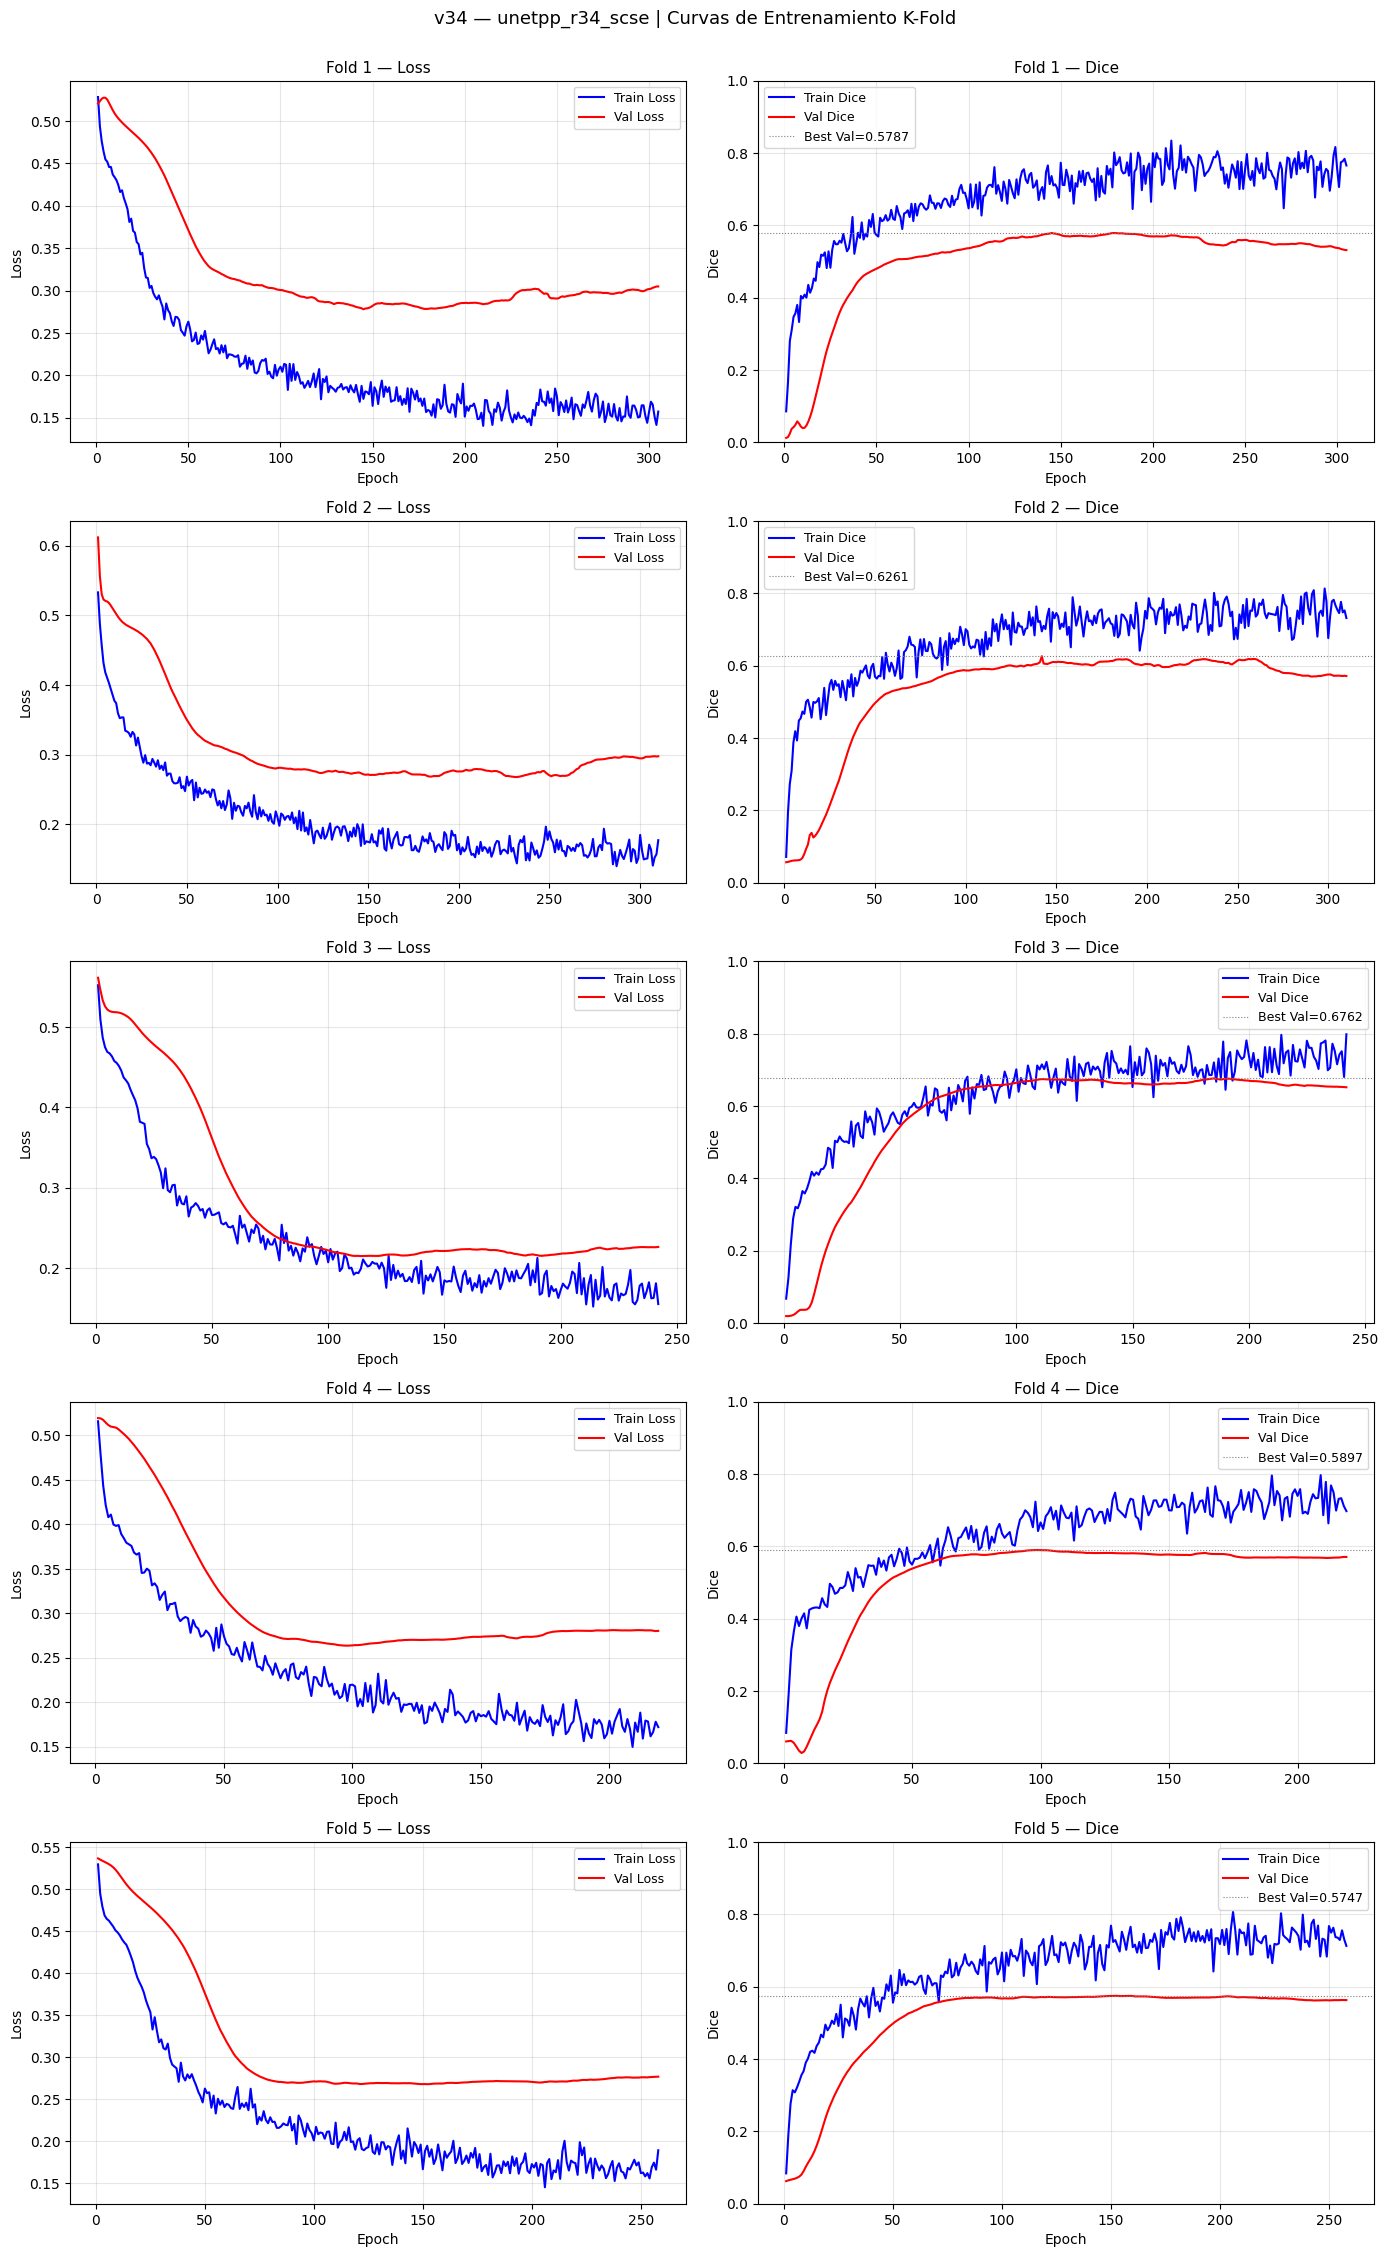

training_curves_v34.png guardado ✅


In [ ]:
# ============================================================
# Curvas de Entrenamiento — v34 K-Fold
# ============================================================

if all_fold_histories:
    n_plots = len(all_fold_histories)
    fig, axes = plt.subplots(n_plots, 2, figsize=(14, 4.5*n_plots))
    if n_plots == 1:
        axes = axes[np.newaxis, :]

    for fi, (fkey, hist) in enumerate(sorted(all_fold_histories.items())):
        epochs = range(1, len(hist.get('train_loss', [])) + 1)

        ax_loss = axes[fi, 0]
        ax_dice = axes[fi, 1]
        fold_num = fkey.replace('fold_', '')

        if hist.get('train_loss'):
            ax_loss.plot(epochs, hist['train_loss'], 'b-',  label='Train Loss',  linewidth=1.5)
        if hist.get('val_loss'):
            ax_loss.plot(range(1, len(hist['val_loss'])+1), hist['val_loss'],
                         'r-', label='Val Loss', linewidth=1.5)
        ax_loss.set_title(f'Fold {int(fold_num)+1} — Loss', fontsize=11)
        ax_loss.set_xlabel('Epoch')
        ax_loss.set_ylabel('Loss')
        ax_loss.legend(fontsize=9)
        ax_loss.grid(True, alpha=0.3)

        if hist.get('train_dice'):
            ax_dice.plot(epochs, hist['train_dice'], 'b-',  label='Train Dice',  linewidth=1.5)
        if hist.get('val_dice'):
            ax_dice.plot(range(1, len(hist['val_dice'])+1), hist['val_dice'],
                         'r-', label='Val Dice', linewidth=1.5)
        if hist.get('ema_val_dice'):
            ax_dice.plot(range(1, len(hist['ema_val_dice'])+1), hist['ema_val_dice'],
                         'g--', label='EMA Val Dice', linewidth=1.2, alpha=0.85)

        best_dice = max(hist.get('val_dice', [0]))
        ax_dice.axhline(best_dice, color='gray', linestyle=':', linewidth=0.8,
                        label=f'Best Val={best_dice:.4f}')
        ax_dice.set_title(f'Fold {int(fold_num)+1} — Dice', fontsize=11)
        ax_dice.set_xlabel('Epoch')
        ax_dice.set_ylabel('Dice')
        ax_dice.legend(fontsize=9)
        ax_dice.grid(True, alpha=0.3)
        ax_dice.set_ylim(0, 1)

    plt.suptitle(f'v34 — {MODEL_NAME} | Curvas de Entrenamiento K-Fold', fontsize=13, y=1.001)
    plt.tight_layout()
    plt.savefig(os.path.join(RESULTS_DIR, 'training_curves_v34.png'), dpi=120, bbox_inches='tight')
    plt.show()
    print('training_curves_v34.png guardado ✅')
else:
    print('No hay historiales. Ejecuta el entrenamiento primero.')


---
## 13. Evaluación por Fold — TTA + Threshold Óptimo
*Carga `best_ema.pth` · Búsqueda de threshold global y per-class · TTA horizontal flip*

In [ ]:
# ============================================================
# Evaluación por fold — v34
# ============================================================
# v34: pipeline de evaluación simplificado y reproducible:
#   - threshold=0.5 fijo (sin búsqueda de threshold óptimo)
#   - Sin TempScaling (sobreajustaría calibración con pocos pacientes)
#   - Sin PCT (per-class threshold) — threshold único para todas las clases
#   - TTA: original + hflip (t=0.5)
#   - fold_mean/fold_std son OBLIGATORIOS (sin fallback a globales)
#   - Se reportan métricas Base (t=0.5) y TTA-hflip (t=0.5)
# ============================================================

def _predict_loader(model, loader, device):
    """Acumula logits y máscaras de un DataLoader."""
    all_preds, all_masks = [], []
    model.eval()
    with torch.inference_mode():
        for images, masks in loader:
            preds = model(images.to(device)).cpu()
            all_preds.append(preds)
            all_masks.append(masks)
    return torch.cat(all_preds, 0), torch.cat(all_masks, 0)

def _predict_loader_tta(model, dataloader, device, modes=None):
    """Predicción con TTA: original + hflip.
    RETORNA: tuple (logits_promediados, máscaras).
    """
    if modes is None:
        modes = TTA_MODES
    all_logits, all_masks = [], []
    model.eval()
    with torch.inference_mode():
        for images, masks in dataloader:
            images = images.to(device)
            batch_logits = []
            for mode in modes:
                if mode == 'original':
                    imgs_aug = images
                elif mode == 'hflip':
                    imgs_aug = torch.flip(images, dims=[3])
                elif mode == 'vflip':
                    imgs_aug = torch.flip(images, dims=[2])
                else:
                    imgs_aug = images
                logits = model(imgs_aug)
                if mode == 'hflip':
                    logits = torch.flip(logits, dims=[3])
                elif mode == 'vflip':
                    logits = torch.flip(logits, dims=[2])
                batch_logits.append(logits.cpu())
            avg_logits = torch.stack(batch_logits, dim=0).mean(dim=0)
            all_logits.append(avg_logits)
            all_masks.append(masks)
    return torch.cat(all_logits, dim=0), torch.cat(all_masks, dim=0)

def evaluate_fold(fold_idx, val_pairs, device, fold_mean, fold_std):
    """Evalúa el checkpoint EMA de un fold con threshold=0.5 fijo.

    PARÁMETROS OBLIGATORIOS: fold_mean y fold_std son los stats del
    train del fold — NO pueden ser None para evitar data leakage.
    """
    # Validar que los stats del fold estén presentes
    if fold_mean is None or fold_std is None:
        raise ValueError(
            f"evaluate_fold fold {fold_idx}: fold_mean/fold_std son None. "
            "Pasa los stats calculados sobre el train del fold. "
            "v34: se prohíbe el fallback a estadísticas globales.")

    print(f'\n[Fold {fold_idx+1}] Evaluando (threshold={EVAL_THRESHOLD} fijo)...')
    ema_path  = os.path.join(CHECKPOINT_DIR, f'{MODEL_NAME}_fold{fold_idx}_best_ema.pth')
    best_path = os.path.join(CHECKPOINT_DIR, f'{MODEL_NAME}_fold{fold_idx}_best.pth')
    load_path = ema_path if os.path.exists(ema_path) else best_path

    if not os.path.exists(load_path):
        print(f'  SKIP: no se encontró checkpoint {load_path}')
        return None

    model = build_model().to(device)
    checkpoint = torch.load(load_path, map_location=device, weights_only=False)
    model.load_state_dict(checkpoint['model_state_dict'])
    model.eval()
    print(f"  Cargado: {os.path.basename(load_path)} "
          f"(epoch={checkpoint['epoch']}, val_dice={checkpoint['val_dice']:.4f})")
    print(f"  Norm stats fold: mean={fold_mean:.4f}, std={fold_std:.4f}")

    pin_mem = torch.cuda.is_available()
    val_transform = get_val_transform(IMAGE_SIZE, fold_mean, fold_std)
    eval_loader = DataLoader(UBPDDataset(val_pairs, val_transform),
                             batch_size=BATCH_SIZE, shuffle=False,
                             num_workers=NUM_WORKERS, pin_memory=pin_mem)

    # ---- Métricas Base (t=0.5) ----
    eval_preds, eval_masks = _predict_loader(model, eval_loader, device)
    metrics_base = compute_all_metrics(eval_preds, eval_masks, threshold=EVAL_THRESHOLD)
    print(f'  Base (t={EVAL_THRESHOLD}): Dice={metrics_base["dice"]["mean"]:.4f}')

    # ---- Métricas TTA-hflip (t=0.5) ----
    eval_preds_tta, _ = _predict_loader_tta(model, eval_loader, device)
    metrics_tta = compute_all_metrics(eval_preds_tta, eval_masks, threshold=EVAL_THRESHOLD)
    print(f'  TTA-hflip (t={EVAL_THRESHOLD}): Dice={metrics_tta["dice"]["mean"]:.4f}')

    del model
    torch.cuda.empty_cache()
    gc.collect()

    # Dice per-image para boxplot
    per_image_dice = []
    probs_eval = torch.sigmoid(eval_preds_tta)
    for img_i in range(probs_eval.shape[0]):
        d = {}
        for c, cname in enumerate(CLASS_NAMES):
            pred_c = (probs_eval[img_i, c] > EVAL_THRESHOLD).float().reshape(-1)
            tgt_c  = eval_masks[img_i, c].reshape(-1)
            inter  = (pred_c * tgt_c).sum()
            d[cname] = float((2. * inter + 1.0) / (pred_c.sum() + tgt_c.sum() + 1.0))
        d['mean'] = float(sum(d[c] for c in CLASS_NAMES) / NUM_CLASSES)
        per_image_dice.append(d)

    return {
        'fold': fold_idx,
        'n_eval_images': len(val_pairs),
        'threshold': EVAL_THRESHOLD,
        'fold_mean': fold_mean,
        'fold_std': fold_std,
        'metrics_base': metrics_base,
        'metrics_tta':  metrics_tta,
        # Aliases directos para celdas de viz (acceso sin _normalize_fold_results)
        'base': metrics_base,
        'tta':  metrics_tta,
        # Tensores en memoria para visualizaciones (excluidos del JSON)
        'logits_base': eval_preds,
        'logits_tta':  eval_preds_tta,
        'masks': eval_masks,
        'per_image_dice': per_image_dice,
    }

# ---- Evaluación de todos los folds ----
fold_results = {}

for fold_idx, (train_idx, val_idx) in enumerate(FOLD_SPLITS):
    val_pairs_fold = [data_pairs[i] for i in val_idx]
    h = all_fold_histories.get(f'fold_{fold_idx}', {})
    # fold_mean/fold_std son obligatorios; se obtienen del historial de entrenamiento
    fold_mean = h.get('fold_mean')
    fold_std  = h.get('fold_std')
    result = evaluate_fold(fold_idx, val_pairs_fold, DEVICE,
                           fold_mean=fold_mean, fold_std=fold_std)
    if result is not None:
        fold_results[f'fold_{fold_idx}'] = result

print('\nEvaluación completada ✅')
print(f'TTA: {TTA_MODES} | threshold fijo: {EVAL_THRESHOLD}')

# Guardar fold_results_v34.json (sin tensores)
def _to_json_safe(obj):
    """Serializa recursivamente excluyendo tensores PyTorch."""
    if isinstance(obj, dict):
        return {k: _to_json_safe(v) for k, v in obj.items()
                if not isinstance(v, torch.Tensor)}
    elif isinstance(obj, (np.floating, np.float32, np.float64)):
        return float(obj)
    elif isinstance(obj, (np.integer, np.int32, np.int64)):
        return int(obj)
    elif isinstance(obj, np.ndarray):
        return obj.tolist()
    elif isinstance(obj, list):
        return [_to_json_safe(x) for x in obj]
    return obj

fold_results_path = os.path.join(RESULTS_DIR, 'fold_results_v34.json')
with open(fold_results_path, 'w', encoding='utf-8') as f:
    json.dump(_to_json_safe(fold_results), f, indent=2, ensure_ascii=False)
print(f'fold_results_v34.json guardado: {len(fold_results)} folds → {fold_results_path}')

# Resumen final de evaluación
print(f"\n{'='*60}")
print(f'RESUMEN EVALUACIÓN — threshold={EVAL_THRESHOLD} fijo')
print(f"{'='*60}")
base_dices = [r['metrics_base']['dice']['mean'] for r in fold_results.values()]
tta_dices  = [r['metrics_tta']['dice']['mean']  for r in fold_results.values()]
print(f"{'Fold':>5} {'Base t=0.5':>12} {'TTA-hflip t=0.5':>16}")
print('-' * 38)
for fi, fk in enumerate(sorted(fold_results.keys())):
    b = fold_results[fk]['metrics_base']['dice']['mean']
    t = fold_results[fk]['metrics_tta']['dice']['mean']
    print(f"  {fi+1:>3} {b:>12.4f} {t:>16.4f}")
print('-' * 38)
print(f"  Dice Base  = {np.mean(base_dices):.4f} \u00b1 {np.std(base_dices):.4f}")
print(f"  Dice TTA   = {np.mean(tta_dices):.4f} \u00b1 {np.std(tta_dices):.4f}")



[Fold 1] Evaluando (threshold=0.5 fijo)...
  Aviso: esta versión de smp no soporta decoder_dropout; se omite.
  UNet++ (ResNet-34 + scSE, decoder_dropout=0.30)
  Params: 26,275,495 (trainable: 26,275,495)
  Cargado: unetpp_r34_scse_fold0_best_ema.pth (epoch=145, val_dice=0.5787)
  Norm stats fold: mean=0.1791, std=0.1557
  Base (t=0.5): Dice=0.5852
  TTA-hflip (t=0.5): Dice=0.5832

[Fold 2] Evaluando (threshold=0.5 fijo)...
  Aviso: esta versión de smp no soporta decoder_dropout; se omite.
  UNet++ (ResNet-34 + scSE, decoder_dropout=0.30)
  Params: 26,275,495 (trainable: 26,275,495)
  Cargado: unetpp_r34_scse_fold1_best_ema.pth (epoch=142, val_dice=0.6261)
  Norm stats fold: mean=0.1692, std=0.1529
  Base (t=0.5): Dice=0.6556
  TTA-hflip (t=0.5): Dice=0.6605

[Fold 3] Evaluando (threshold=0.5 fijo)...
  Aviso: esta versión de smp no soporta decoder_dropout; se omite.
  UNet++ (ResNet-34 + scSE, decoder_dropout=0.30)
  Params: 26,275,495 (trainable: 26,275,495)
  Cargado: unetpp_r34_sc

---
## 14. Visualización de Predicciones
*Carga `best_ema.pth` de cada fold · Muestra imagen original, GT y predicción en color por clase*


Visualizando fold 1...
  Aviso: esta versión de smp no soporta decoder_dropout; se omite.
  UNet++ (ResNet-34 + scSE, decoder_dropout=0.30)
  Params: 26,275,495 (trainable: 26,275,495)


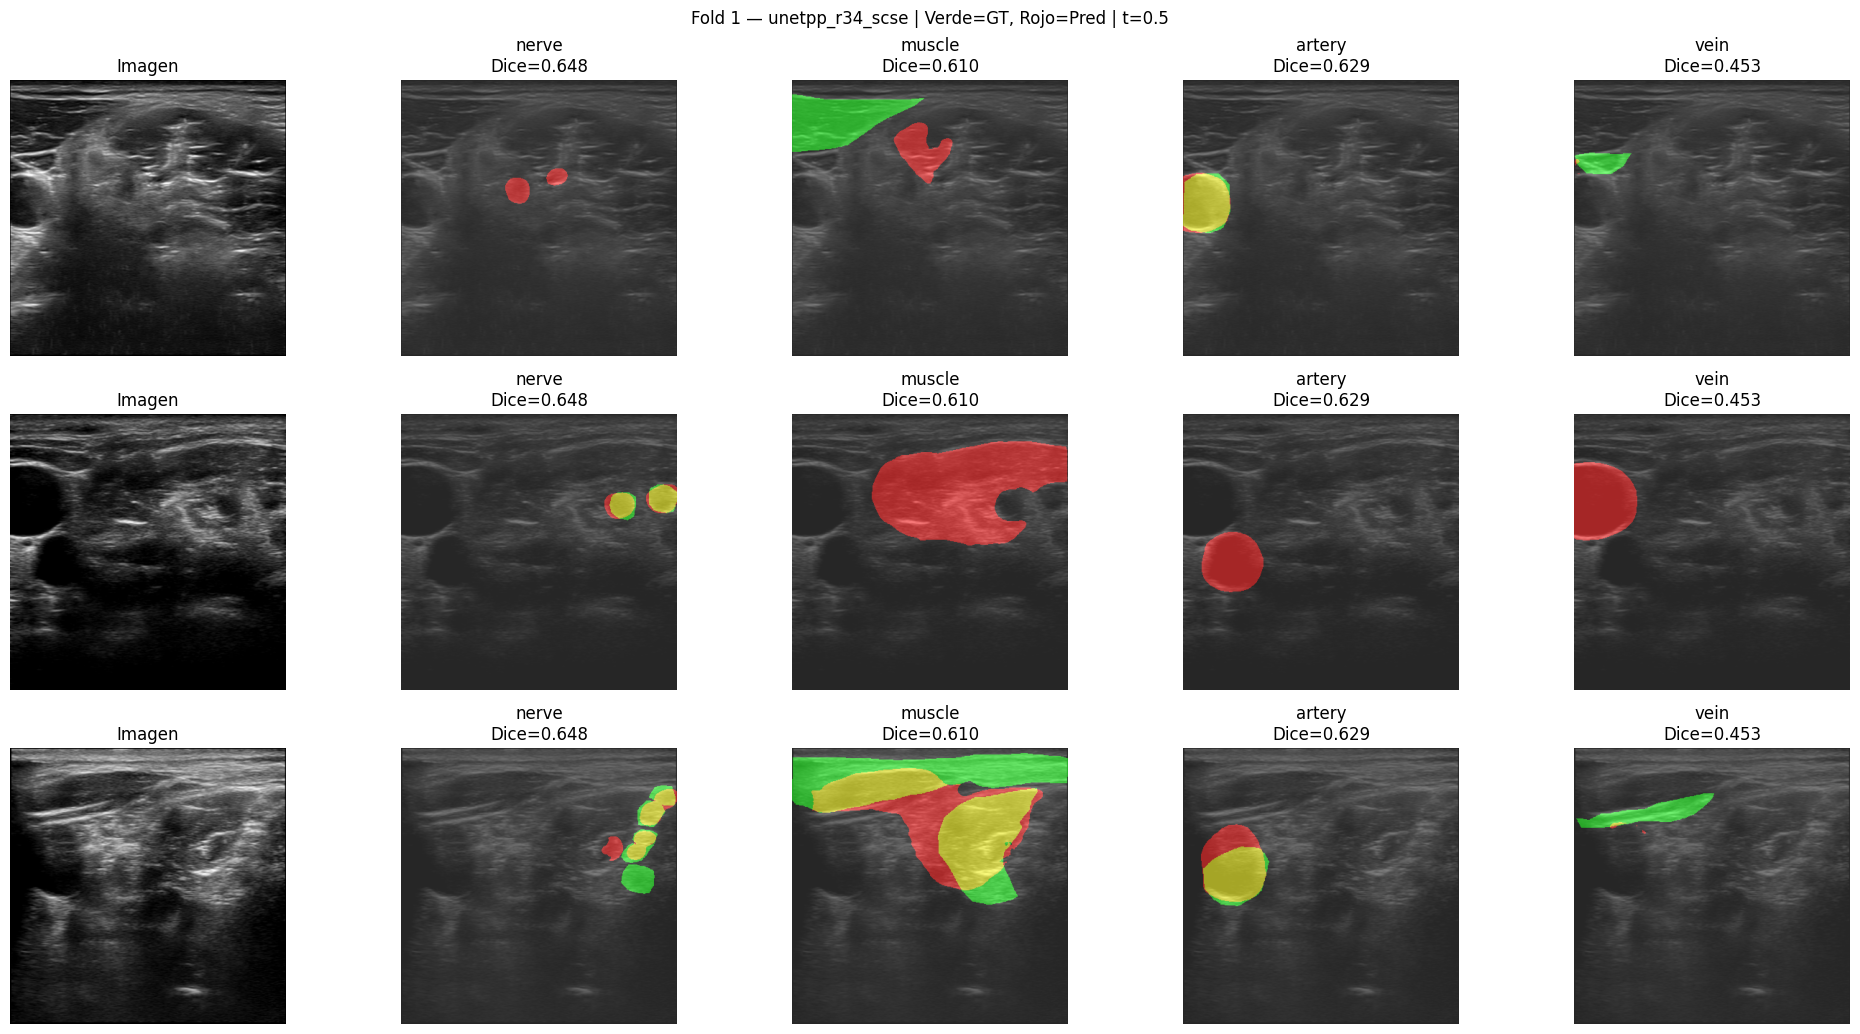


Visualizando fold 2...
  Aviso: esta versión de smp no soporta decoder_dropout; se omite.
  UNet++ (ResNet-34 + scSE, decoder_dropout=0.30)
  Params: 26,275,495 (trainable: 26,275,495)


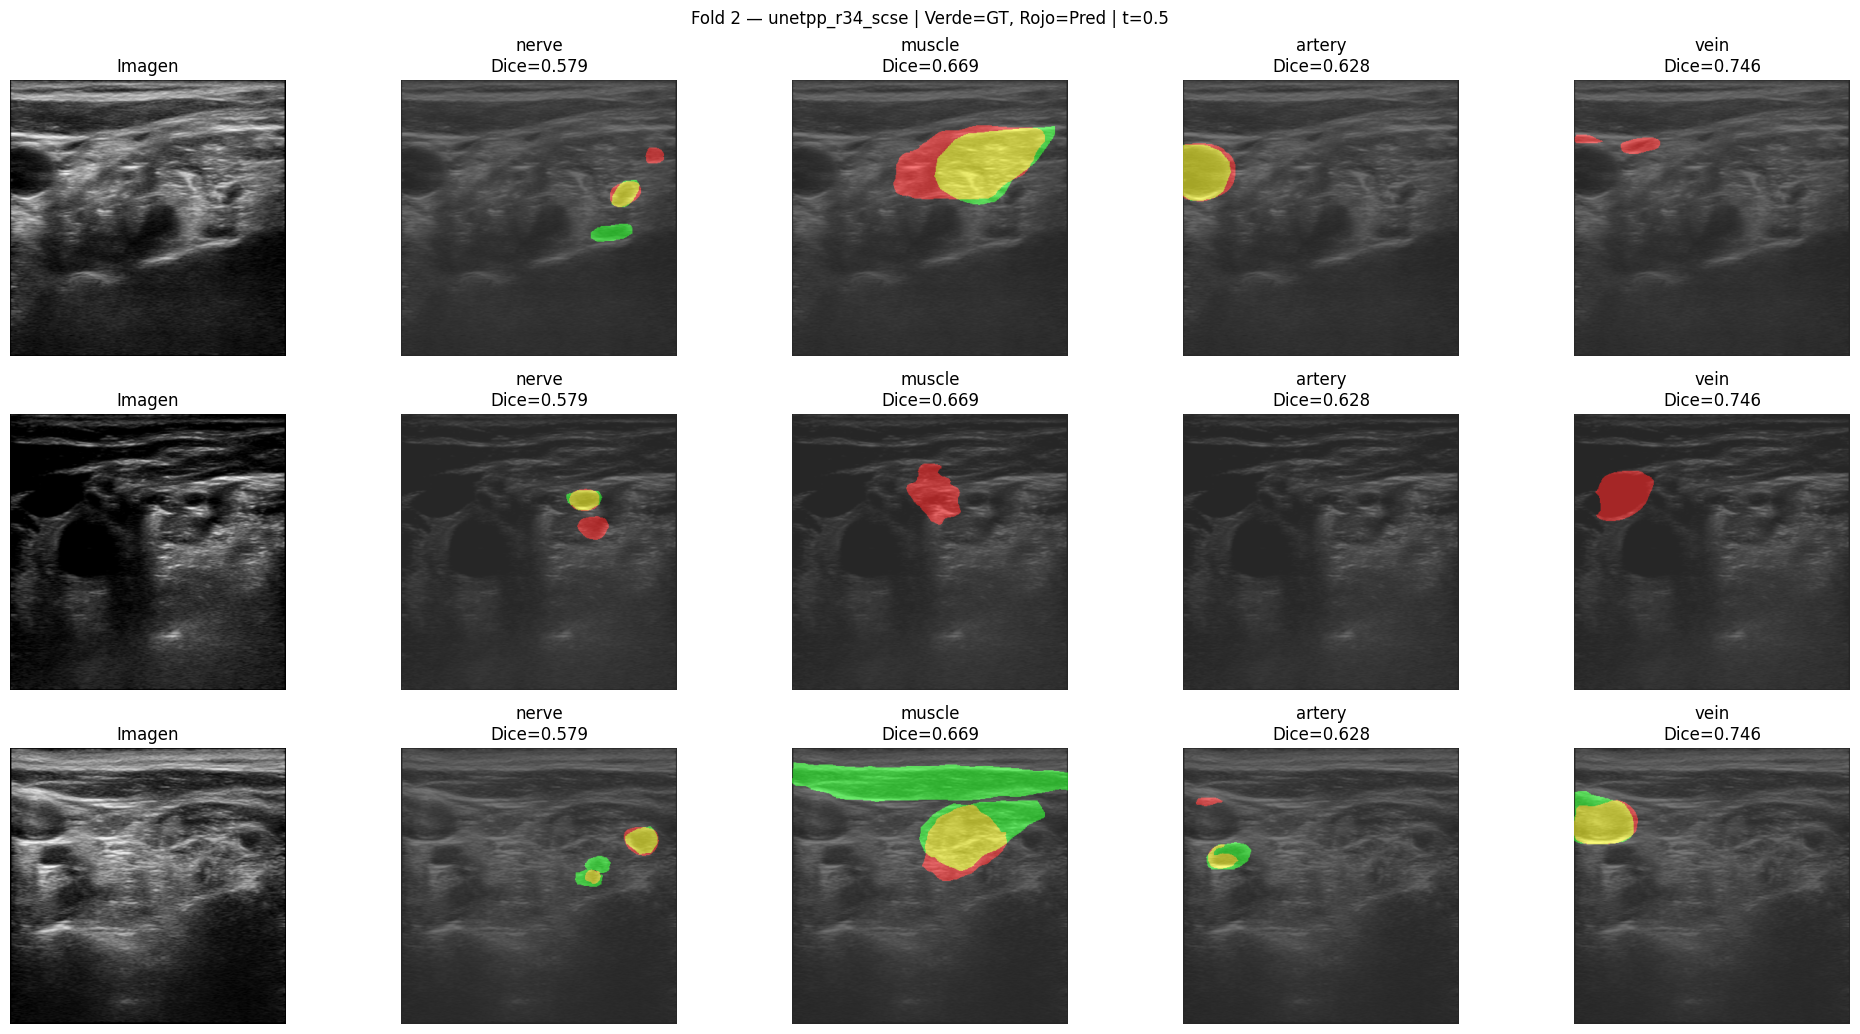


Visualizando fold 3...
  Aviso: esta versión de smp no soporta decoder_dropout; se omite.
  UNet++ (ResNet-34 + scSE, decoder_dropout=0.30)
  Params: 26,275,495 (trainable: 26,275,495)


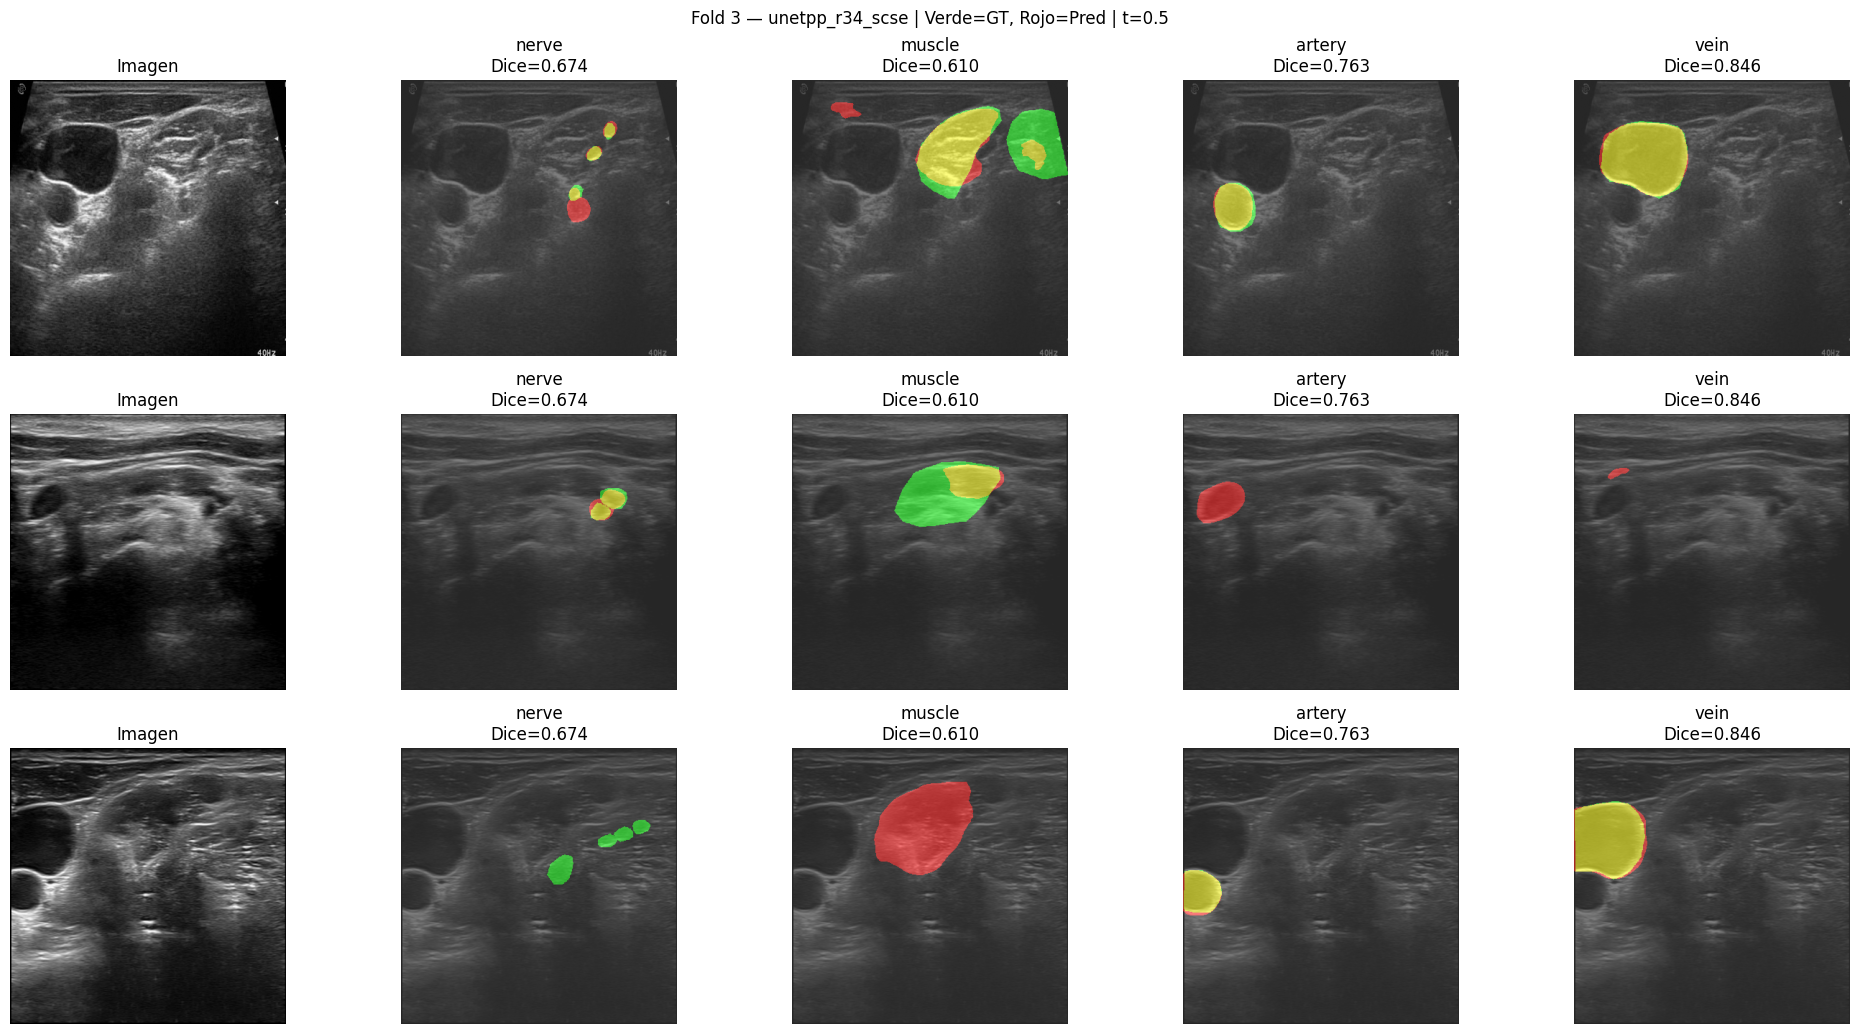


Visualizando fold 4...
  Aviso: esta versión de smp no soporta decoder_dropout; se omite.
  UNet++ (ResNet-34 + scSE, decoder_dropout=0.30)
  Params: 26,275,495 (trainable: 26,275,495)


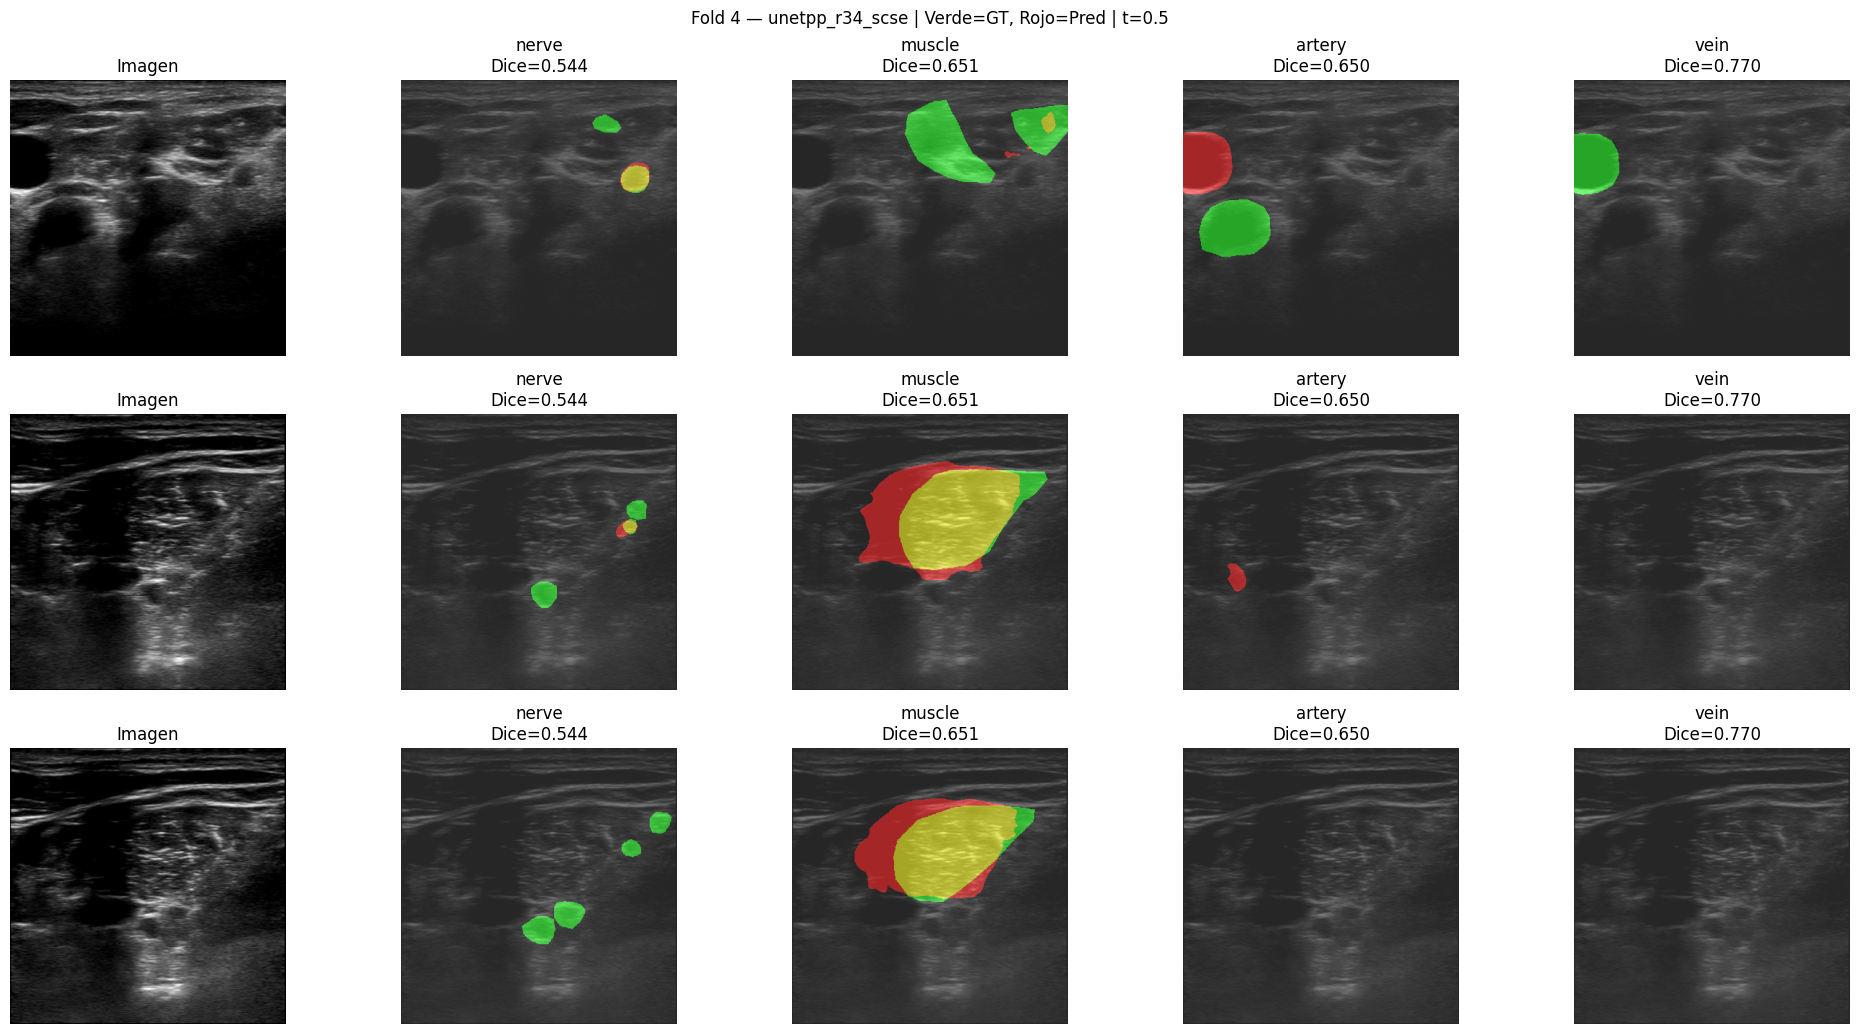


Visualizando fold 5...
  Aviso: esta versión de smp no soporta decoder_dropout; se omite.
  UNet++ (ResNet-34 + scSE, decoder_dropout=0.30)
  Params: 26,275,495 (trainable: 26,275,495)


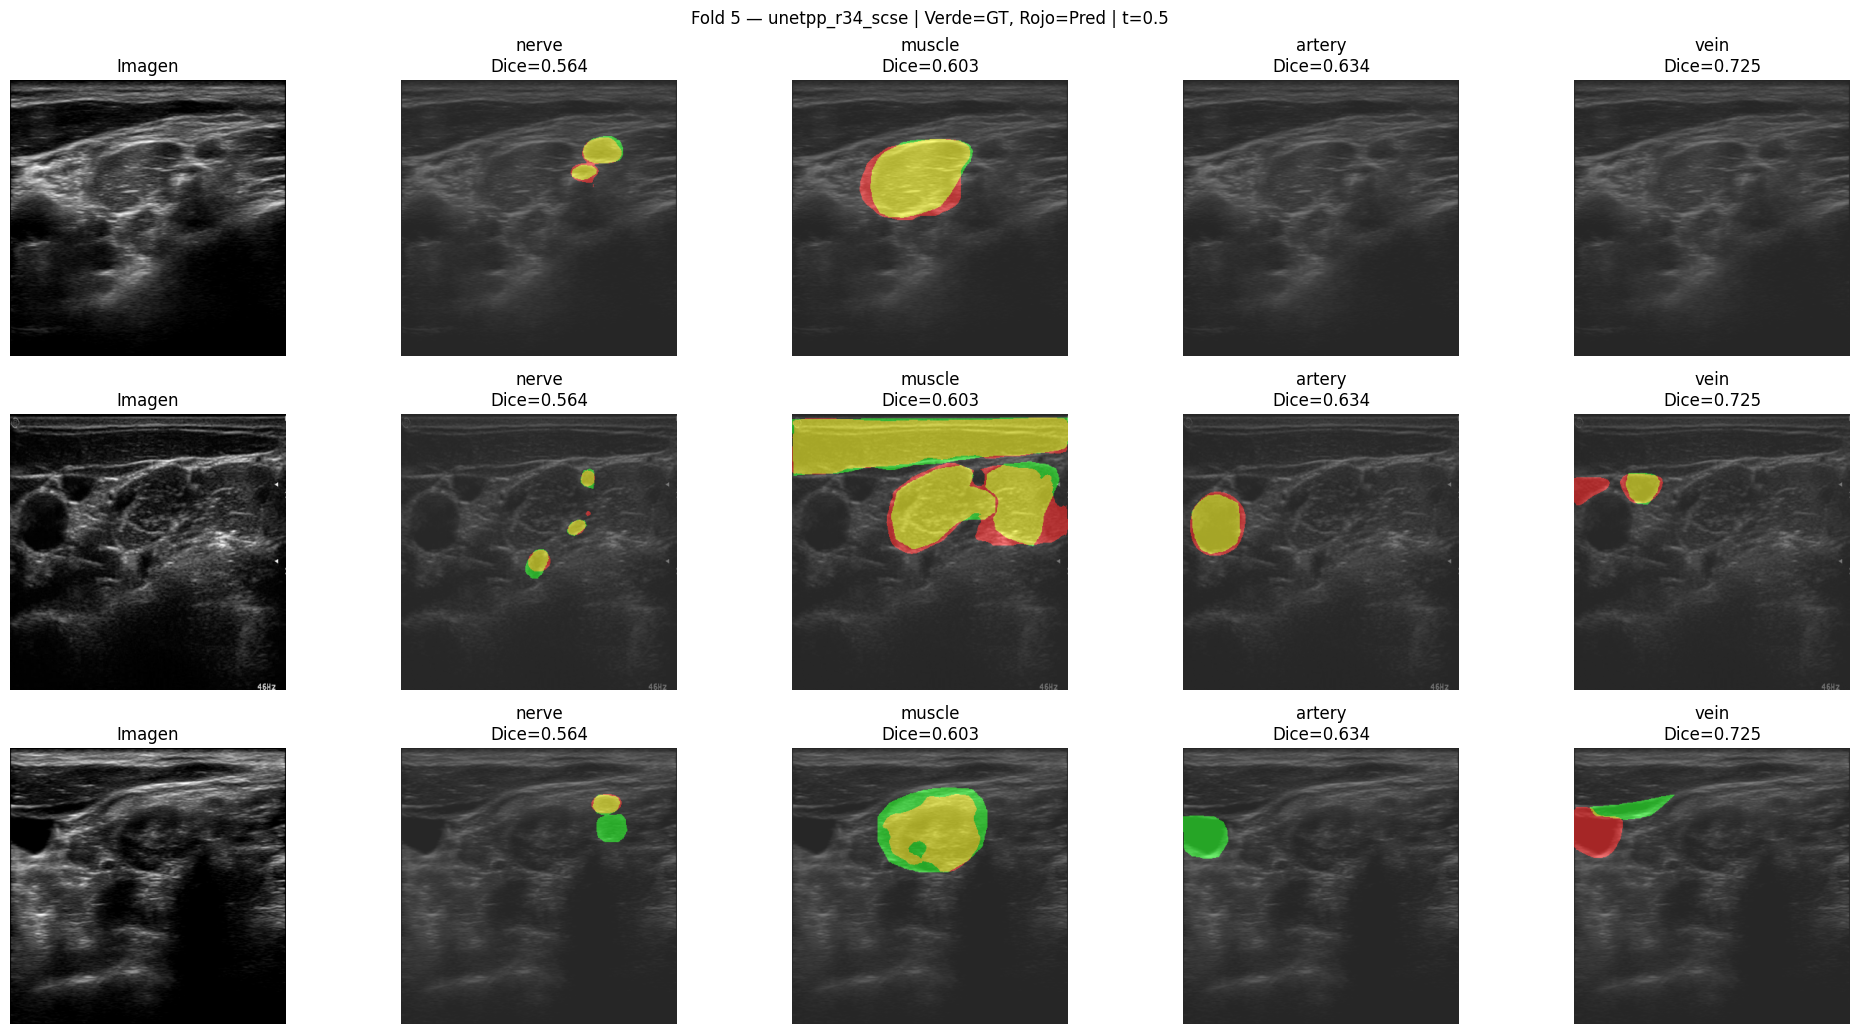

In [ ]:
# ============================================================
# Visualización de predicciones por fold — v34
# ============================================================

def visualize_predictions(fold_idx, val_pairs, n_samples=3, device=DEVICE,
                           fold_mean=None, fold_std=None):
    """Visualiza predicciones de un fold.
    fold_mean/fold_std son OBLIGATORIOS — sin fallback a globales (v34).
    """
    if fold_mean is None or fold_std is None:
        raise ValueError(
            f"visualize_predictions fold {fold_idx}: fold_mean/fold_std son None. "
            "Obtén los stats del historial: all_fold_histories[f'fold_{fold_idx}']")

    ema_path  = os.path.join(CHECKPOINT_DIR, f'{MODEL_NAME}_fold{fold_idx}_best_ema.pth')
    best_path = os.path.join(CHECKPOINT_DIR, f'{MODEL_NAME}_fold{fold_idx}_best.pth')
    load_path = ema_path if os.path.exists(ema_path) else best_path
    if not os.path.exists(load_path):
        print(f'No se encontró checkpoint para fold {fold_idx}')
        return

    model = build_model().to(device)
    ck = torch.load(load_path, map_location=device, weights_only=False)
    model.load_state_dict(ck['model_state_dict'])
    model.eval()

    pin_mem = torch.cuda.is_available()
    ds = UBPDDataset(val_pairs, get_val_transform(IMAGE_SIZE, fold_mean, fold_std))
    loader = DataLoader(ds, batch_size=n_samples, shuffle=True,
                        num_workers=NUM_WORKERS, pin_memory=pin_mem)
    images, masks = next(iter(loader))

    with torch.inference_mode():
        logits = model(images.to(device)).cpu()
    probs = torch.sigmoid(logits)
    preds = (probs > EVAL_THRESHOLD).float()  # threshold=0.5 fijo

    fig, axes = plt.subplots(n_samples, NUM_CLASSES + 1, figsize=(4 * (NUM_CLASSES + 1), 3.5 * n_samples))
    if n_samples == 1:
        axes = [axes]

    for i in range(n_samples):
        img = images[i].permute(1, 2, 0).numpy()
        img = img * fold_std + fold_mean
        img = np.clip(img, 0, 1)
        if img.shape[2] == 1:
            img = img[:, :, 0]
        axes[i][0].imshow(img, cmap='gray' if len(img.shape) == 2 else None)
        axes[i][0].set_title('Imagen')
        axes[i][0].axis('off')

        for c, name in enumerate(CLASS_NAMES):
            ax = axes[i][c + 1]
            gt = masks[i, c].numpy()
            pred = preds[i, c].numpy()
            overlay = np.zeros((*gt.shape, 3))
            overlay[gt == 1] = [0, 1, 0]
            overlay[pred == 1] += [1, 0, 0]
            ax.imshow(img, cmap='gray' if len(img.shape) == 2 else None, alpha=0.7)
            ax.imshow(overlay, alpha=0.5)
            dice_c = fold_results.get(f'fold_{fold_idx}', {}).get(
                'metrics_base', {}).get('dice', {}).get(name, 0)
            ax.set_title(f'{name}\nDice={dice_c:.3f}')
            ax.axis('off')

    plt.suptitle(f'Fold {fold_idx+1} — {MODEL_NAME} | Verde=GT, Rojo=Pred | t={EVAL_THRESHOLD}', fontsize=12)
    plt.tight_layout()
    save_path = os.path.join(RESULTS_DIR, f'predictions_fold{fold_idx}_v34.png')
    plt.savefig(save_path, dpi=120, bbox_inches='tight')
    plt.show()

    del model
    torch.cuda.empty_cache()

for fold_idx, (train_idx, val_idx) in enumerate(FOLD_SPLITS):
    val_pairs_fold = [data_pairs[i] for i in val_idx]
    h = all_fold_histories.get(f'fold_{fold_idx}', {})
    fold_mean = h.get('fold_mean')
    fold_std  = h.get('fold_std')
    print(f'\nVisualizando fold {fold_idx+1}...')
    visualize_predictions(fold_idx, val_pairs_fold, n_samples=3, device=DEVICE,
                          fold_mean=fold_mean, fold_std=fold_std)


---
## 15. Resumen de Métricas K-Fold — Mean ± Std
*Tabla Dice/IoU/Precision/Recall por clase · Comparación val_dice entrenamiento vs evaluación*

In [ ]:
# ============================================================
# Tabla de Resultados K-Fold — UBPD v34
# ============================================================
# v34: solo dos estrategias con threshold=0.5 fijo:
#   Base (t=0.5): predicción directa sin TTA
#   TTA-hflip (t=0.5): promedio original + hflip
#
# Se eliminaron TTA+PCT y TempScale+PCT para mayor reproducibilidad.
# El Dice final se reporta como media ± std sobre los N folds.
# ============================================================

if fold_results:
    print(f"\n{'='*80}")
    print(f"RESULTADOS K-FOLD — {MODEL_NAME} — {N_FOLDS} folds | threshold={EVAL_THRESHOLD} fijo")
    print(f"{'='*80}\n")

    print(f"{'Fold':>5} {'N_eval':>7} | {'Base t=0.5':>12} {'TTA-hflip t=0.5':>16}")
    print('-' * 46)

    base_dices, tta_dices = [], []
    for fold_key, r in sorted(fold_results.items()):
        fi     = r['fold']
        n_eval = r.get('n_eval_images', 0)
        b      = r['metrics_base']['dice']['mean']
        t      = r['metrics_tta']['dice']['mean']
        print(f"  {fi+1:>3} {n_eval:>7} | {b:>12.4f} {t:>16.4f}")
        base_dices.append(b)
        tta_dices.append(t)

    print('-' * 46)
    print(f"  Mean         | {np.mean(base_dices):>12.4f} {np.mean(tta_dices):>16.4f}")
    print(f"  Std          | {np.std(base_dices):>12.4f} {np.std(tta_dices):>16.4f}")
    print(f"\n  >>> Dice (TTA-hflip, t=0.5) = {np.mean(tta_dices):.4f} \u00b1 {np.std(tta_dices):.4f} <<<")

    # Desglose por clase — TTA-hflip t=0.5
    print('\n--- DESGLOSE POR CLASE (TTA-hflip, t=0.5) ---')
    class_header = f"{'Clase':>10} " + " ".join(f"F{i+1:>4}" for i in range(len(fold_results))) + f" {'Mean':>7} {'Std':>6}"
    print(class_header)
    print('-' * (13 + 7 * len(fold_results)))
    for name in CLASS_NAMES + ['mean']:
        vals = []
        for r in sorted(fold_results.values(), key=lambda x: x['fold']):
            if name == 'mean':
                vals.append(r['metrics_tta']['dice']['mean'])
            else:
                vals.append(r['metrics_tta']['dice'].get(name, float('nan')))
        row = f"  {name:>8} " + " ".join(f"{v:>6.4f}" for v in vals)
        row += f"  {np.nanmean(vals):>6.4f}  {np.nanstd(vals):>5.4f}"
        print(row)

    # Hausdorff HD95 por clase
    print('\n--- HAUSDORFF HD95 POR CLASE (TTA-hflip, px) ---')
    class_header_hd = f"{'Clase':>10} " + " ".join(f"F{i+1:>6}" for i in range(len(fold_results))) + f" {'Mean':>8}"
    print(class_header_hd)
    for name in CLASS_NAMES + ['mean']:
        vals = []
        for r in sorted(fold_results.values(), key=lambda x: x['fold']):
            hd_dict = r.get('metrics_tta', {}).get('hd95', {})
            vals.append(hd_dict.get(name, float('nan')))
        row = f"  {name:>8} " + " ".join(f"{v:>7.2f}" for v in vals)
        row += f"  {np.nanmean(vals):>7.2f}"
        print(row)

else:
    print('No hay resultados por fold. Ejecuta la celda de evaluación primero.')



RESULTADOS K-FOLD — unetpp_r34_scse — 5 folds | threshold=0.5 fijo

 Fold  N_eval |   Base t=0.5  TTA-hflip t=0.5
----------------------------------------------
    1     192 |       0.5852           0.5832
    2     192 |       0.6556           0.6605
    3     190 |       0.7234           0.7234
    4     191 |       0.6540           0.6582
    5     190 |       0.6315           0.6312
----------------------------------------------
  Mean         |       0.6499           0.6513
  Std          |       0.0447           0.0455

  >>> Dice (TTA-hflip, t=0.5) = 0.6513 ± 0.0455 <<<

--- DESGLOSE POR CLASE (TTA-hflip, t=0.5) ---
     Clase F   1 F   2 F   3 F   4 F   5    Mean    Std
------------------------------------------------
     nerve 0.6483 0.5877 0.6699 0.5399 0.5678  0.6027  0.0490
    muscle 0.6164 0.6662 0.6134 0.6566 0.6040  0.6313  0.0251
    artery 0.6127 0.6280 0.7608 0.6633 0.6345  0.6598  0.0531
      vein 0.4555 0.7603 0.8493 0.7731 0.7183  0.7113  0.1347
      mean 0.5

---
## 16. Visualización de Resultados — Gráficas por Clase y por Fold
*Barplot Dice Base vs TTA · Comparación entre folds*

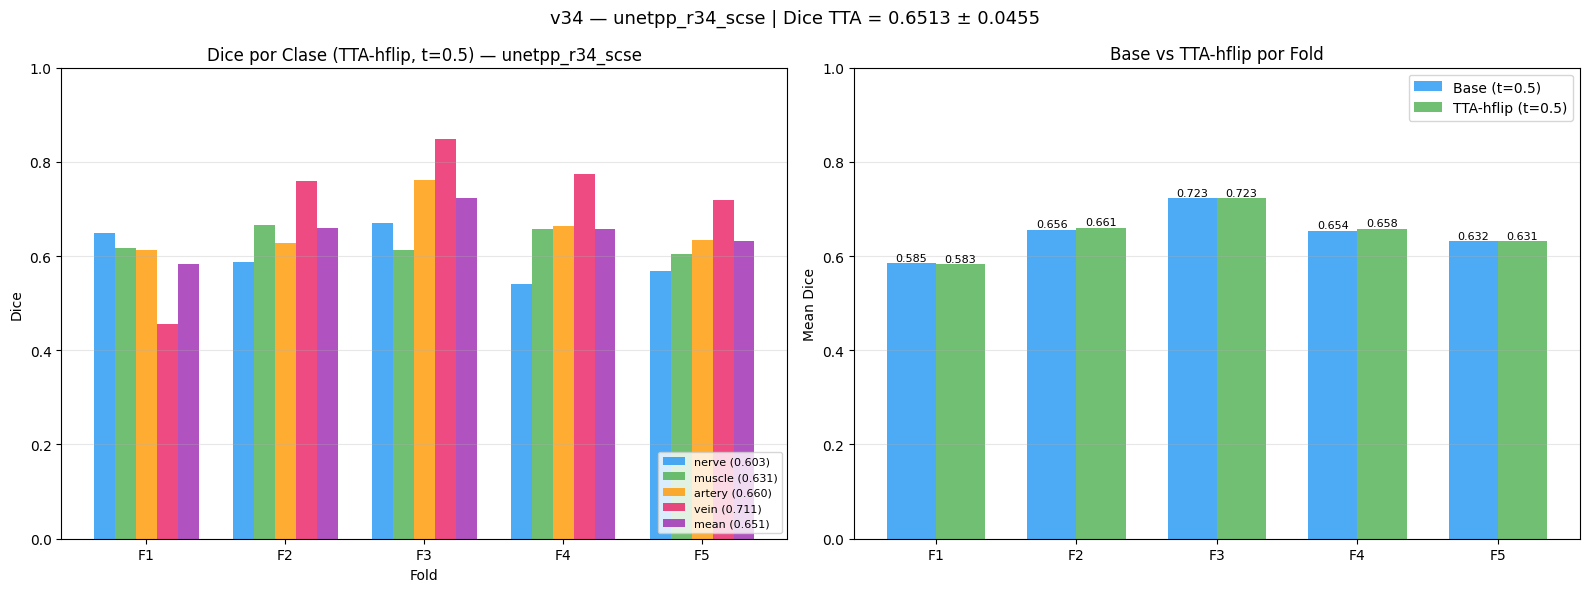

In [ ]:

# ============================================================
# Gráficos de métricas por clase — v34
# v34: solo Base (t=0.5) y TTA-hflip (t=0.5)
# ============================================================

if fold_results:
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))

    # Dice por clase (TTA-hflip t=0.5)
    dice_data = {name: [] for name in CLASS_NAMES + ['mean']}
    for r in sorted(fold_results.values(), key=lambda x: x['fold']):
        for name in CLASS_NAMES:
            dice_data[name].append(r['metrics_tta']['dice'].get(name, float('nan')))
        dice_data['mean'].append(r['metrics_tta']['dice']['mean'])

    n_folds_shown = len(dice_data['mean'])
    x = np.arange(n_folds_shown)
    width = 0.15
    colors = ['#2196F3', '#4CAF50', '#FF9800', '#E91E63', '#9C27B0']
    labels = CLASS_NAMES + ['mean']
    ax = axes[0]
    for i, (name, color) in enumerate(zip(labels, colors)):
        vals = dice_data[name]
        offset = (i - len(labels) / 2) * width + width / 2
        ax.bar(x + offset, vals, width, label=f'{name} ({np.nanmean(vals):.3f})',
               color=color, alpha=0.8)
    ax.set_title(f'Dice por Clase (TTA-hflip, t={EVAL_THRESHOLD}) — {MODEL_NAME}')
    ax.set_xlabel('Fold')
    ax.set_ylabel('Dice')
    ax.set_xticks(x)
    ax.set_xticklabels([f'F{i+1}' for i in range(n_folds_shown)])
    ax.legend(loc='lower right', fontsize=8)
    ax.grid(True, axis='y', alpha=0.3)
    ax.set_ylim(0, 1)

    # Comparación Base vs TTA-hflip por fold
    strategy_keys   = ['metrics_base', 'metrics_tta']
    strategy_labels = [f'Base (t={EVAL_THRESHOLD})', f'TTA-hflip (t={EVAL_THRESHOLD})']
    strategy_colors = ['#2196F3', '#4CAF50']
    fold_keys = sorted(fold_results.keys())
    x2 = np.arange(len(fold_keys))
    width2 = 0.35

    ax2 = axes[1]
    for si, (sk, slabel, sc) in enumerate(zip(strategy_keys, strategy_labels, strategy_colors)):
        vals = [fold_results[fk][sk]['dice']['mean'] for fk in fold_keys]
        bars = ax2.bar(x2 + si*width2, vals, width2, label=slabel, color=sc, alpha=0.8)
        for bar, v in zip(bars, vals):
            ax2.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.005,
                     f'{v:.3f}', ha='center', fontsize=8)

    ax2.set_xticks(x2 + width2/2)
    ax2.set_xticklabels([f'F{i+1}' for i in range(len(fold_keys))], fontsize=10)
    ax2.set_ylabel('Mean Dice')
    ax2.set_title('Base vs TTA-hflip por Fold')
    ax2.legend(fontsize=10)
    ax2.grid(True, axis='y', alpha=0.3)
    ax2.set_ylim(0, 1)

    tta_vals = [fold_results[fk]['metrics_tta']['dice']['mean'] for fk in fold_keys]
    plt.suptitle(f'v34 — {MODEL_NAME} | Dice TTA = {np.mean(tta_vals):.4f} \u00b1 {np.std(tta_vals):.4f}', fontsize=13)
    plt.tight_layout()
    plt.savefig(os.path.join(RESULTS_DIR, 'metrics_by_class_v34.png'), dpi=150, bbox_inches='tight')
    plt.show()
else:
    print('No hay fold_results. Ejecuta la evaluación primero.')


---
## 17. Resumen Final
*Mean Dice ± Std por clase · Dice base y TTA · Rutas de checkpoints y resultados*

In [ ]:
# ============================================================
# Resumen Final — UBPD v34 K-Fold Cross Validation
# ============================================================
# v34: pipeline claro, reproducible y defendible:
#   - GroupKFold explícito (separación garantizada por paciente)
#   - mean/std calculados solo sobre train del fold (sin leakage)
#   - threshold=0.5 fijo (reproducible, sin sobreajuste de calibración)
#   - EMA mantenido (estabiliza entrenamiento)
#   - Sin TempScaling, sin PCT
#   - Dice final = media ± std sobre N folds (no "best model")
# ============================================================

print('=' * 70)
print(f'  RESUMEN FINAL — {MODEL_NAME} — K-Fold Cross Validation v34')
print('=' * 70)

print(f'''
CONFIGURACIÓN DEL EXPERIMENTO:
  Arquitectura : {MODEL_CONFIG["arch"]}({MODEL_CONFIG["encoder"]}) — decoder_dropout={MODEL_CONFIG["decoder_dropout_rate"]}
  K-Folds      : {N_FOLDS} (GroupKFold, separación garantizada por paciente)
  Epochs máx   : {NUM_EPOCHS} (early stopping, patience={EARLY_STOP_PATIENCE})
  Image size   : {IMAGE_SIZE}×{IMAGE_SIZE}
  Batch size   : {BATCH_SIZE}
  LR decoder   : {LEARNING_RATE:.1e} | LR encoder: {ENCODER_LR:.1e}
  EMA          : {USE_EMA} (decay={EMA_DECAY}) — estabiliza entrenamiento
  TTA          : {TTA_MODES}
  Threshold    : {EVAL_THRESHOLD} FIJO (reproducible, sin sobreajuste de calibración)
  SWA          : últimas {SWA_START_EPOCH} epochs | LR factor={SWA_LR_FACTOR}
  Label smooth : {LABEL_SMOOTH} (solo FocalBCE)
  Loss         : FT={LOSS_FT_W} + BCE={LOSS_BCE_W} + Boundary={LOSS_BOUNDARY_W}
  Norm stats   : compute_fold_stats(train_fold) por fold — sin leakage a val
''')

if fold_results:
    base_dices = [r['metrics_base']['dice']['mean'] for r in fold_results.values()]
    tta_dices  = [r['metrics_tta']['dice']['mean']  for r in fold_results.values()]

    print(f'RESULTADOS (threshold={EVAL_THRESHOLD} fijo — reproducible):')
    print(f'  Base (t=0.5)    : {np.mean(base_dices):.4f} \u00b1 {np.std(base_dices):.4f}')
    print(f'  TTA-hflip (t=0.5): {np.mean(tta_dices):.4f} \u00b1 {np.std(tta_dices):.4f}')
    print(f'\n  >>> Dice Final = {np.mean(tta_dices):.4f} \u00b1 {np.std(tta_dices):.4f} (TTA-hflip, t=0.5) <<<')

    # Desglose por clase
    print(f'\nDETALLE POR CLASE (TTA-hflip, t=0.5):')
    print(f"  {'Clase':>8} {'Dice Mean':>10} {'Dice Std':>10}")
    print('  ' + '-' * 30)
    for name in CLASS_NAMES:
        vals = [r['metrics_tta']['dice'].get(name, float('nan')) for r in fold_results.values()]
        print(f"  {name:>8} {np.nanmean(vals):>10.4f} {np.nanstd(vals):>10.4f}")

    # Overfitting gap
    if all_fold_histories:
        all_train_last = [h['train_dice'][-1] for h in all_fold_histories.values()
                          if h.get('train_dice')]
        if all_train_last:
            mean_train = np.mean(all_train_last)
            gap = mean_train - np.mean(base_dices)
            print(f'\n  Overfitting gap: {mean_train:.4f} (train) - {np.mean(base_dices):.4f} (val) = {gap:.4f}')
            if gap < 0.10:
                print('  ✅ Gap < 0.10: buena generalización')
            elif gap < 0.20:
                print('  ⚠️  Gap 0.10-0.20: sobreajuste moderado')
            else:
                print('  ❌ Gap > 0.20: sobreajuste significativo')

print('\n' + '=' * 70)
print(f'  Checkpoints: {CHECKPOINT_DIR}')
print(f'  Resultados : {RESULTS_DIR}')
print('=' * 70)


  RESUMEN FINAL — unetpp_r34_scse — K-Fold Cross Validation v34

CONFIGURACIÓN DEL EXPERIMENTO:
  Arquitectura : UnetPlusPlus(resnet34) — decoder_dropout=0.3
  K-Folds      : 5 (GroupKFold, separación garantizada por paciente)
  Epochs máx   : 400 (early stopping, patience=50)
  Image size   : 384×384
  Batch size   : 16
  LR decoder   : 3.0e-04 | LR encoder: 3.0e-05
  EMA          : True (decay=0.999) — estabiliza entrenamiento
  TTA          : ['original', 'hflip']
  Threshold    : 0.5 FIJO (reproducible, sin sobreajuste de calibración)
  SWA          : últimas 40 epochs | LR factor=0.3
  Label smooth : 0.05 (solo FocalBCE)
  Loss         : FT=0.5 + BCE=0.3 + Boundary=0.2
  Norm stats   : compute_fold_stats(train_fold) por fold — sin leakage a val

RESULTADOS (threshold=0.5 fijo — reproducible):
  Base (t=0.5)    : 0.6499 ± 0.0447
  TTA-hflip (t=0.5): 0.6513 ± 0.0455

  >>> Dice Final = 0.6513 ± 0.0455 (TTA-hflip, t=0.5) <<<

DETALLE POR CLASE (TTA-hflip, t=0.5):
     Clase  Dice Mea

## 18. Guardado Completo de Resultados

Genera todos los archivos de resultados en `results_v34/`:

| Archivo | Contenido |
|---|---|
| `fold_results_v34.json` | Métricas completas por fold (Base t=0.5, TTA-hflip t=0.5) |
| `kfold_histories_v34.json` | Historiales de entrenamiento (guardado en la Celda 11) |
| `analysis_data_v34.json` | Arrays por clase para gráficos y análisis estadístico |
| `diagnostic_v34.txt` | Informe de métricas agregadas en texto plano |


In [ ]:
# ============================================================
# Guardado Completo de Resultados — UBPD v34
# ============================================================
# Genera los siguientes archivos en results_v34/:
#  fold_results_v34.json   — métricas por fold (base t=0.5, TTA-hflip t=0.5)
#  kfold_histories_v34.json — historiales de entrenamiento
#  analysis_data_v34.json  — arrays por clase para análisis estadístico
#  diagnostic_v34.txt      — informe de texto plano con métricas agregadas
# ============================================================

import csv

print("Guardando resultados v34...")

# 1. fold_results_v34.json (guardado en la celda de evaluación)
fold_results_path = os.path.join(RESULTS_DIR, 'fold_results_v34.json')
if os.path.exists(fold_results_path):
    with open(fold_results_path, 'r') as f:
        fold_results_saved = json.load(f)
    print(f'  fold_results_v34.json: {len(fold_results_saved)} folds ✅')
else:
    print('  fold_results_v34.json: no encontrado (ejecutar celda de evaluación primero)')
    fold_results_saved = {}

_fr = fold_results if fold_results else fold_results_saved

# 2. analysis_data_v34.json — arrays por clase y estrategia
analysis_data = {'class_names': CLASS_NAMES, 'n_folds': N_FOLDS, 'model': MODEL_NAME,
                 'threshold': EVAL_THRESHOLD, 'version': 'v34'}
method_map = {
    'base': 'metrics_base',
    'tta':  'metrics_tta',
}
if _fr:
    for analysis_key, fold_key in method_map.items():
        method_data = {}
        for c in CLASS_NAMES + ['mean']:
            vals = []
            for fk, fd in _fr.items():
                m = fd.get(fold_key, {})
                if not isinstance(m, dict):
                    continue
                if 'dice' in m:
                    v = m['dice'].get(c)
                elif c in m:
                    v = m.get(c)
                else:
                    v = None
                if v is not None:
                    vals.append(float(v))
            if vals:
                method_data[c] = {'values': vals,
                                  'mean': float(np.mean(vals)),
                                  'std': float(np.std(vals))}
        if method_data:
            analysis_data[analysis_key] = method_data

with open(os.path.join(RESULTS_DIR, 'analysis_data_v34.json'), 'w') as f:
    json.dump(analysis_data, f, indent=2)
print('  analysis_data_v34.json ✅')

# 3. diagnostic_v34.txt
diag_lines = [
    f"DIAGNÓSTICO — {MODEL_NAME} — UBPD v34 K-Fold",
    f"{'='*60}",
    f"Fecha: {__import__('datetime').datetime.now().strftime('%Y-%m-%d %H:%M')}",
    f"",
    f"CONFIGURACIÓN:",
    f"  Encoder: resnet34 + scSE | Decoder dropout: 0.30",
    f"  Loss: FT({LOSS_FT_W}) + BCE({LOSS_BCE_W}) + Boundary({LOSS_BOUNDARY_W})",
    f"  SWA: últimas {SWA_START_EPOCH} epochs | Label smooth: {LABEL_SMOOTH}",
    f"  EMA: {USE_EMA} (decay={EMA_DECAY})",
    f"  TTA: {TTA_MODES}",
    f"  Threshold: {EVAL_THRESHOLD} FIJO (sin TempScaling, sin PCT)",
    f"  GroupKFold: separación garantizada por paciente",
    f"  Norm stats: compute_fold_stats(train_fold) — sin leakage a val",
    f"",
]

if _fr:
    for strategy_key, strategy_label in [
        ('metrics_base', f'Base (t={EVAL_THRESHOLD})'),
        ('metrics_tta',  f'TTA-hflip (t={EVAL_THRESHOLD})'),
    ]:
        diag_lines.append(f"RESULTADOS — {strategy_label}:")
        for c in CLASS_NAMES + ['mean']:
            vals = []
            for fk, fd in _fr.items():
                m = fd.get(strategy_key, {})
                if isinstance(m, dict):
                    if 'dice' in m:
                        v = m['dice'].get(c)
                    elif c in m:
                        v = m.get(c)
                    else:
                        v = None
                    if v is not None:
                        vals.append(float(v))
            if vals:
                diag_lines.append(f"  {c:<10}: {np.mean(vals):.4f} \u00b1 {np.std(vals):.4f}")
        diag_lines.append("")

    # Resumen final
    tta_vals = []
    for fk, fd in _fr.items():
        m = fd.get('metrics_tta', {})
        if 'dice' in m:
            tta_vals.append(float(m['dice'].get('mean', 0)))
    if tta_vals:
        diag_lines.append(f">>> RESULTADO FINAL: Dice = {np.mean(tta_vals):.4f} \u00b1 {np.std(tta_vals):.4f} (TTA-hflip, t={EVAL_THRESHOLD}) <<<")

with open(os.path.join(RESULTS_DIR, 'diagnostic_v34.txt'), 'w', encoding='utf-8') as f:
    f.write('\n'.join(diag_lines))
print('  diagnostic_v34.txt ✅')
print('\nTodos los resultados guardados en results_v34/ ✅')


Guardando resultados v34...
  fold_results_v34.json: 5 folds ✅
  analysis_data_v34.json ✅
  diagnostic_v34.txt ✅

Todos los resultados guardados en results_v34/ ✅


## 19. Visualizaciones Completas K-Fold — v34

Visualizaciones para el análisis de resultados K-Fold:
- Predicciones comparativas (Input / GT / Predicción por fold)
- Overlay 4 clases sobre imagen US
- Heatmaps Dice/IoU/HD95 por clase × fold
- Boxplot Dice per-image
- Precision/Recall heatmap
- Radar chart multi-métrica
- Comparación estrategias (Base t=0.5 vs TTA-hflip t=0.5)
- Eficiencia de entrenamiento


In [ ]:
# ============================================================
# Setup Visualizaciones v34 — carga datos y helpers
# ============================================================
import matplotlib.patches as mpatches
import seaborn as sns
from matplotlib import gridspec

sns.set_theme(style='whitegrid', palette='muted', font_scale=1.0)

COLOR_MAP_VIS = np.array([[255,0,0],[0,220,0],[0,0,255],[255,220,0]])
CLASS_COLORS_FLOAT = COLOR_MAP_VIS / 255.0

def mask_to_rgb(mask_tensor, threshold=EVAL_THRESHOLD):
    """Convierte tensor [C,H,W] en imagen RGB coloreada."""
    mask = mask_tensor.numpy() if hasattr(mask_tensor, 'numpy') else mask_tensor
    h, w = mask.shape[1], mask.shape[2]
    rgb = np.zeros((h, w, 3), dtype=np.uint8)
    for c in range(min(NUM_CLASSES, mask.shape[0])):
        binary = (mask[c] > threshold).astype(np.uint8)
        for ch in range(3):
            rgb[:,:,ch] = np.maximum(rgb[:,:,ch], binary * COLOR_MAP_VIS[c][ch])
    return rgb

def denorm_img(img_tensor, fold_mean, fold_std):
    """Desnormaliza imagen grayscale a [0,1].
    fold_mean y fold_std son obligatorios (v34: sin fallback a globales).
    """
    img = img_tensor.numpy() if hasattr(img_tensor, 'numpy') else img_tensor
    return np.clip(img * fold_std + fold_mean, 0, 1)

# Cargar fold_results_v34 si ya existe
fold_results_v34 = {}
fold_results_path = os.path.join(RESULTS_DIR, 'fold_results_v34.json')
if os.path.exists(fold_results_path):
    with open(fold_results_path) as f:
        fold_results_v34 = json.load(f)
    print(f'fold_results_v34.json cargado: {len(fold_results_v34)} folds')
else:
    print('fold_results_v34.json no encontrado — ejecutar evaluación primero')

# Cargar historiales de entrenamiento
histories_path = os.path.join(RESULTS_DIR, 'kfold_histories_v34.json')
all_fold_histories_viz = {}
if os.path.exists(histories_path):
    with open(histories_path) as f:
        all_fold_histories_viz = json.load(f)
    print(f'kfold_histories_v34.json cargado: {len(all_fold_histories_viz)} folds')

color_patches = [mpatches.Patch(color=COLOR_MAP_VIS[i]/255., label=CLASS_NAMES[i])
                 for i in range(NUM_CLASSES)]

# ── Normalización de claves ────────────────────────────────
# fold_results_v34.json guarda métricas bajo 'metrics_base' y 'metrics_tta'.
# Las celdas de viz esperan 'base' y 'tta'. Esta función adapta el formato.
# v34: se eliminó 'tempscale_pct' y 'tta_pct' (threshold fijo en todo).
def _normalize_fold_results(raw):
    normalized = {}
    for fk, fd in raw.items():
        norm = {}
        base_m = fd.get('metrics_base', {})
        tta_m  = fd.get('metrics_tta', base_m)

        norm['base'] = {
            'dice':           base_m.get('dice', {}),
            'iou':            base_m.get('iou', {}),
            'precision':      base_m.get('precision', {}),
            'recall':         base_m.get('recall', {}),
            'hd95':           base_m.get('hd95', {}),
            'pixel_accuracy': base_m.get('pixel_accuracy', 0),
            'per_image_dice': fd.get('per_image_dice', []),
        }
        norm['tta'] = {
            'dice':           tta_m.get('dice', {}),
            'iou':            tta_m.get('iou',  base_m.get('iou', {})),
            'precision':      tta_m.get('precision', base_m.get('precision', {})),
            'recall':         tta_m.get('recall',    base_m.get('recall', {})),
            'hd95':           tta_m.get('hd95',      base_m.get('hd95', {})),
            'pixel_accuracy': tta_m.get('pixel_accuracy', base_m.get('pixel_accuracy', 0)),
            'per_image_dice': fd.get('per_image_dice', []),
        }
        # metadata del fold
        for key in ('fold', 'n_eval_images', 'threshold', 'fold_mean', 'fold_std'):
            if key in fd:
                norm[key] = fd[key]
        norm['per_image_dice'] = fd.get('per_image_dice', [])
        normalized[fk] = norm
    return normalized

if fold_results_v34:
    fold_results_v34 = _normalize_fold_results(fold_results_v34)
    print(f'fold_results_v34 normalizado ({len(fold_results_v34)} folds) ✅')

print('Setup visualizaciones v34 ✅')
print(f'threshold fijo: {EVAL_THRESHOLD} | estrategias: base, tta-hflip')


fold_results_v34.json cargado: 5 folds
kfold_histories_v34.json cargado: 5 folds
fold_results_v34 normalizado (5 folds) ✅
Setup visualizaciones v34 ✅
threshold fijo: 0.5 | estrategias: base, tta-hflip


### 19.1 Comparación de Predicciones por Fold

  Aviso: esta versión de smp no soporta decoder_dropout; se omite.
  UNet++ (ResNet-34 + scSE, decoder_dropout=0.30)
  Params: 26,275,495 (trainable: 26,275,495)
  Aviso: esta versión de smp no soporta decoder_dropout; se omite.
  UNet++ (ResNet-34 + scSE, decoder_dropout=0.30)
  Params: 26,275,495 (trainable: 26,275,495)
  Aviso: esta versión de smp no soporta decoder_dropout; se omite.
  UNet++ (ResNet-34 + scSE, decoder_dropout=0.30)
  Params: 26,275,495 (trainable: 26,275,495)
  Aviso: esta versión de smp no soporta decoder_dropout; se omite.
  UNet++ (ResNet-34 + scSE, decoder_dropout=0.30)
  Params: 26,275,495 (trainable: 26,275,495)
  Aviso: esta versión de smp no soporta decoder_dropout; se omite.
  UNet++ (ResNet-34 + scSE, decoder_dropout=0.30)
  Params: 26,275,495 (trainable: 26,275,495)


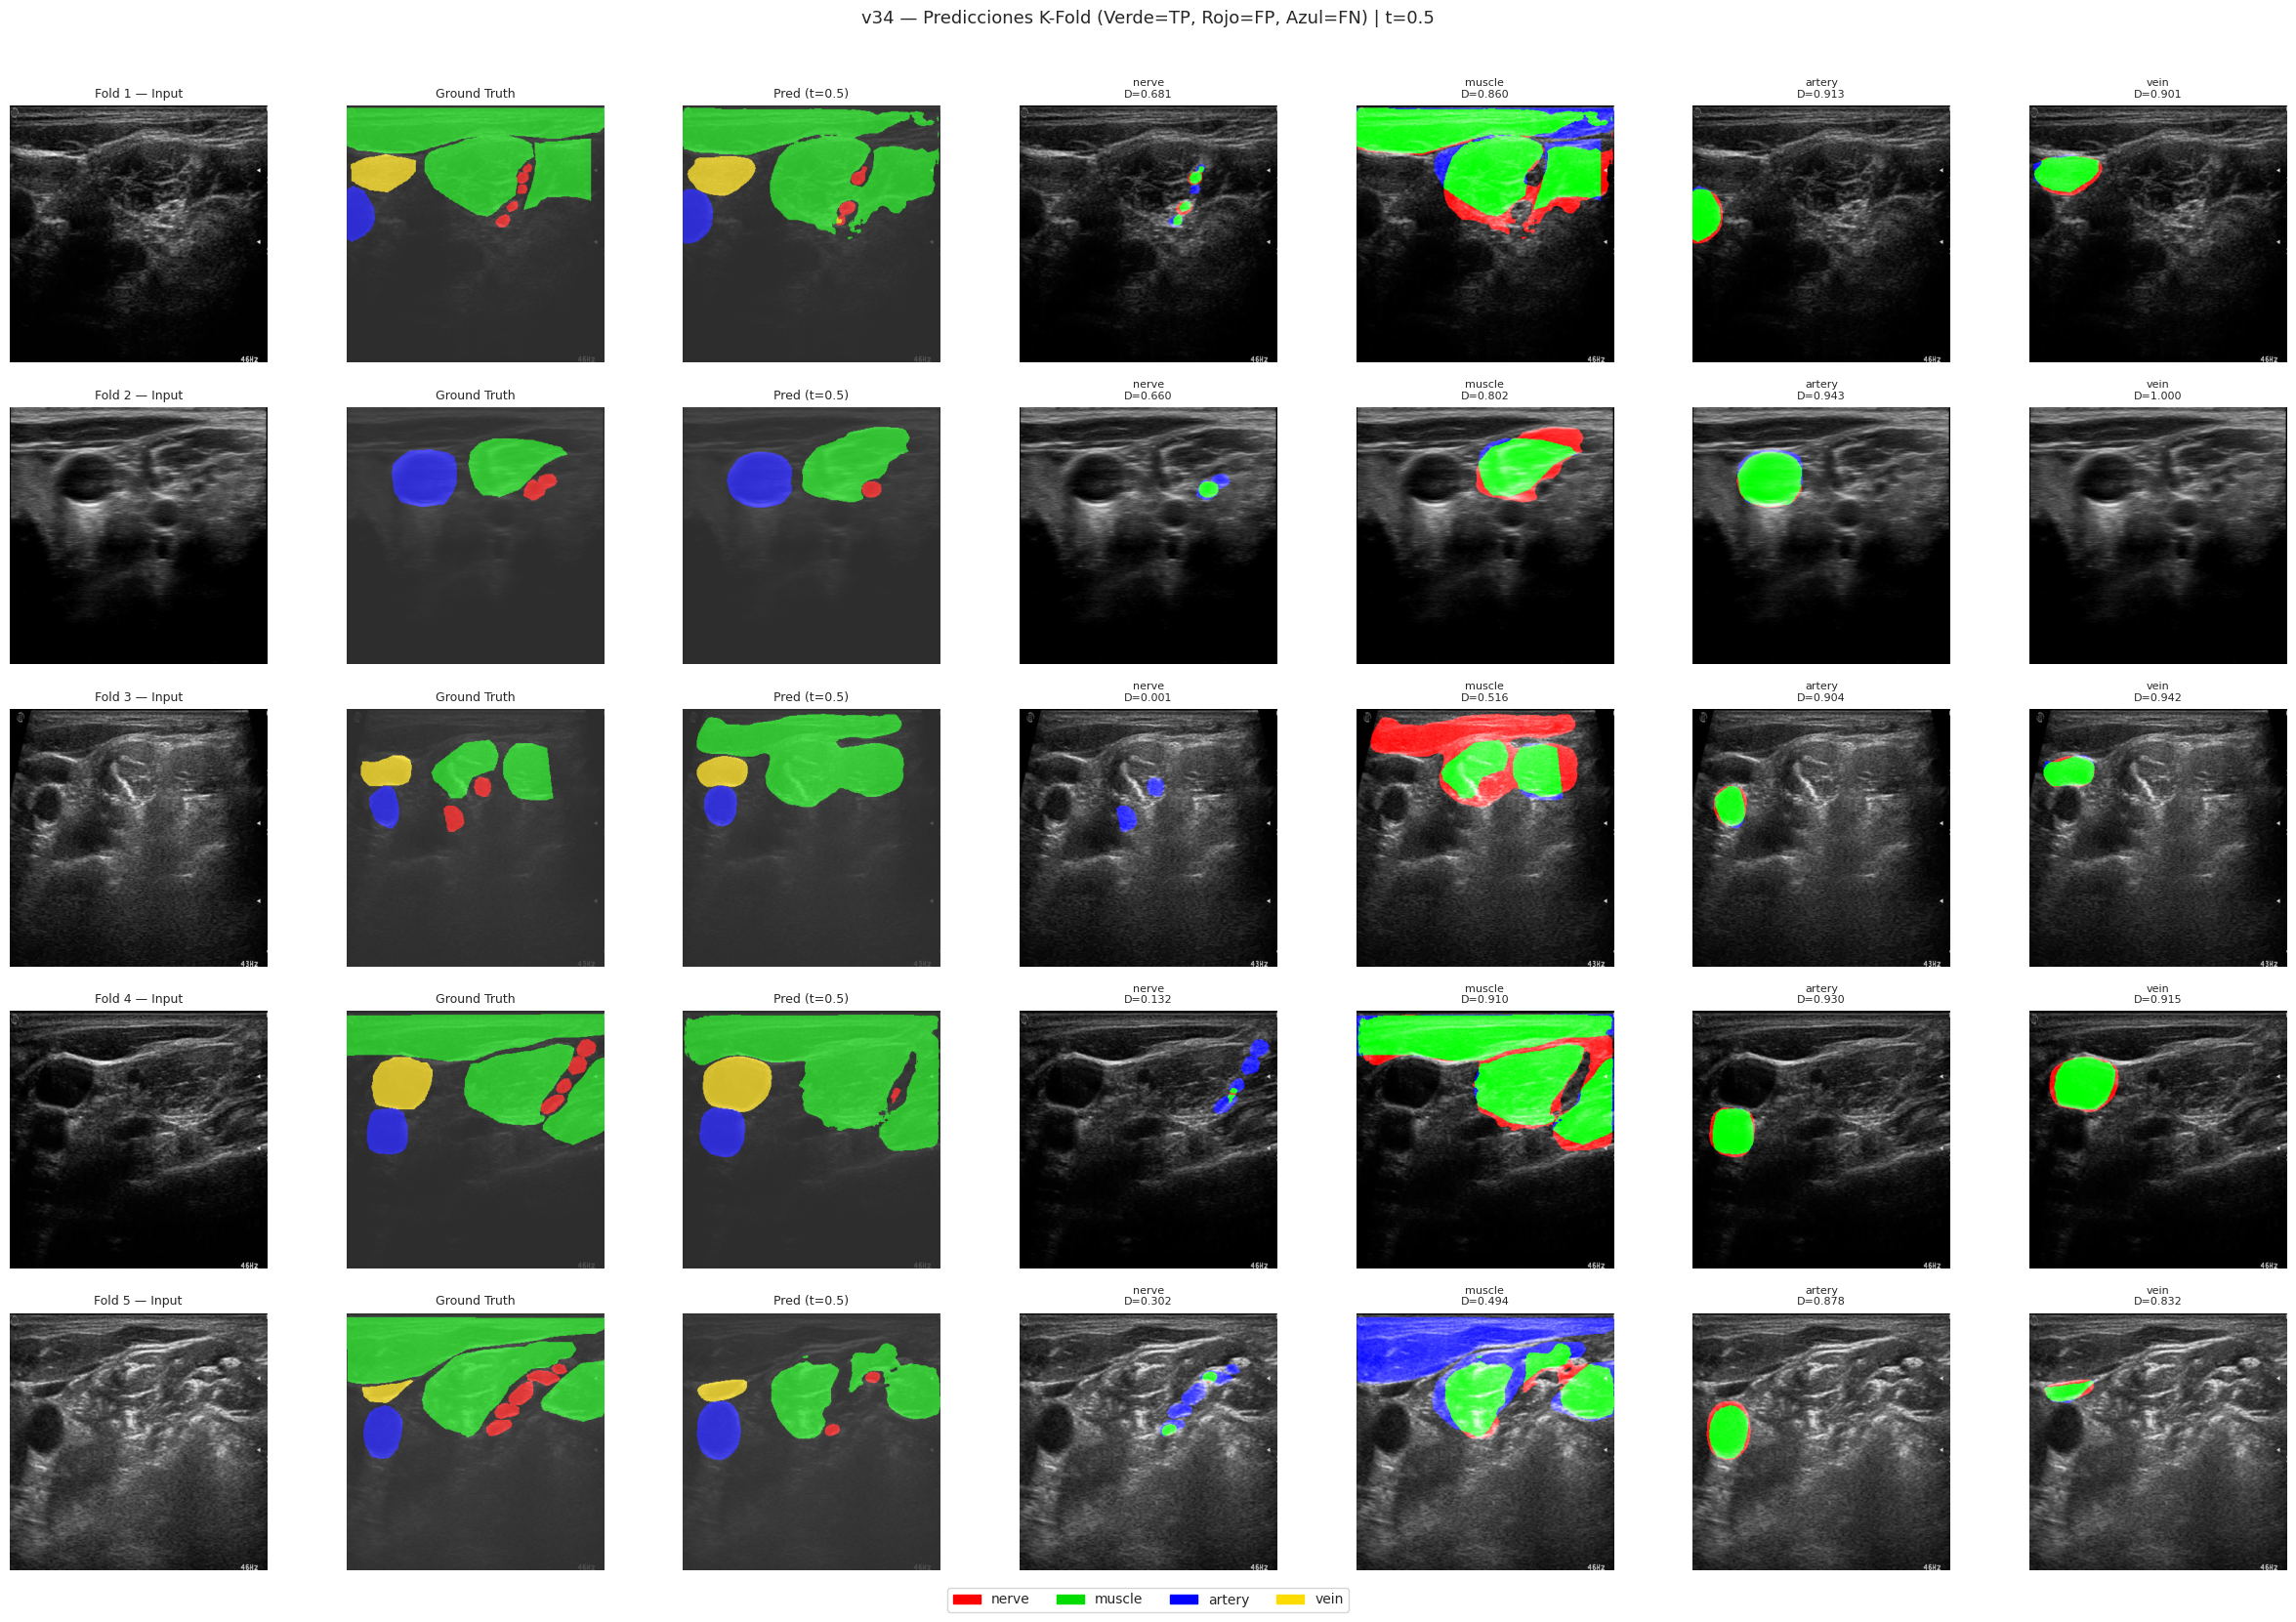

predictions_comparison_v34.png guardado ✅


In [ ]:

# ============================================================
# Comparación Input / Ground Truth / Predicción — por fold
# v34: 1 muestra por fold (5 total) — fold_mean/fold_std del historial
# ============================================================

N_VIS = 1   # 1 imagen por fold → 5 filas en total

fig_rows = N_FOLDS * N_VIS
fig, axes = plt.subplots(fig_rows, 3 + NUM_CLASSES,
                         figsize=(3.5*(3+NUM_CLASSES), 3.2*fig_rows))
if fig_rows == 1:
    axes = axes[np.newaxis, :]

row_idx = 0
for fold_idx, (train_idx, val_idx) in enumerate(FOLD_SPLITS):
    val_pairs_fold = [data_pairs[i] for i in val_idx]

    h_key = f'fold_{fold_idx}'
    fold_mean_v = all_fold_histories_viz.get(h_key, {}).get('fold_mean')
    fold_std_v  = all_fold_histories_viz.get(h_key, {}).get('fold_std')
    if fold_mean_v is None or fold_std_v is None:
        print(f'  Fold {fold_idx+1}: fold_mean/fold_std no disponibles en historial, skip')
        continue

    val_ds_viz = UBPDDataset(val_pairs_fold, get_val_transform(IMAGE_SIZE, fold_mean_v, fold_std_v))
    val_loader_viz = DataLoader(val_ds_viz, batch_size=N_VIS, shuffle=False, num_workers=0)

    ema_path  = os.path.join(CHECKPOINT_DIR, f'{MODEL_NAME}_fold{fold_idx}_best_ema.pth')
    best_path = os.path.join(CHECKPOINT_DIR, f'{MODEL_NAME}_fold{fold_idx}_best.pth')
    load_path = ema_path if os.path.exists(ema_path) else best_path
    if not os.path.exists(load_path):
        print(f'  Fold {fold_idx}: checkpoint no encontrado, skip')
        continue

    model_viz = build_model().to(DEVICE)
    ckpt = torch.load(load_path, map_location=DEVICE, weights_only=False)
    model_viz.load_state_dict(ckpt['model_state_dict'])
    model_viz.eval()

    images_b, masks_b = next(iter(val_loader_viz))
    with torch.inference_mode():
        logits_b = model_viz(images_b.to(DEVICE)).cpu()
    probs_b = torch.sigmoid(logits_b)

    for s in range(min(N_VIS, images_b.shape[0])):
        img_np = denorm_img(images_b[s, 0], fold_mean_v, fold_std_v)

        axes[row_idx, 0].imshow(img_np, cmap='gray')
        axes[row_idx, 0].set_title(f'Fold {fold_idx+1} — Input', fontsize=9)
        axes[row_idx, 0].axis('off')

        gt_rgb = mask_to_rgb(masks_b[s])
        axes[row_idx, 1].imshow(img_np, cmap='gray', alpha=0.5)
        axes[row_idx, 1].imshow(gt_rgb, alpha=0.65)
        axes[row_idx, 1].set_title('Ground Truth', fontsize=9)
        axes[row_idx, 1].axis('off')

        pred_rgb = mask_to_rgb(probs_b[s])
        axes[row_idx, 2].imshow(img_np, cmap='gray', alpha=0.5)
        axes[row_idx, 2].imshow(pred_rgb, alpha=0.65)
        axes[row_idx, 2].set_title(f'Pred (t={EVAL_THRESHOLD})', fontsize=9)
        axes[row_idx, 2].axis('off')

        binary_pred = (probs_b[s] > EVAL_THRESHOLD).float()
        for c in range(NUM_CLASSES):
            ax = axes[row_idx, 3 + c]
            vis = np.stack([img_np]*3, axis=-1)
            tp = masks_b[s, c].numpy() * binary_pred[c].numpy()
            fp = binary_pred[c].numpy() * (1 - masks_b[s, c].numpy())
            fn = masks_b[s, c].numpy() * (1 - binary_pred[c].numpy())
            vis[:,:,1] = np.where(tp > 0, 1.0, vis[:,:,1])
            vis[:,:,0] = np.where(fp > 0, 1.0, vis[:,:,0])
            vis[:,:,2] = np.where(fn > 0, 1.0, vis[:,:,2])
            inter = (binary_pred[c] * masks_b[s, c]).sum()
            d = (2.*inter + 1.0) / (binary_pred[c].sum() + masks_b[s, c].sum() + 1.0)
            ax.imshow(np.clip(vis, 0, 1))
            ax.set_title(f'{CLASS_NAMES[c]}\nD={d:.3f}', fontsize=8)
            ax.axis('off')

        row_idx += 1

    del model_viz
    torch.cuda.empty_cache()

# Ocultar filas no utilizadas (folds saltados o batch más pequeño que N_VIS)
for r in range(row_idx, fig_rows):
    for c_ax in range(3 + NUM_CLASSES):
        axes[r, c_ax].set_visible(False)

fig.legend(handles=color_patches, loc='lower center', ncol=4, fontsize=10,
           bbox_to_anchor=(0.5, -0.02))
plt.suptitle(f'v34 — Predicciones K-Fold (Verde=TP, Rojo=FP, Azul=FN) | t={EVAL_THRESHOLD}',
             fontsize=13, y=1.01)
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, 'predictions_comparison_v34.png'),
            dpi=120, bbox_inches='tight')
plt.show()
print('predictions_comparison_v34.png guardado ✅')


### 19.2 Overlay 4 Clases sobre Imagen US

Usando fold 3 para overlay (mejor Dice TTA-hflip t=0.5)
  Aviso: esta versión de smp no soporta decoder_dropout; se omite.
  UNet++ (ResNet-34 + scSE, decoder_dropout=0.30)
  Params: 26,275,495 (trainable: 26,275,495)


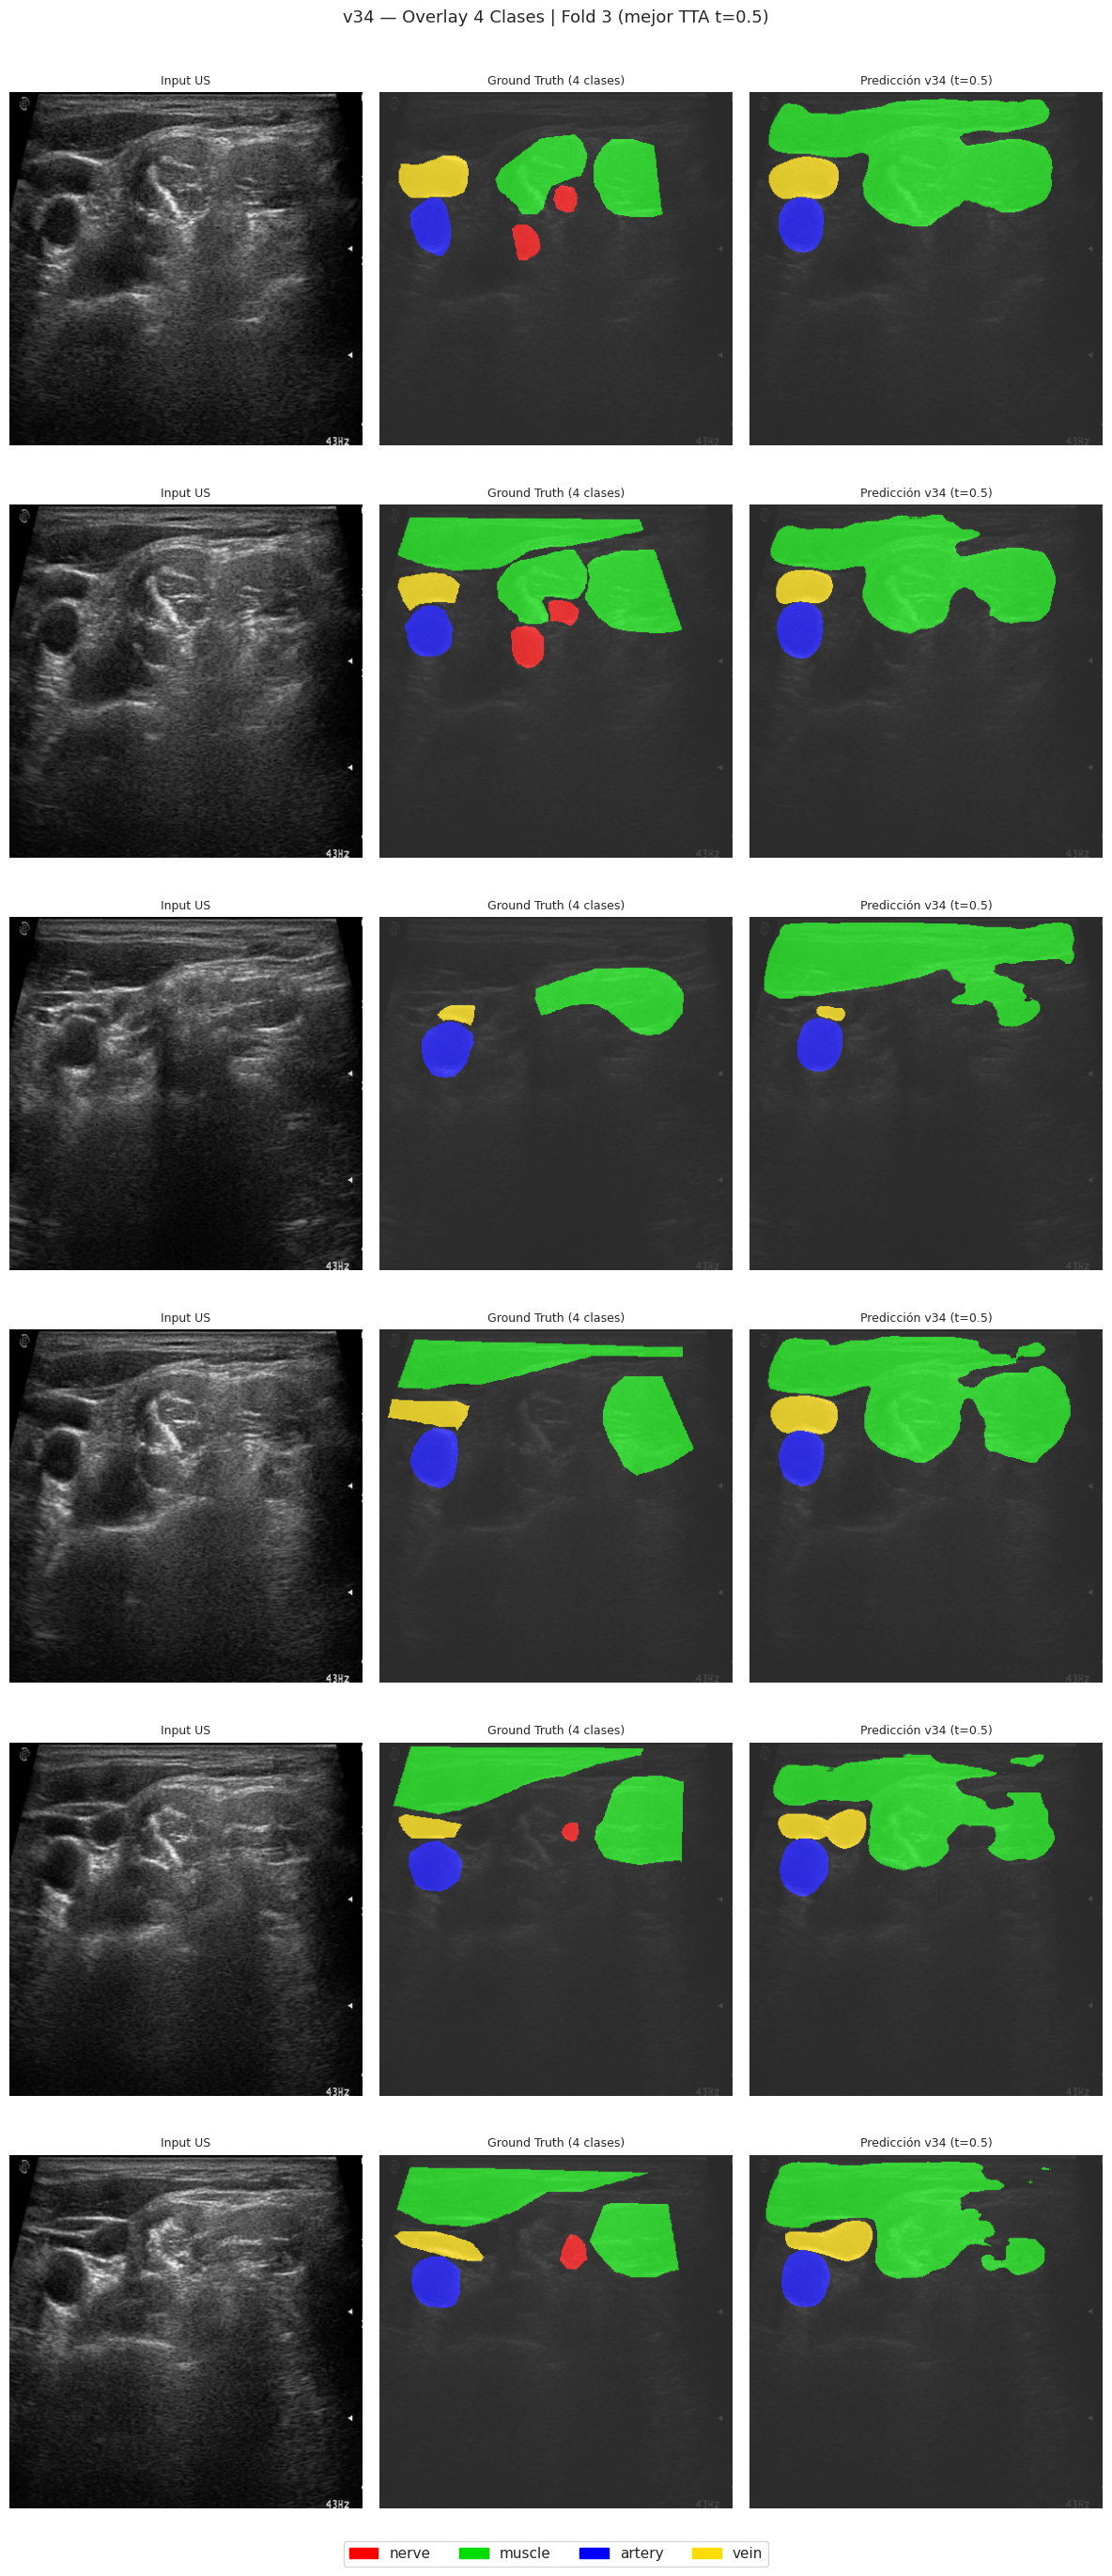

overlay_4classes_v34.png guardado ✅


In [ ]:

# ============================================================
# Overlay de 4 estructuras anatómicas — mejor fold (TTA t=0.5)
# v34: fold_mean/fold_std del historial — sin fallback a globales
# ============================================================

if fold_results_v34:
    best_fold_idx = max(
        range(N_FOLDS),
        key=lambda fi: fold_results_v34.get(f'fold_{fi}', {}).get(
            'tta', fold_results_v34.get(f'fold_{fi}', {}).get('base', {})
        ).get('dice', {}).get('mean', 0)
    )
else:
    best_fold_idx = 0
print(f'Usando fold {best_fold_idx+1} para overlay (mejor Dice TTA-hflip t={EVAL_THRESHOLD})')

h_key = f'fold_{best_fold_idx}'
fold_mean_v = all_fold_histories_viz.get(h_key, {}).get('fold_mean')
fold_std_v  = all_fold_histories_viz.get(h_key, {}).get('fold_std')
if fold_mean_v is None or fold_std_v is None:
    raise ValueError(f'fold_mean/fold_std no disponibles para fold {best_fold_idx} en historial.')

val_pairs_fold = [data_pairs[i] for i in FOLD_SPLITS[best_fold_idx][1]]
val_ds_viz = UBPDDataset(val_pairs_fold, get_val_transform(IMAGE_SIZE, fold_mean_v, fold_std_v))
val_loader_viz = DataLoader(val_ds_viz, batch_size=8, shuffle=False, num_workers=0)

ema_path  = os.path.join(CHECKPOINT_DIR, f'{MODEL_NAME}_fold{best_fold_idx}_best_ema.pth')
best_path = os.path.join(CHECKPOINT_DIR, f'{MODEL_NAME}_fold{best_fold_idx}_best.pth')
load_path = ema_path if os.path.exists(ema_path) else best_path

if not os.path.exists(load_path):
    raise FileNotFoundError(
        f'Checkpoint no encontrado para fold {best_fold_idx}: {load_path}\n'
        f'Asegúrate de que el entrenamiento se completó y los checkpoints están en: {CHECKPOINT_DIR}'
    )

model_viz = build_model().to(DEVICE)
ckpt = torch.load(load_path, map_location=DEVICE, weights_only=False)
model_viz.load_state_dict(ckpt['model_state_dict'])
model_viz.eval()

images_b, masks_b = next(iter(val_loader_viz))
with torch.inference_mode():
    logits_b = model_viz(images_b.to(DEVICE)).cpu()
probs_b = torch.sigmoid(logits_b)

N_SHOW = 6
fig, axes = plt.subplots(N_SHOW, 3, figsize=(12, 4.5*N_SHOW))
if N_SHOW == 1:
    axes = axes[np.newaxis, :]

for s in range(min(N_SHOW, images_b.shape[0])):
    img_np = denorm_img(images_b[s, 0], fold_mean_v, fold_std_v)

    axes[s, 0].imshow(img_np, cmap='gray')
    axes[s, 0].set_title('Input US', fontsize=9)
    axes[s, 0].axis('off')

    gt_rgb = mask_to_rgb(masks_b[s], threshold=EVAL_THRESHOLD)
    axes[s, 1].imshow(img_np, cmap='gray', alpha=0.45)
    axes[s, 1].imshow(gt_rgb, alpha=0.7)
    axes[s, 1].set_title('Ground Truth (4 clases)', fontsize=9)
    axes[s, 1].axis('off')

    pred_rgb = mask_to_rgb(probs_b[s], threshold=EVAL_THRESHOLD)
    axes[s, 2].imshow(img_np, cmap='gray', alpha=0.45)
    axes[s, 2].imshow(pred_rgb, alpha=0.7)
    axes[s, 2].set_title(f'Predicción v34 (t={EVAL_THRESHOLD})', fontsize=9)
    axes[s, 2].axis('off')

# Ocultar filas vacías si images_b tiene menos de N_SHOW imágenes
for s in range(images_b.shape[0], N_SHOW):
    for c_ax in range(3):
        axes[s, c_ax].set_visible(False)

fig.legend(handles=color_patches, loc='lower center', ncol=4, fontsize=11,
           bbox_to_anchor=(0.5, -0.01))
plt.suptitle(f'v34 — Overlay 4 Clases | Fold {best_fold_idx+1} (mejor TTA t={EVAL_THRESHOLD})',
             fontsize=13, y=1.001)
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, 'overlay_4classes_v34.png'),
            dpi=120, bbox_inches='tight')
plt.show()

del model_viz
torch.cuda.empty_cache()
print('overlay_4classes_v34.png guardado ✅')


### 19.3 Heatmaps Dice / IoU / HD95 por Clase y Fold

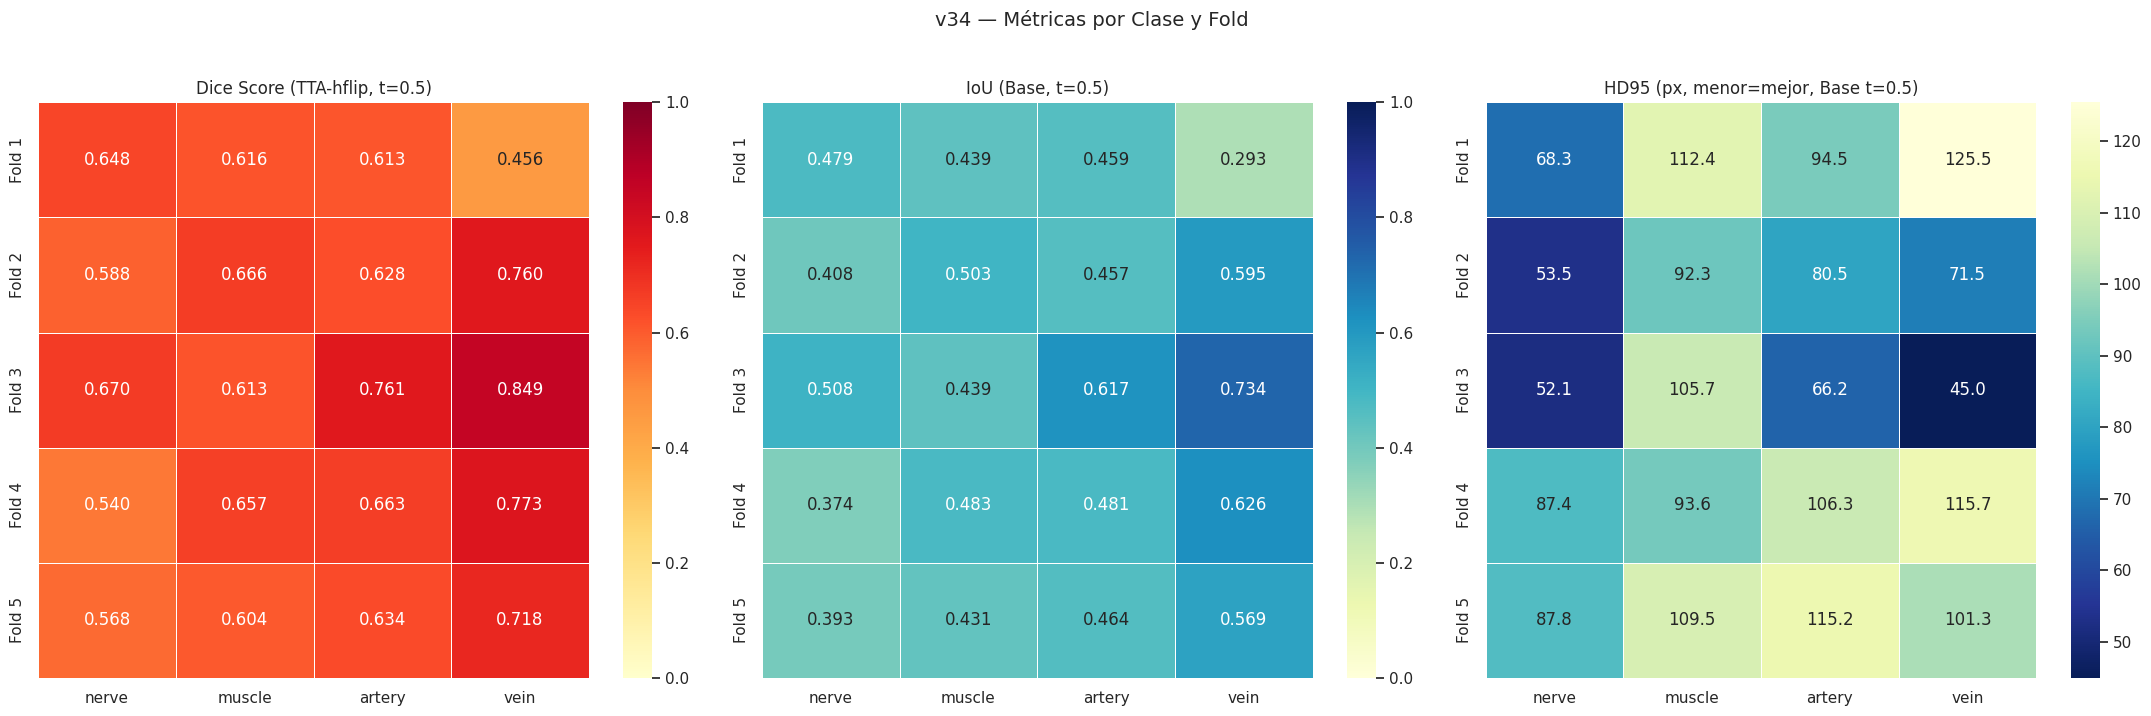

heatmaps_per_class_v34.png guardado ✅


In [ ]:

# ============================================================
# Heatmaps: Dice, IoU, HD95 — filas=folds, cols=clases
# v34: Dice de TTA (t=0.5), IoU/HD95 de base
# ============================================================

if not fold_results_v34:
    print('fold_results_v34 vacío — ejecutar evaluación primero')
else:
    n_folds_avail = len(fold_results_v34)
    fold_keys = sorted(fold_results_v34.keys())

    dice_mat  = np.zeros((n_folds_avail, NUM_CLASSES))
    iou_mat   = np.zeros((n_folds_avail, NUM_CLASSES))
    hd95_mat  = np.zeros((n_folds_avail, NUM_CLASSES))

    for fi, fk in enumerate(fold_keys):
        fd = fold_results_v34[fk]
        method_dice = fd.get('tta', fd.get('base', {}))
        method_full = fd.get('base', {})
        dice = method_dice.get('dice', {})
        iou  = method_full.get('iou', {})
        hd95 = method_full.get('hd95', {})
        for ci, c in enumerate(CLASS_NAMES):
            dice_mat[fi, ci] = dice.get(c, 0.0)
            iou_mat[fi, ci]  = iou.get(c, 0.0)
            h = hd95.get(c, 0.0)
            hd95_mat[fi, ci] = h if h < 300.0 else 300.0

    ylabels = [f'Fold {i+1}' for i in range(n_folds_avail)]

    fig, axes = plt.subplots(1, 3, figsize=(22, max(4, 1.4*n_folds_avail)))

    sns.heatmap(dice_mat, annot=True, fmt='.3f', cmap='YlOrRd',
                xticklabels=CLASS_NAMES, yticklabels=ylabels, ax=axes[0],
                vmin=0, vmax=1, linewidths=0.5)
    axes[0].set_title(f'Dice Score (TTA-hflip, t={EVAL_THRESHOLD})', fontsize=12)

    sns.heatmap(iou_mat, annot=True, fmt='.3f', cmap='YlGnBu',
                xticklabels=CLASS_NAMES, yticklabels=ylabels, ax=axes[1],
                vmin=0, vmax=1, linewidths=0.5)
    axes[1].set_title(f'IoU (Base, t={EVAL_THRESHOLD})', fontsize=12)

    sns.heatmap(hd95_mat, annot=True, fmt='.1f', cmap='YlGnBu_r',
                xticklabels=CLASS_NAMES, yticklabels=ylabels, ax=axes[2],
                linewidths=0.5)
    axes[2].set_title(f'HD95 (px, menor=mejor, Base t={EVAL_THRESHOLD})', fontsize=12)

    plt.suptitle('v34 — Métricas por Clase y Fold', fontsize=14, y=1.02)
    plt.tight_layout()
    plt.savefig(os.path.join(RESULTS_DIR, 'heatmaps_per_class_v34.png'),
                dpi=150, bbox_inches='tight')
    plt.show()
    print('heatmaps_per_class_v34.png guardado ✅')


### 19.4 Boxplot Dice Per-Image por Fold y Clase

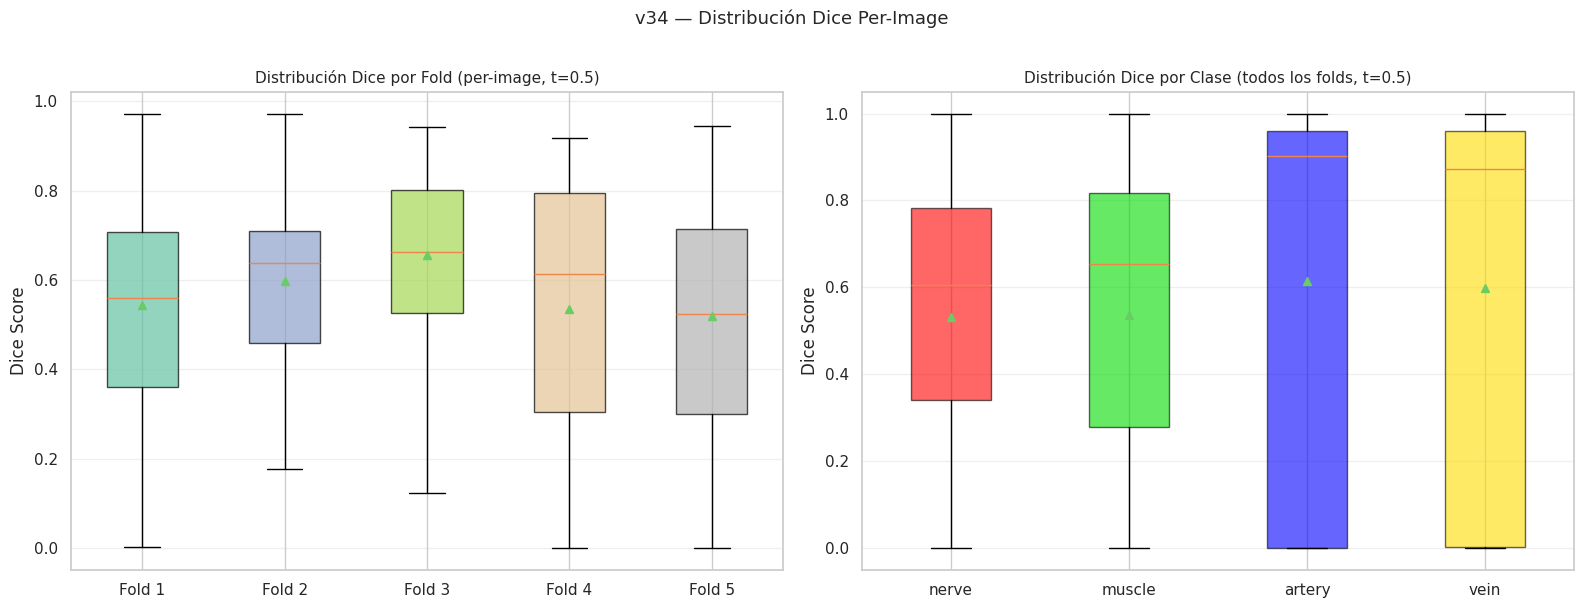

boxplot_dice_v34.png guardado ✅


In [ ]:
# ============================================================
# Boxplot Dice per-image — distribución por fold y por clase
# ============================================================

if not fold_results_v34:
    print('fold_results_v34 vacío — ejecutar evaluación primero')
else:
    per_fold_dice_mean = []
    per_fold_dice_by_class = {c: [] for c in CLASS_NAMES}
    fold_labels = []

    for fi, fk in enumerate(sorted(fold_results_v34.keys())):
        fd = fold_results_v34[fk]
        method = fd.get('tta', fd.get('base', {}))
        per_img = method.get('per_image_dice', fd.get('per_image_dice', []))
        if per_img:
            per_fold_dice_mean.append([d.get('mean', 0) for d in per_img])
            for c in CLASS_NAMES:
                per_fold_dice_by_class[c].append([d.get(c, 0) for d in per_img])
            fold_labels.append(f'Fold {fi+1}')

    if per_fold_dice_mean:
        fig, axes = plt.subplots(1, 2, figsize=(16, 6))

        bp1 = axes[0].boxplot(per_fold_dice_mean, labels=fold_labels,
                               patch_artist=True, showmeans=True)
        fold_colors = plt.cm.Set2(np.linspace(0, 1, len(fold_labels)))
        for patch, color in zip(bp1['boxes'], fold_colors):
            patch.set_facecolor(color)
            patch.set_alpha(0.7)
        axes[0].set_ylabel('Dice Score')
        axes[0].set_title(f'Distribución Dice por Fold (per-image, t={EVAL_THRESHOLD})', fontsize=11)
        axes[0].grid(True, alpha=0.3, axis='y')

        class_all = []
        for c in CLASS_NAMES:
            combined = []
            for fold_data in per_fold_dice_by_class[c]:
                combined.extend(fold_data)
            class_all.append(combined)

        bp2 = axes[1].boxplot(class_all, labels=CLASS_NAMES,
                               patch_artist=True, showmeans=True)
        for patch, color in zip(bp2['boxes'], CLASS_COLORS_FLOAT):
            patch.set_facecolor(color)
            patch.set_alpha(0.6)
        axes[1].set_ylabel('Dice Score')
        axes[1].set_title(f'Distribución Dice por Clase (todos los folds, t={EVAL_THRESHOLD})', fontsize=11)
        axes[1].grid(True, alpha=0.3, axis='y')

        plt.suptitle('v34 — Distribución Dice Per-Image', fontsize=13, y=1.01)
        plt.tight_layout()
        plt.savefig(os.path.join(RESULTS_DIR, 'boxplot_dice_v34.png'),
                    dpi=150, bbox_inches='tight')
        plt.show()
        print('boxplot_dice_v34.png guardado ✅')
    else:
        print('Per-image dice no disponible en fold_results_v34')


### 19.5 Heatmap Precision / Recall por Clase y Fold

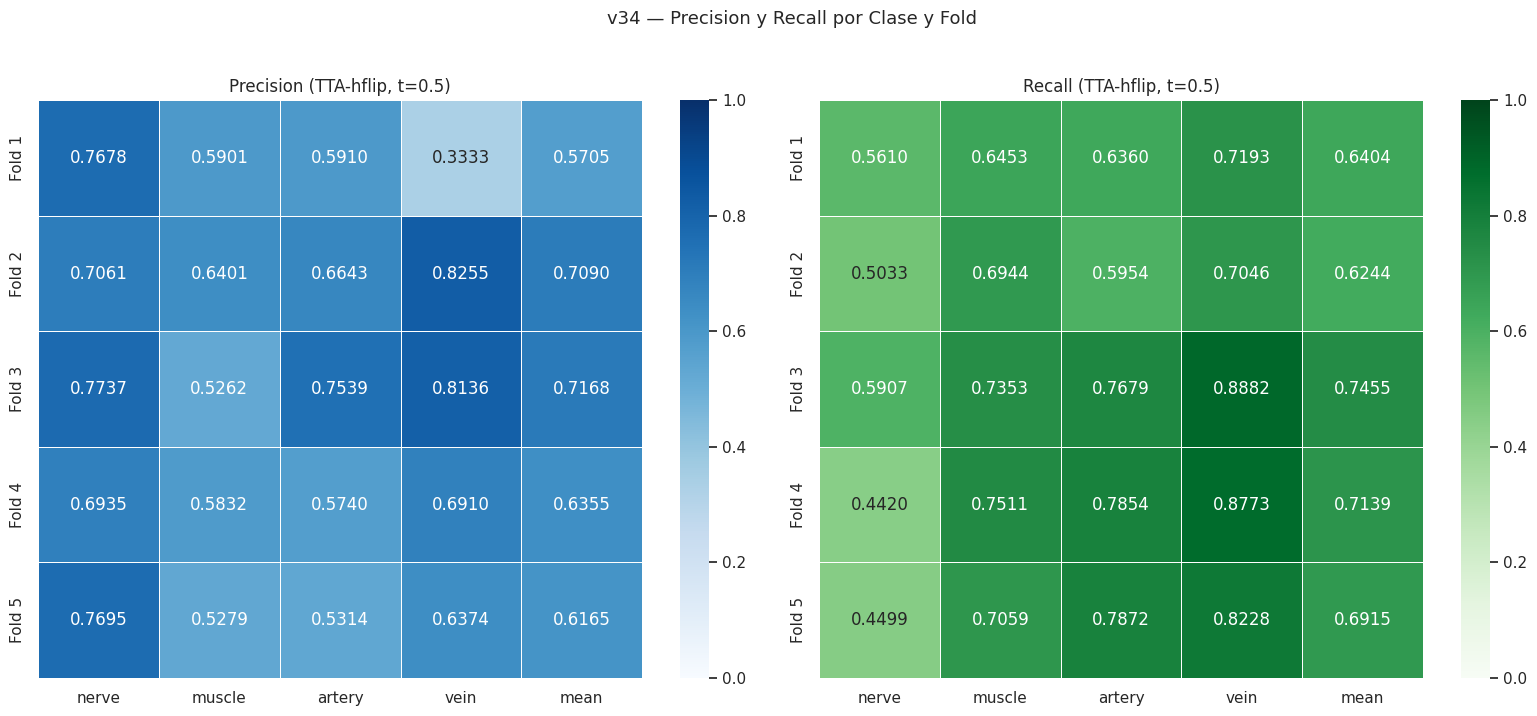

precision_recall_heatmap_v34.png guardado ✅


In [ ]:
# ============================================================
# Precision y Recall — heatmaps por fold × clase
# ============================================================

if not fold_results_v34:
    print('fold_results_v34 vacío — ejecutar evaluación primero')
else:
    n_folds_avail = len(fold_results_v34)
    fold_keys = sorted(fold_results_v34.keys())
    ylabels = [f'Fold {i+1}' for i in range(n_folds_avail)]

    prec_mat = np.zeros((n_folds_avail, NUM_CLASSES + 1))
    rec_mat  = np.zeros((n_folds_avail, NUM_CLASSES + 1))

    for fi, fk in enumerate(fold_keys):
        fd = fold_results_v34[fk]
        method = fd.get('tta', fd.get('base', {}))
        prec = method.get('precision', {})
        rec  = method.get('recall', {})
        for ci, c in enumerate(CLASS_NAMES):
            prec_mat[fi, ci] = prec.get(c, 0.0)
            rec_mat[fi, ci]  = rec.get(c, 0.0)
        prec_mat[fi, NUM_CLASSES] = prec.get('mean', 0.0)
        rec_mat[fi, NUM_CLASSES]  = rec.get('mean', 0.0)

    col_labels = CLASS_NAMES + ['mean']
    fig, axes = plt.subplots(1, 2, figsize=(16, max(4, 1.4*n_folds_avail)))

    sns.heatmap(prec_mat, annot=True, fmt='.4f', cmap='Blues',
                xticklabels=col_labels, yticklabels=ylabels, ax=axes[0],
                vmin=0, vmax=1, linewidths=0.5)
    axes[0].set_title(f'Precision (TTA-hflip, t={EVAL_THRESHOLD})', fontsize=12)

    sns.heatmap(rec_mat, annot=True, fmt='.4f', cmap='Greens',
                xticklabels=col_labels, yticklabels=ylabels, ax=axes[1],
                vmin=0, vmax=1, linewidths=0.5)
    axes[1].set_title(f'Recall (TTA-hflip, t={EVAL_THRESHOLD})', fontsize=12)

    plt.suptitle('v34 — Precision y Recall por Clase y Fold', fontsize=13, y=1.02)
    plt.tight_layout()
    plt.savefig(os.path.join(RESULTS_DIR, 'precision_recall_heatmap_v34.png'),
                dpi=150, bbox_inches='tight')
    plt.show()
    print('precision_recall_heatmap_v34.png guardado ✅')


### 19.6 Radar Chart Multi-Métrica por Fold

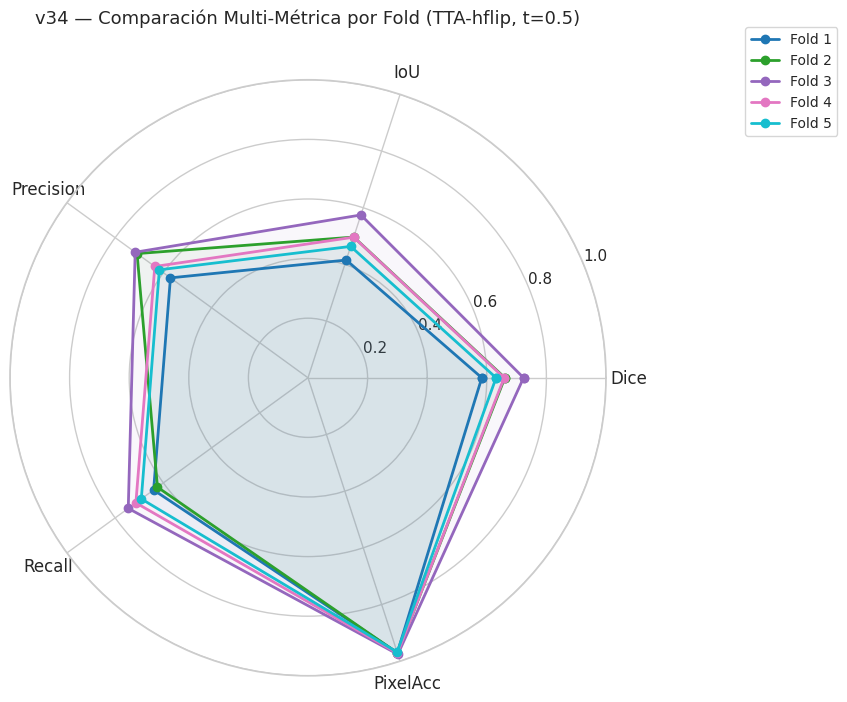

radar_chart_v34.png guardado ✅


In [ ]:
# ============================================================
# Radar Chart — Dice, IoU, Precision, Recall, PixelAcc por fold
# ============================================================
from math import pi

if not fold_results_v34:
    print('fold_results_v34 vacío — ejecutar evaluación primero')
else:
    metrics_labels = ['Dice', 'IoU', 'Precision', 'Recall', 'PixelAcc']
    N_metrics = len(metrics_labels)
    angles = [n / float(N_metrics) * 2 * pi for n in range(N_metrics)]
    angles += angles[:1]

    fig, ax = plt.subplots(figsize=(9, 9), subplot_kw=dict(polar=True))
    fold_colors_r = plt.cm.tab10(np.linspace(0, 0.9, N_FOLDS))

    for fi, fk in enumerate(sorted(fold_results_v34.keys())):
        fd = fold_results_v34[fk]
        method = fd.get('tta', fd.get('base', {}))
        values = [
            method.get('dice', {}).get('mean', 0),
            method.get('iou', {}).get('mean', 0),
            method.get('precision', {}).get('mean', 0),
            method.get('recall', {}).get('mean', 0),
            method.get('pixel_accuracy', 0),
        ]
        values += values[:1]
        ax.plot(angles, values, 'o-', linewidth=2, label=f'Fold {fi+1}',
                color=fold_colors_r[fi])
        ax.fill(angles, values, alpha=0.05, color=fold_colors_r[fi])

    ax.set_xticks(angles[:-1])
    ax.set_xticklabels(metrics_labels, fontsize=12)
    ax.set_ylim(0, 1)
    ax.set_title(f'v34 — Comparación Multi-Métrica por Fold (TTA-hflip, t={EVAL_THRESHOLD})', fontsize=13, y=1.08)
    ax.legend(loc='upper right', bbox_to_anchor=(1.4, 1.1), fontsize=10)
    ax.grid(True)

    plt.tight_layout()
    plt.savefig(os.path.join(RESULTS_DIR, 'radar_chart_v34.png'),
                dpi=150, bbox_inches='tight')
    plt.show()
    print('radar_chart_v34.png guardado ✅')


### 19.7 Comparación de Estrategias de Evaluación

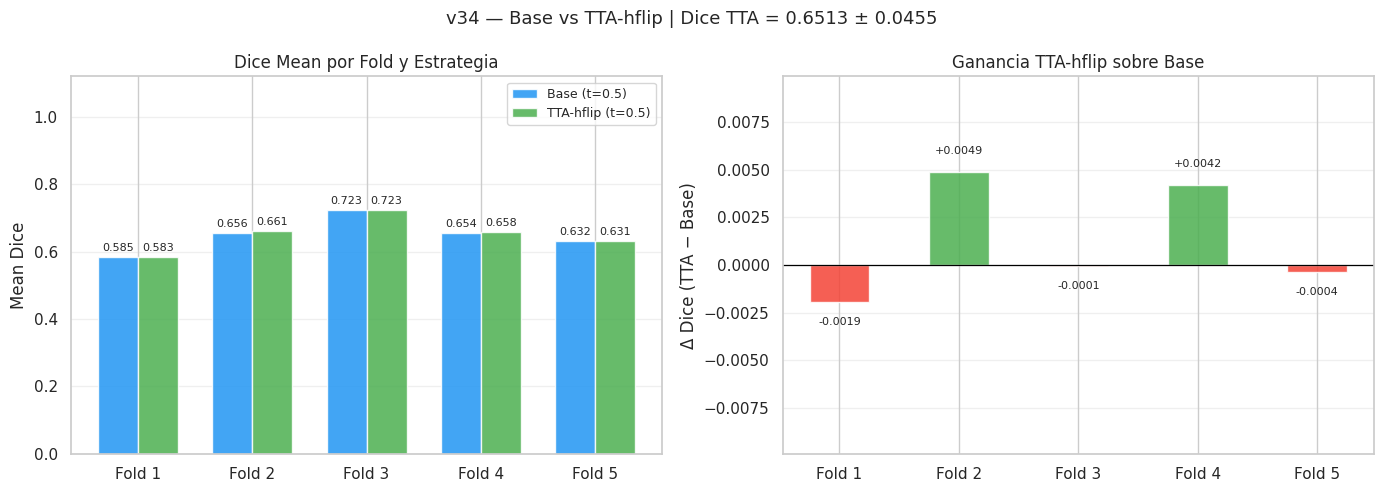

strategy_comparison_v34.png guardado ✅


In [ ]:

# ============================================================
# Comparación de estrategias: Base vs TTA-hflip — v34
# Barplot Dice mean por fold, agrupado por estrategia
# ============================================================

if not fold_results_v34:
    print('fold_results_v34 vacío — ejecutar evaluación primero')
else:
    strategies = [
        ('base', f'Base (t={EVAL_THRESHOLD})',      '#2196F3'),
        ('tta',  f'TTA-hflip (t={EVAL_THRESHOLD})', '#4CAF50'),
    ]

    fold_keys = sorted(fold_results_v34.keys())
    n_folds_avail = len(fold_keys)
    x = np.arange(n_folds_avail)
    width = 0.35

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # ── Subplot 1: Dice Mean por fold y estrategia ──────────────
    ax = axes[0]
    for si, (sk, slabel, sc) in enumerate(strategies):
        vals = []
        for fk in fold_keys:
            fd = fold_results_v34[fk]
            m = fd.get(sk, {})
            v = m.get('dice', {}).get('mean', 0)
            vals.append(v)
        offset = (si - len(strategies) / 2) * width + width / 2
        bars = ax.bar(x + offset, vals, width, label=slabel, color=sc, alpha=0.85)
        for bar, v in zip(bars, vals):
            ax.text(bar.get_x() + bar.get_width() / 2,
                    bar.get_height() + 0.012,
                    f'{v:.3f}', ha='center', va='bottom', fontsize=8)

    ax.set_xticks(x)
    ax.set_xticklabels([f'Fold {i+1}' for i in range(n_folds_avail)])
    ax.set_ylabel('Mean Dice')
    ax.set_title('Dice Mean por Fold y Estrategia')
    ax.legend(fontsize=9)
    ax.grid(True, axis='y', alpha=0.3)
    ax.set_ylim(0, 1.12)   # headroom para las etiquetas de valor

    # ── Subplot 2: Δ Dice (TTA - Base) por fold ──────────────
    ax2 = axes[1]
    deltas = []
    for fk in fold_keys:
        fd = fold_results_v34[fk]
        base_d = fd.get('base', {}).get('dice', {}).get('mean', 0)
        tta_d  = fd.get('tta',  fd.get('base', {})).get('dice', {}).get('mean', base_d)
        deltas.append(tta_d - base_d)

    colors_delta = ['#4CAF50' if d >= 0 else '#F44336' for d in deltas]
    bars2 = ax2.bar(x, deltas, 0.5, color=colors_delta, alpha=0.85)
    ax2.axhline(0, color='black', linewidth=0.9)

    for bar, d in zip(bars2, deltas):
        if d >= 0:
            ax2.text(bar.get_x() + bar.get_width() / 2,
                     bar.get_height() + 0.0008,
                     f'{d:+.4f}', ha='center', va='bottom', fontsize=8)
        else:
            ax2.text(bar.get_x() + bar.get_width() / 2,
                     bar.get_height() - 0.0008,
                     f'{d:+.4f}', ha='center', va='top', fontsize=8)

    ax2.set_xticks(x)
    ax2.set_xticklabels([f'Fold {i+1}' for i in range(n_folds_avail)])
    ax2.set_ylabel('Δ Dice (TTA − Base)')
    ax2.set_title('Ganancia TTA-hflip sobre Base')
    ax2.grid(True, axis='y', alpha=0.3)

    # Margen simétrico con mínimo visible
    max_abs_delta = max(abs(min(deltas)), abs(max(deltas))) if deltas else 0.01
    margin = max(max_abs_delta * 0.4, 0.005)
    ax2.set_ylim(-max_abs_delta - margin, max_abs_delta + margin)

    tta_means = [
        fold_results_v34[fk].get('tta', fold_results_v34[fk].get('base', {}))
                             .get('dice', {}).get('mean', 0)
        for fk in fold_keys
    ]
    fig.suptitle(
        f'v34 — Base vs TTA-hflip | Dice TTA = {np.mean(tta_means):.4f} ± {np.std(tta_means):.4f}',
        fontsize=13
    )
    plt.tight_layout()
    plt.savefig(os.path.join(RESULTS_DIR, 'strategy_comparison_v34.png'),
                dpi=150, bbox_inches='tight')
    plt.show()
    print('strategy_comparison_v34.png guardado ✅')


### 19.8 Eficiencia de Entrenamiento por Fold

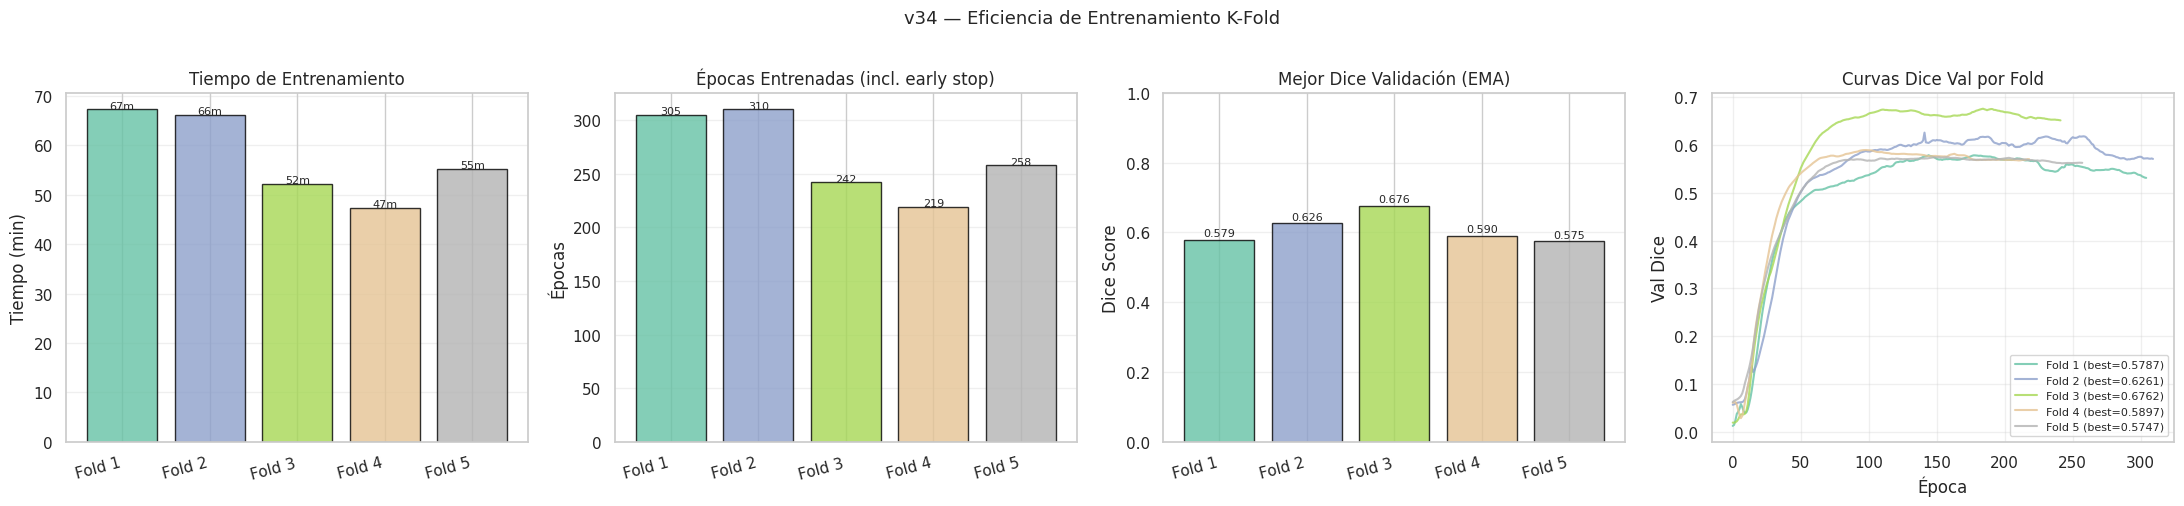

training_efficiency_v34.png guardado ✅


In [ ]:
# ============================================================
# Eficiencia de Entrenamiento: tiempo, épocas, best Dice, SWA
# ============================================================

if not all_fold_histories_viz:
    print('kfold_histories_v34 no disponible — entrenar primero')
else:
    fold_keys_h = sorted(all_fold_histories_viz.keys())
    n_f = len(fold_keys_h)
    x_pos = np.arange(n_f)
    fold_labels_h = [f'Fold {i+1}' for i in range(n_f)]
    fold_colors_h = plt.cm.Set2(np.linspace(0, 1, n_f))

    fig, axes = plt.subplots(1, 4, figsize=(22, 5))

    # Tiempo de entrenamiento
    times = [all_fold_histories_viz[k].get('training_time', 0)/60 for k in fold_keys_h]
    bars1 = axes[0].bar(x_pos, times, color=fold_colors_h, alpha=0.8, edgecolor='black')
    axes[0].set_ylabel('Tiempo (min)')
    axes[0].set_title('Tiempo de Entrenamiento')
    axes[0].set_xticks(x_pos); axes[0].set_xticklabels(fold_labels_h, rotation=15, ha='right')
    axes[0].grid(True, axis='y', alpha=0.3)
    for bar, val in zip(bars1, times):
        axes[0].text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.1,
                     f'{val:.0f}m', ha='center', fontsize=8)

    # Épocas entrenadas
    epochs_list = [all_fold_histories_viz[k].get('epochs_trained', 0) for k in fold_keys_h]
    bars2 = axes[1].bar(x_pos, epochs_list, color=fold_colors_h, alpha=0.8, edgecolor='black')
    axes[1].set_ylabel('Épocas')
    axes[1].set_title('Épocas Entrenadas (incl. early stop)')
    axes[1].set_xticks(x_pos); axes[1].set_xticklabels(fold_labels_h, rotation=15, ha='right')
    axes[1].grid(True, axis='y', alpha=0.3)
    for bar, val in zip(bars2, epochs_list):
        axes[1].text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.5,
                     str(val), ha='center', fontsize=8)

    # Mejor Dice validación
    best_dices = [all_fold_histories_viz[k].get('best_val_dice', 0) for k in fold_keys_h]
    bars3 = axes[2].bar(x_pos, best_dices, color=fold_colors_h, alpha=0.8, edgecolor='black')
    axes[2].set_ylabel('Dice Score')
    axes[2].set_title('Mejor Dice Validación (EMA)')
    axes[2].set_xticks(x_pos); axes[2].set_xticklabels(fold_labels_h, rotation=15, ha='right')
    axes[2].set_ylim(0, 1)
    axes[2].grid(True, axis='y', alpha=0.3)
    for bar, val in zip(bars3, best_dices):
        axes[2].text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.01,
                     f'{val:.3f}', ha='center', fontsize=8)

    # Curvas de Dice val superpuestas
    for fi, fk in enumerate(fold_keys_h):
        h = all_fold_histories_viz[fk]
        axes[3].plot(h['val_dice'], color=fold_colors_h[fi], alpha=0.8,
                     label=f'Fold {fi+1} (best={h["best_val_dice"]:.4f})')
    axes[3].set_xlabel('Época')
    axes[3].set_ylabel('Val Dice')
    axes[3].set_title('Curvas Dice Val por Fold')
    axes[3].legend(fontsize=8)
    axes[3].grid(True, alpha=0.3)

    plt.suptitle('v34 — Eficiencia de Entrenamiento K-Fold', fontsize=13, y=1.01)
    plt.tight_layout()
    plt.savefig(os.path.join(RESULTS_DIR, 'training_efficiency_v34.png'),
                dpi=150, bbox_inches='tight')
    plt.show()
    print('training_efficiency_v34.png guardado ✅')


## 20. Fin del Notebook v34

Archivos generados en `results_v34/`:
- `fold_results_v34.json` · `analysis_data_v34.json` · `diagnostic_v34.txt`
- `kfold_histories_v34.json` · `training_curves_v34.png`
- `predictions_comparison_v34.png` · `overlay_4classes_v34.png`
- `heatmaps_per_class_v34.png` · `strategy_comparison_v34.png`
